# scKNIFE: complete 10,000-cell Bassez tutorial

Analyze a representative sample of 10,000 cells, from parameter tuning to metabolic activity, factor interpretation and signaling.

**Workflow:** prepare inputs → tune on a representative subset → fit scKNIFE → examine cell-type retention → metabolic activity → factor interpretation → cell–cell signaling.

The primary fit uses parameters selected on a representative 2,000-cell subset before refitting all 10,000 cells. Factor interpretation groups the fitted factors into four consensus clusters (CC1–CC4); this is distinct from the model rank. Source cell types remain metadata for interpretation, not supervised training targets or newly assigned labels.

Use the Python 3.9 environment from the [installation guide](../docs/installation.md) and install the tutorial dependencies:

```bash
python -m pip install -e '.[tutorial]'
```

Follow [input preparation](../docs/tutorial-inputs.md) to obtain and convert the cohort-2 counts, matching metadata and pinned CellChat interaction export. Set `SCKNIFE_COUNTS`, `SCKNIFE_METADATA` and `SCKNIFE_INTERACTION_DB` before launching Jupyter, or set them in the first cell. Input data are not bundled with this notebook.

Open this notebook in Jupyter, or use `python scripts/run_tutorial.py` to save an executed copy. Choose a new output directory for a fresh analysis.

In [1]:
import os
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "graphs/version_1/unified_graph.graphml").exists())
os.chdir(ROOT)
# Uncomment and set your own input paths if not already set in the environment.
# os.environ["SCKNIFE_COUNTS"] = str(ROOT / "tutorial/inputs/bassez_cohort2_counts.h5ad")
# os.environ["SCKNIFE_METADATA"] = "/absolute/path/1871-BIOKEY_metaData_cohort2_web.csv"
# os.environ["SCKNIFE_INTERACTION_DB"] = str(ROOT / "tutorial/inputs/interactions.csv")
for name in ("SCKNIFE_COUNTS", "SCKNIFE_METADATA", "SCKNIFE_INTERACTION_DB"):
    if not os.environ.get(name) or not Path(os.environ[name]).is_file():
        raise FileNotFoundError(f"Set {name} to the prepared input file; see docs/tutorial-inputs.md")
os.environ.setdefault("SCKNIFE_TUTORIAL_OUTPUT", str(ROOT / "tutorial/outputs_10000"))
for name in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "NUMBA_NUM_THREADS"):
    os.environ.setdefault(name, "2")
os.environ["MPLBACKEND"] = "Agg"
from IPython.display import Image, display

def show_generated(relative_path):
    path = Path(os.environ["SCKNIFE_TUTORIAL_OUTPUT"]) / relative_path
    if not path.is_file():
        raise FileNotFoundError(f"Run the preceding analysis cell to generate {path.name}")
    display(Image(filename=str(path), width=850))

# Run full scKNIFE on 10,000 cells



## Purpose and inputs

Complete [Documentation](../docs/installation.md) and [Documentation](../docs/tutorial-inputs.md). Obtain the Bassez cohort-2 count matrix from the cited public source, its matching metadata CSV, and the directional CellChat interaction export. Use unnormalized nonnegative counts, gene symbols as variables and cell barcodes as observations. The metadata requires `patient_id`, `timepoint`, `BC_type` and `cellType`. `Pre` and `On` denote treatment timepoints; `expansion` (E/NE) is clonotype expansion, not clinical response.

If the source counts are RDS, convert them using the supplied R and Python helpers described in [Documentation](../docs/tutorial-inputs.md). A separate preselected dataset is not required. The full source pool has 50,693 cells, including 36,721 TNBC cells; these are input-pool sizes, not plotted-cell counts. Resource citations, versions and terms are listed in [Documentation](../docs/graph-resources.md).

## Sample and fit

Select the same 10,000 TNBC cells across patient × timepoint × source-cell-type strata with seed 42. Normalize each cell and log-transform expression. Before the full fit, tune on 2,000 representative cells, using 1,500 for fitting and 500 for validation. Select genes using only the fitting cells, lock the selected parameters, then refit all 10,000 cells with the selected graph.

Source cell types are used for stratified sampling and later interpretation; they are not targets for parameter selection or new labels assigned by scKNIFE.

## 1. Select the 10,000-cell sample

In [2]:
"""Fit the 10,000-cell sample, reconstruct activities and save the core outputs."""
import os, time, json, resource
from pathlib import Path
os.environ["MPLBACKEND"]="Agg"
os.environ.setdefault("SCKNIFE_TUTORIAL_OUTPUT", str(Path.cwd()/"tutorial/outputs_10000"))
started=time.perf_counter()
from pathlib import Path
import os
import numpy as np
import pandas as pd
import scipy.sparse as sp
import networkx as nx
import scanpy as sc
import matplotlib.pyplot as plt

plt.rcParams.update({"font.size": 12, "axes.titlesize": 14,
                     "axes.labelsize": 12, "xtick.labelsize": 11,
                     "ytick.labelsize": 11, "legend.fontsize": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
from IPython.display import display, Image
from scknife import (run_full_pipeline, compute_activity_scores,
    run_h_graph_clustering_fixed)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "graphs/version_1/unified_graph.graphml").exists())
OUT = Path(os.environ.get("SCKNIFE_TUTORIAL_OUTPUT", ROOT / "tutorial/outputs_10000"))
OUT.mkdir(parents=True, exist_ok=True)
SEED = 42
G = nx.read_graphml(ROOT / "graphs/version_1/unified_graph.graphml")
# %% Sample the cohort with authentic metadata
raw = sc.read_h5ad(os.environ["SCKNIFE_COUNTS"])
meta = pd.read_csv(os.environ["SCKNIFE_METADATA"], index_col=0)
assert raw.obs_names.is_unique and meta.index.is_unique
assert raw.obs_names.isin(meta.index).all()
raw.obs = meta.loc[raw.obs_names].copy()
raw = raw[raw.obs["BC_type"].eq("TNBC")].copy()
assert raw.n_obs >= 10000
strata = ["patient_id", "timepoint", "cellType"]
sizes = raw.obs.groupby(strata, observed=True, sort=True).size()
# Reserve one cell per stratum, then distribute the remaining budget proportionally.
assert len(sizes) < 10000
remaining = sizes - 1
quotas = (10000 - len(sizes)) * remaining / remaining.sum()
allocation = 1 + np.floor(quotas).astype(int)
extra = 10000 - int(allocation.sum())
allocation.loc[(quotas - np.floor(quotas)).sort_values(ascending=False, kind="stable").head(extra).index] += 1
rng = np.random.default_rng(SEED)
selected = []
for key, group in raw.obs.groupby(strata, observed=True, sort=True):
    selected.extend(rng.choice(group.index.to_numpy(), int(allocation.loc[key]), replace=False))
audit = pd.DataFrame({"cohort_cells": sizes, "tutorial_cells": allocation})
audit["cohort_fraction"] = sizes / sizes.sum()
audit["tutorial_fraction"] = allocation / 10000
audit.to_csv(OUT / "sampling_audit.csv")
raw = raw[sorted(selected)].copy()
assert raw.n_obs == 10000 and raw.obs_names.is_unique
raw.obs.to_csv(OUT / "sample_metadata.csv")
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
pd.crosstab(raw.obs.patient_id, raw.obs.timepoint).plot.bar(ax=axes[0], stacked=True)
axes[0].set_ylabel("Selected cells"); axes[0].set_title("Donor and treatment representation")
raw.obs.cellType.value_counts().plot.barh(ax=axes[1]); axes[1].set_title("Reference cell types")
fig.tight_layout(); fig.savefig(OUT / "sample_representation.png", dpi=160); plt.close(fig)
print("Selected cells × input genes:", raw.shape, flush=True)

Selected cells × input genes: (10000, 22889)


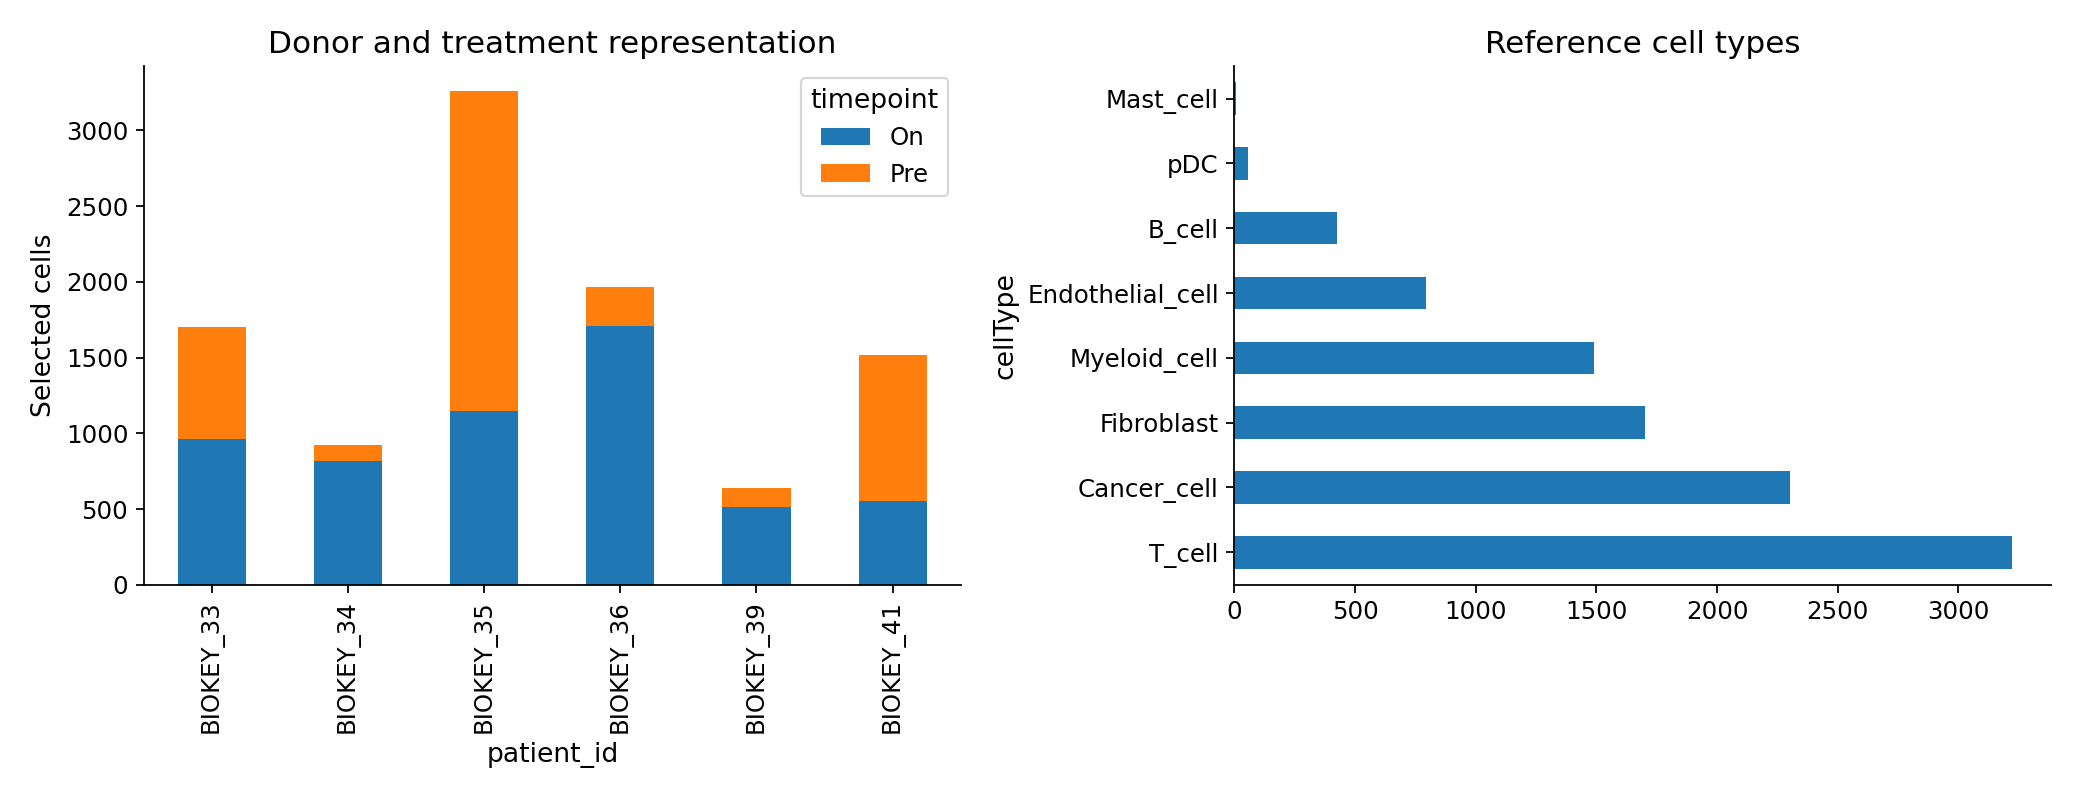

In [3]:
show_generated('sample_representation.png')

Patient, timepoint and source-cell-type composition of the 10,000-cell sample. All subsequent biological analyses use these same cell identifiers.

## 2. Prepare a representative tuning subset

Reserve representation across patient × timepoint × cell-type strata when sampling 2,000 cells. Split these into 1,500 fitting cells and 500 validation cells. A stratum with only one available cell stays in fitting. The exported membership and stratum tables make the split reproducible.

In [4]:
# %% Prepare expression

adata = raw.copy()
values = adata.X.data if sp.issparse(adata.X) else np.asarray(adata.X)
assert np.isfinite(values).all() and (values >= 0).all()
assert np.allclose(values, np.round(values)), "Supply unnormalized counts"
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
shared = adata.var_names.isin(G.nodes)
adata = adata[:, shared].copy()
# %% Tune on a representative subset before the full fit
from scipy.optimize import nnls
import itertools
TUNE = OUT / 'tuning'; TUNE.mkdir(exist_ok=True)
def stratified_sample(obs, number, seed, minimum=1):
    sizes = obs.groupby(strata, observed=True, sort=True).size()
    reserved = sizes.clip(upper=minimum)
    remaining = sizes - reserved
    assert reserved.sum() <= number <= sizes.sum()
    quota = (number - reserved.sum()) * remaining / remaining.sum()
    allocation = reserved + np.floor(quota).astype(int)
    extra = number - int(allocation.sum())
    allocation.loc[(quota - np.floor(quota)).sort_values(ascending=False, kind='stable').head(extra).index] += 1
    rng = np.random.default_rng(seed); ids = []
    for key, group in obs.groupby(strata, observed=True, sort=True):
        ids.extend(rng.choice(group.index.to_numpy(), int(allocation.loc[key]), replace=False))
    return sorted(ids)

tuning_ids = stratified_sample(adata.obs, 2000, SEED, minimum=2)
tuning_obs = adata.obs.loc[tuning_ids]
# Reserve one fitting cell in each stratum; select validation cells from the remainder.
reserved_train = stratified_sample(tuning_obs, len(tuning_obs.groupby(strata, observed=True)), SEED)
validation_pool = tuning_obs.drop(index=reserved_train)
validation_ids = stratified_sample(validation_pool, 500, SEED + 1)
training_ids = sorted(set(tuning_ids) - set(validation_ids))
assert len(training_ids) == 1500 and not set(training_ids) & set(validation_ids)
split = pd.Series('not used for tuning', index=adata.obs_names, name='tuning_split')
split.loc[training_ids] = 'fit'; split.loc[validation_ids] = 'validation'
adata.obs[strata].join(split).to_csv(TUNE / 'subset_membership.csv')
counts = adata.obs[strata].join(split).groupby(strata + ['tuning_split'], observed=True).size().unstack(fill_value=0)
counts.to_csv(TUNE / 'stratum_counts.csv')
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, key in zip(axes, ['patient_id', 'cellType']):
    comparison = pd.DataFrame({'All 10,000': adata.obs[key].value_counts(normalize=True),
        'Tuning 2,000': tuning_obs[key].value_counts(normalize=True),
        'Fit 1,500': adata.obs.loc[training_ids, key].value_counts(normalize=True),
        'Validation 500': adata.obs.loc[validation_ids, key].value_counts(normalize=True)}).fillna(0)
    comparison.plot.barh(ax=ax); ax.set_xlabel('Cell fraction'); ax.set_ylabel(''); ax.set_title(key)
fig.tight_layout(); fig.savefig(TUNE / 'subset_representation.png', dpi=160, bbox_inches='tight'); plt.close(fig)

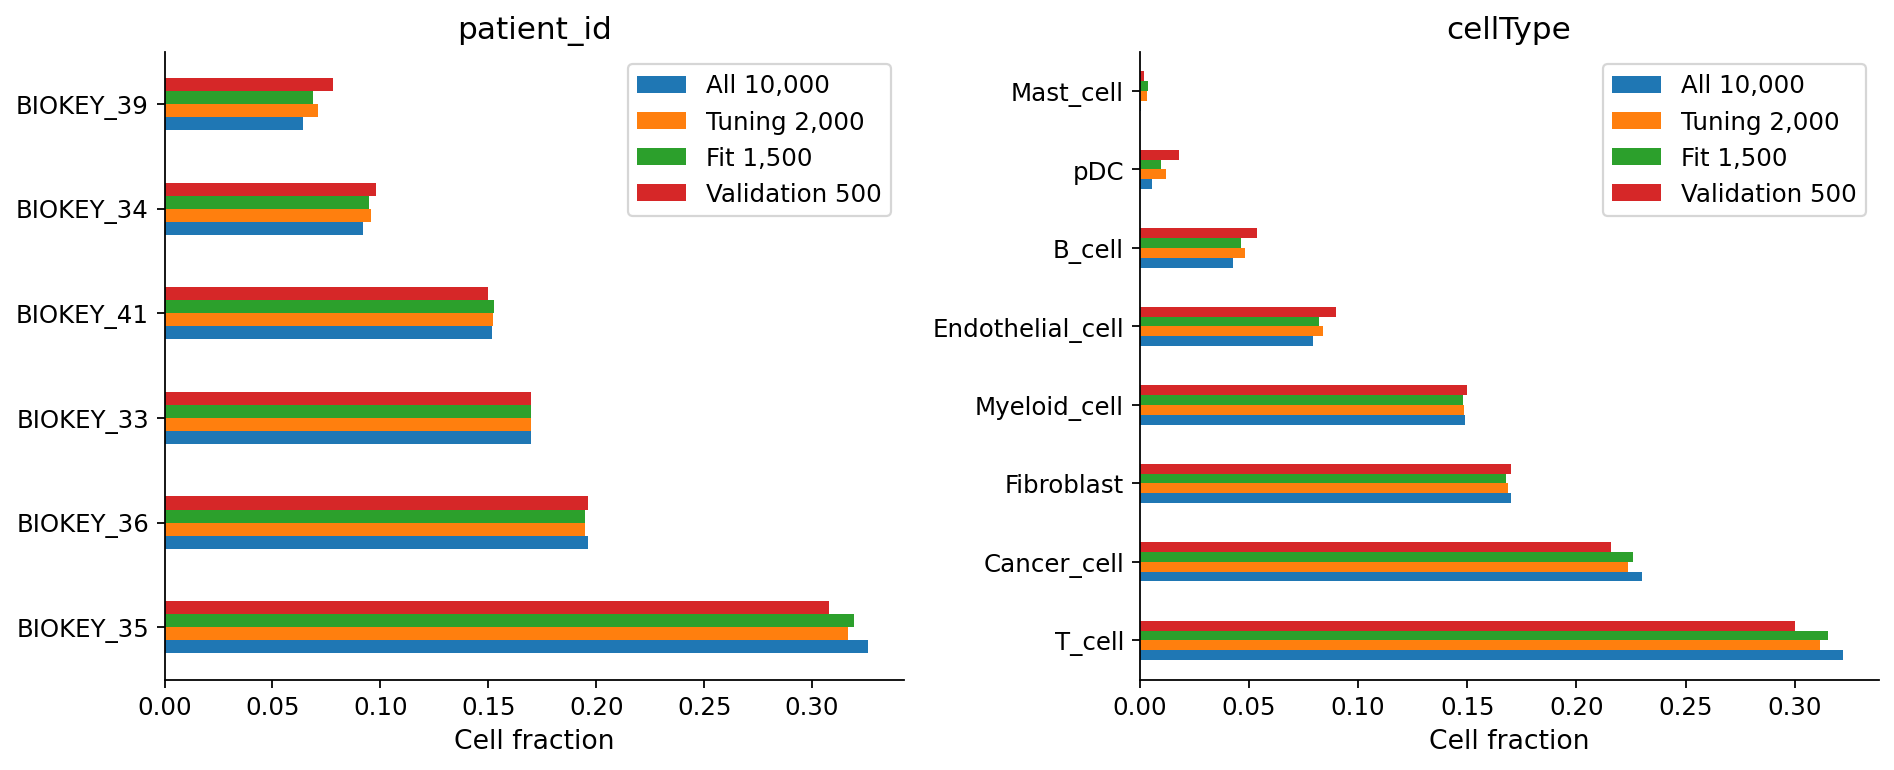

In [5]:
show_generated('tuning/subset_representation.png')

Cell fractions in the full sample, tuning subset and its fitting/validation partitions. Small strata are deliberately retained, so their proportions need not match exactly. This is a within-cohort split, not a held-out-patient evaluation.

## 3. Select model parameters

Select 2,000 graph-shared genes by mean expression in the 1,500 fitting cells only. Compare ranks 8, 16 and 24 with graph penalties 0.1, 1 and 10, then compare W and H penalties sequentially at 0.001, 0.01 and 0.1. Each candidate uses 100 updates and graph-H initialization seeds 42 and 43; the standard NMF initialization retains its fixed seed.

For each candidate, keep W fixed and project validation cells onto its expression basis. Lower relative reconstruction error, `||X − X̂|| / ||X||`, is better. Choose the smallest rank within 1% of the best mean rank/graph-grid error, then select each penalty by lowest mean error.

In [6]:
# Gene selection sees fitting cells only; validation cells do not influence it.
means = np.asarray(adata[training_ids].X.mean(axis=0)).ravel()
top = np.argsort(means, kind='stable')[-2000:]
adata = adata[:, np.sort(top)].copy()
assert adata.n_vars == 2000
pd.Series(adata.var_names, name='gene').to_csv(TUNE / 'selected_genes.csv', index=False)
tune_train = adata[training_ids].copy(); tune_validation = adata[validation_ids].copy()
validation_expression = tune_validation.X.toarray() if sp.issparse(tune_validation.X) else np.asarray(tune_validation.X)
SEEDS = (42, 43)
records = []; cache = {}
tuning_started = time.perf_counter()
def evaluate(params):
    key = tuple(params[x] for x in ['k', 'lambda_reg', 'beta_W', 'beta_H'])
    if key in cache:
        return cache[key]
    errors = []
    for seed in SEEDS:
        trial_started = time.perf_counter()
        model = run_full_pipeline(tune_train.copy(), G, **params, n_iter=100,
            tol=0, random_state=seed, verbose=False)
        assert model.var_names.equals(tune_validation.var_names)
        basis = np.asarray(model.uns['Rg'] @ model.uns['W_graph'])
        projected = np.column_stack([nnls(basis, x)[0] for x in validation_expression])
        error = float(np.linalg.norm(validation_expression - (basis @ projected).T) / np.linalg.norm(validation_expression))
        assert np.isfinite(error)
        records.append(dict(params, seed=seed, validation_error=error, seconds=time.perf_counter()-trial_started))
        pd.DataFrame(records).to_csv(TUNE / 'candidate_runs.csv', index=False)
        errors.append(error)
        print('TUNING', params, 'seed', seed, 'validation error', round(error, 6), flush=True)
        plt.close('all')
    result = dict(params, mean_error=float(np.mean(errors)), seed_sd=float(np.std(errors, ddof=1)))
    cache[key] = result
    return result

# Predeclared sequential search: rank/graph penalty, then W penalty, then H penalty.
joint = pd.DataFrame([evaluate({'k': k, 'lambda_reg': lam, 'beta_W': .01, 'beta_H': .01})
                      for k, lam in itertools.product([8, 16, 24], [.1, 1., 10.])])
# Prefer the smallest rank whose mean error is within 1% of the best tested error.
threshold = 1.01 * joint.mean_error.min()
chosen = joint[joint.mean_error <= threshold].sort_values(['k', 'mean_error', 'lambda_reg']).iloc[0]
selected_params = {key: int(chosen[key]) if key == 'k' else float(chosen[key]) for key in ['k','lambda_reg','beta_W','beta_H']}
penalty_sweeps = {}
for penalty in ['beta_W', 'beta_H']:
    table = pd.DataFrame([evaluate(dict(selected_params, **{penalty: value})) for value in [.001, .01, .1]])
    best = table.sort_values(['mean_error', penalty]).iloc[0]
    selected_params[penalty] = float(best[penalty]); penalty_sweeps[penalty] = table
    table.to_csv(TUNE / (penalty + '_sweep.csv'), index=False)
joint.to_csv(TUNE / 'rank_graph_sweep.csv', index=False)
pd.DataFrame(cache.values()).to_csv(TUNE / 'candidate_summary.csv', index=False)
(TUNE / 'selected_params.json').write_text(json.dumps(selected_params, indent=2))
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for lam, frame in joint.groupby('lambda_reg'):
    axes[0].errorbar(frame.k, frame.mean_error, yerr=frame.seed_sd, marker='o', capsize=3, label=f'lambda={lam:g}')
axes[0].axhline(threshold, color='grey', ls=':', label='1% selection band')
axes[0].axvline(selected_params['k'], color='#9b456b', ls='--')
axes[0].set(xlabel='Factors', ylabel='Relative validation reconstruction error', title='Rank and graph penalty', xticks=[8,16,24]); axes[0].legend(fontsize=9)
for ax, name in zip(axes[1:], ['beta_W','beta_H']):
    frame=penalty_sweeps[name]
    ax.errorbar(frame[name], frame.mean_error, yerr=frame.seed_sd, marker='o', capsize=3)
    ax.axvline(selected_params[name], color='#9b456b', ls='--'); ax.set_xscale('log')
    ax.set(xlabel=name, ylabel='Relative validation reconstruction error', title=name + ' (sequential sweep)')
    ax.set_ylim(axes[0].get_ylim())
fig.tight_layout(); fig.savefig(TUNE / 'parameter_selection.png', dpi=160, bbox_inches='tight'); plt.close(fig)
summary = {'tuning_cells':2000, 'fitting_cells':1500, 'validation_cells':500,
    'strata_in_full_sample':int(adata.obs.groupby(strata, observed=True).ngroups),
    'strata_in_tuning':int(tuning_obs.groupby(strata, observed=True).ngroups),
    'genes_selected_on_fitting_cells_only':True, 'seeds':list(SEEDS), 'iterations':100,
    'candidate_fits':len(records), 'selected_params':selected_params,
    'selected_validation_error':evaluate(selected_params)['mean_error'],
    'seconds':time.perf_counter()-tuning_started,
    'selection_rule':'Smallest rank within 1% of best joint-grid validation error; sequential penalties minimize mean error.'}
(TUNE / 'tuning_report.json').write_text(json.dumps(summary, indent=2))
print('LOCKED PARAMETERS', selected_params, flush=True)

Starting Full scKNIFE (Graph-Regularized NMF) Pipeline...
Params - k=8, lambda=0.1, beta_W=0.01, beta_H=0.01, Iterations=100



Building gene-to-KG node mapping (Rg)...
Mapped 2000 genes to KG nodes.


Running scKNIFE Graph-Regularized NMF on CPU...
Epoch 0: Normalized Loss = 0.226465


Epoch 99: Normalized Loss = 0.185535
Storing H_graph components in adata.obs...
Stored W_graph in `adata.uns['W_graph']` (0.185535 final normalized loss)
Stored H_graph components in `adata.obs`
Running Standard NMF...


Storing H_std components in adata.obs...
Stored W_std in `adata.uns['W_std']`
Stored H_std components in `adata.obs`
Std NMF -> Corr: 0.7091, Frobenius: 1227.78, Relative: 0.6084

Standard NMF:
   Pearson Correlation     : 0.7091
   Frobenius Error         : 1227.7822
   Relative Frobenius Error: 0.6084

scKNIFE (Graph-Regularized NMF):
   Pearson Correlation     : 0.7086
   Frobenius Error         : 1228.5497
   Relative Frobenius Error: 0.6087

Pipeline complete!
Results stored in `adata.obs` and `adata.uns`:
   - `W_std`, `W_graph`
   - `H_std_{i}`, `H_graph_{i}`
   - `loss_history`
   - `Rg`, `node_names`



...

Running scKNIFE Graph-Regularized NMF on CPU...
Epoch 0: Normalized Loss = 0.224635


Epoch 99: Normalized Loss = 0.172366
Storing H_graph components in adata.obs...
Stored W_graph in `adata.uns['W_graph']` (0.172366 final normalized loss)
Stored H_graph components in `adata.obs`
Running Standard NMF...


Storing H_std components in adata.obs...
Stored W_std in `adata.uns['W_std']`
Stored H_std components in `adata.obs`
Std NMF -> Corr: 0.7345, Frobenius: 1181.92, Relative: 0.5856

Standard NMF:
   Pearson Correlation     : 0.7345
   Frobenius Error         : 1181.9203
   Relative Frobenius Error: 0.5856

scKNIFE (Graph-Regularized NMF):
   Pearson Correlation     : 0.7339
   Frobenius Error         : 1182.9297
   Relative Frobenius Error: 0.5861

Pipeline complete!
Results stored in `adata.obs` and `adata.uns`:
   - `W_std`, `W_graph`
   - `H_std_{i}`, `H_graph_{i}`
   - `loss_history`
   - `Rg`, `node_names`



TUNING {'k': 24, 'lambda_reg': 0.1, 'beta_W': 0.001, 'beta_H': 0.1} seed 43 validation error 0.598363


LOCKED PARAMETERS {'k': 24, 'lambda_reg': 0.1, 'beta_W': 0.001, 'beta_H': 0.1}


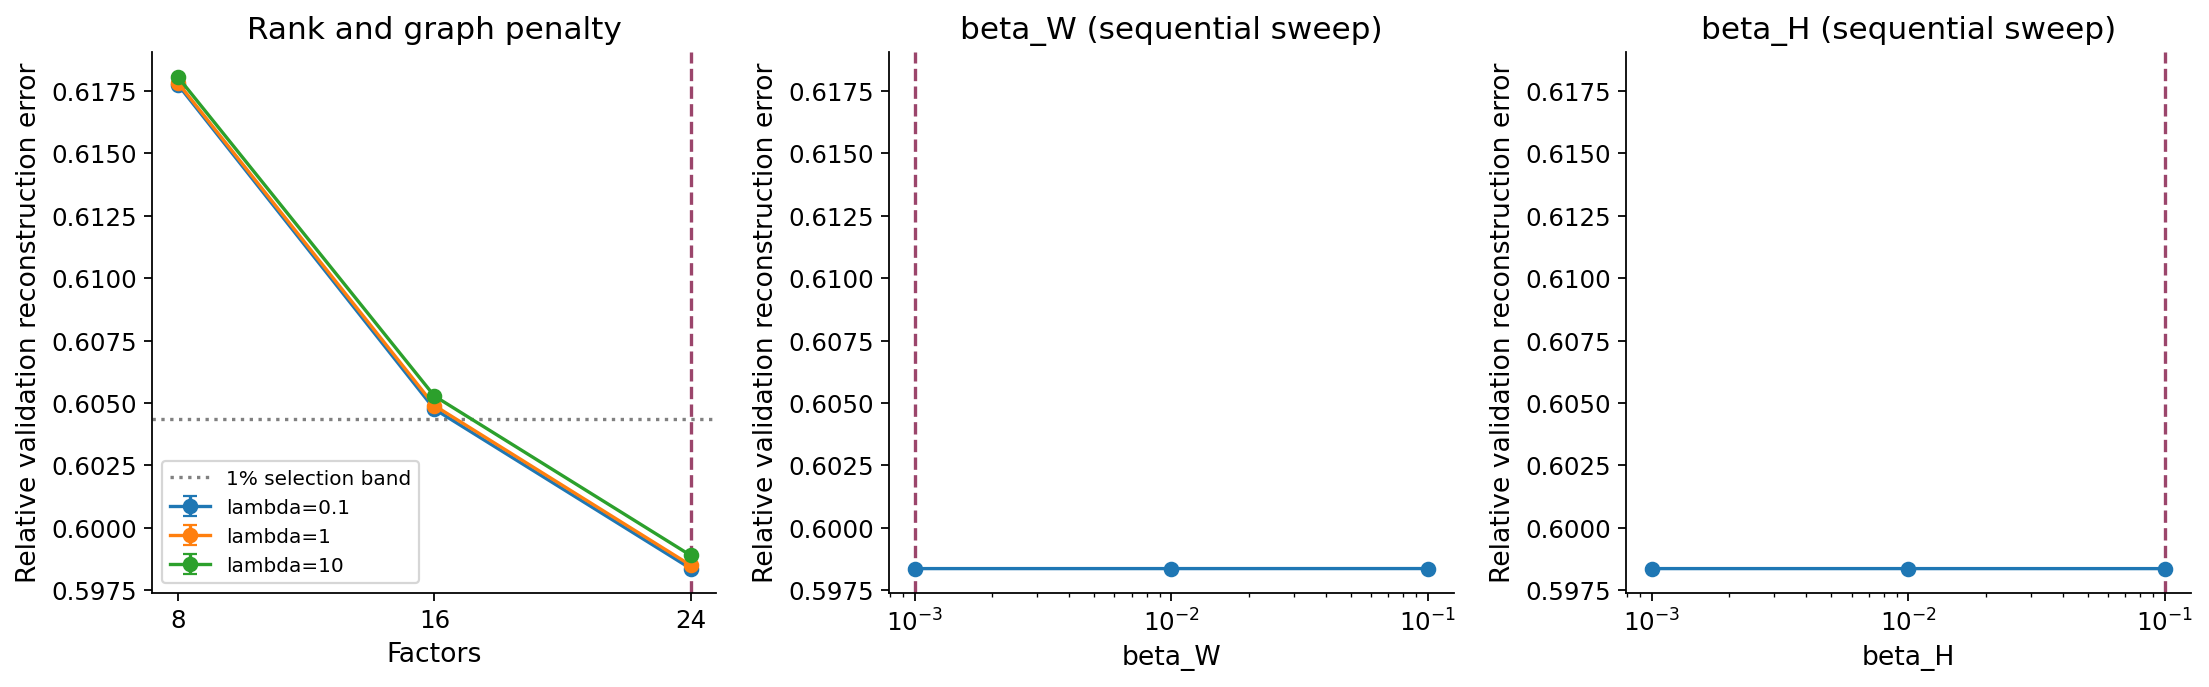

In [7]:
show_generated('tuning/parameter_selection.png')

Validation reconstruction error across tested settings. Error bars show variation across two initialization seeds, not patient uncertainty. Dashed vertical lines mark the selected settings; the dotted horizontal line marks the 1% rank-selection band.

**Example run:** the tuning subset retains all 86 sampling strata. Validation includes all eight cell types; ten singleton strata remain fitting-only. The search evaluates 13 settings across two seeds.

| Model rank | Best mean validation error on the rank/graph grid |
| --- | ---: |
| 8 | 0.617757 |
| 16 | 0.604760 |
| 24 | 0.598369 |

The 1% threshold is 0.604352; rank 16 falls just outside it. The selected settings are **rank 24, graph penalty 0.1, W penalty 0.001 and H penalty 0.1**, with final mean validation error **0.598367**. Rank has the largest effect here; W/H penalty differences are smaller than seed-to-seed variation. Adjust the candidate grids above to compare other settings.

Tuning took approximately **327 seconds** on the tested machine. Download the [candidate results](../docs/downloads/tuning_candidate_runs.csv) and [tuning report](../docs/downloads/tutorial_tuning_report.json) for the complete record.

Validation cells guide parameter selection and join the final 10,000-cell refit. These values report tuning performance within the tested grid.

## 4. Fit all 10,000 cells with the selected settings

In [8]:
# %% Fit the graph model
fit = run_full_pipeline(adata.copy(), G, **selected_params, n_iter=100, tol=0, random_state=SEED, verbose=False)

plt.close("all")
plt.figure(figsize=(7, 4))
plt.plot(np.arange(1, len(fit.uns["loss_history"]) + 1), fit.uns["loss_history"])
plt.xlabel("Iteration")
plt.ylabel("Normalized optimization objective")
plt.tight_layout()
plt.savefig(OUT / "convergence.png", dpi=150)
plt.show()

Starting Full scKNIFE (Graph-Regularized NMF) Pipeline...
Params - k=24, lambda=0.1, beta_W=0.001, beta_H=0.1, Iterations=100



Building gene-to-KG node mapping (Rg)...
Mapped 2000 genes to KG nodes.


Running scKNIFE Graph-Regularized NMF on CPU...
Epoch 0: Normalized Loss = 0.225461


Epoch 99: Normalized Loss = 0.176035
Storing H_graph components in adata.obs...
Stored W_graph in `adata.uns['W_graph']` (0.176035 final normalized loss)
Stored H_graph components in `adata.obs`
Running Standard NMF...


Storing H_std components in adata.obs...
Stored W_std in `adata.uns['W_std']`
Stored H_std components in `adata.obs`
Std NMF -> Corr: 0.7288, Frobenius: 3079.34, Relative: 0.5917



Standard NMF:
   Pearson Correlation     : 0.7288
   Frobenius Error         : 3079.3426
   Relative Frobenius Error: 0.5917

scKNIFE (Graph-Regularized NMF):
   Pearson Correlation     : 0.7279
   Frobenius Error         : 3083.7323
   Relative Frobenius Error: 0.5926

Pipeline complete!
Results stored in `adata.obs` and `adata.uns`:
   - `W_std`, `W_graph`
   - `H_std_{i}`, `H_graph_{i}`
   - `loss_history`
   - `Rg`, `node_names`



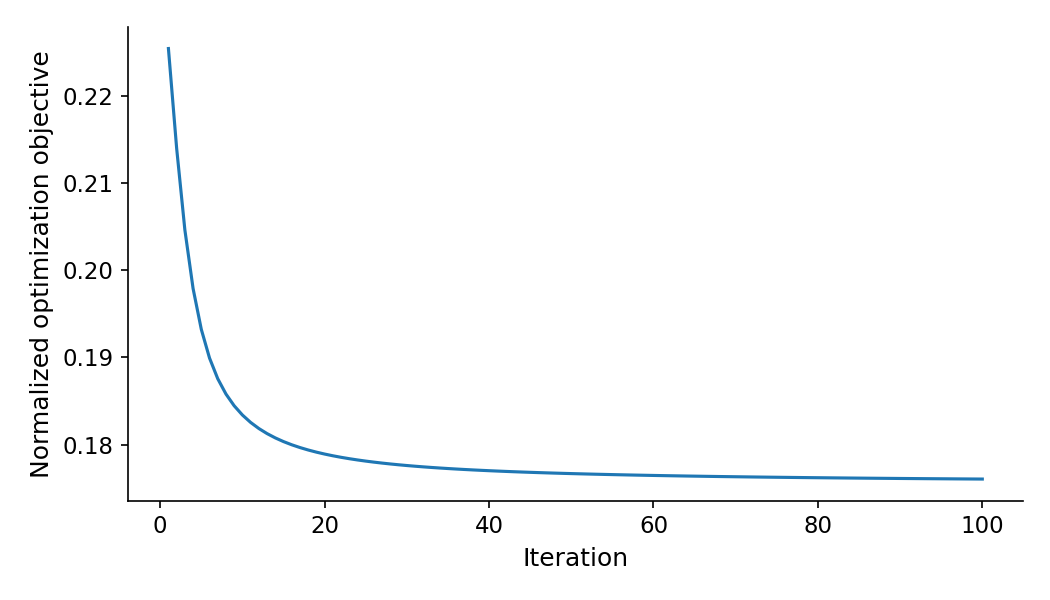

In [9]:
show_generated('convergence.png')

The curve shows the optimization objective during the full 10,000-cell fit. It combines reconstruction error and regularization; lower values indicate progress on that objective.

## 5. Reconstruct and save activities

In [10]:
# %% Cluster the learned cell representation
fit, clustering = run_h_graph_clustering_fixed(fit, pca_dims=6,
    n_neighbors=15, resolution=0.5, random_state=SEED)
assert np.isfinite(fit.uns["W_graph"]).all()
assert len(fit.uns["loss_history"]) == 100
clustering.to_csv(OUT / "clustering.csv", index=False)
display(clustering)

fit = compute_activity_scores(fit, batch_size=256)
activity = fit.uns["activity_scores"]
assert activity.shape == (G.number_of_nodes(), fit.n_obs)
assert activity.columns.equals(fit.obs_names)
def nodes_of_kind(kind):
    return [n for n, attrs in G.nodes(data=True) if attrs.get("kind") == kind]
# Retain the original supplied cell identities; clustering does not assign cell types.
assert fit.obs["cellType"].astype(str).equals(raw.obs.loc[fit.obs_names,"cellType"].astype(str))
# %% Export and verify results
activity.to_parquet(OUT / "activity_scores.parquet")
fit.obs.to_csv(OUT / "cell_annotations.csv")
fit.uns.pop("activity_scores", None)
fit.write_h5ad(OUT / "fitted_subset.h5ad")
reloaded = sc.read_h5ad(OUT / "fitted_subset.h5ad")
assert reloaded.shape == fit.shape
assert reloaded.uns["W_graph"].shape == (G.number_of_nodes(), selected_params["k"])
print("Tutorial completed; results saved to the configured output directory.")
report={"cells":int(fit.n_obs),"genes":int(fit.n_vars),"elapsed_seconds":time.perf_counter()-started,"peak_rss_native_units":resource.getrusage(resource.RUSAGE_SELF).ru_maxrss,"peak_rss_units":"KiB on Linux; bytes on macOS"}
assert fit.n_obs==10000
(OUT/"tutorial_run_report.json").write_text(json.dumps(report,indent=2))
print(report)

import hashlib, platform, importlib.metadata
report.update({"seed": SEED, "rank": selected_params["k"], "selected_params": selected_params, "iterations": 100, "python": platform.python_version(),
 "versions": {p: importlib.metadata.version(p) for p in ["numpy", "pandas", "scanpy", "scipy", "scikit-learn"]},
 "graph_sha256": hashlib.sha256((ROOT / "graphs/version_1/unified_graph.graphml").read_bytes()).hexdigest()})
(OUT / "tutorial_run_report.json").write_text(json.dumps(report, indent=2))

,n_clusters,best_pca_dims,best_n_neighbors,best_resolution,metric,random_state,silhouette
0,15,6,15,0.5,cosine,42,0.464187


Computing activity scores from W and H...
  Activity batch 1/40: cells 0-256


  Activity batch 2/40: cells 256-512
  Activity batch 3/40: cells 512-768


  Activity batch 4/40: cells 768-1024
  Activity batch 5/40: cells 1024-1280


  Activity batch 6/40: cells 1280-1536
  Activity batch 7/40: cells 1536-1792


...

  Activity batch 36/40: cells 8960-9216
  Activity batch 37/40: cells 9216-9472


  Activity batch 38/40: cells 9472-9728
  Activity batch 39/40: cells 9728-9984


  Activity batch 40/40: cells 9984-10000
Stored activity scores in `adata.uns['activity_scores']`


Tutorial completed; results saved to the configured output directory.
{'cells': 10000, 'genes': 2000, 'elapsed_seconds': 437.4993552058004, 'peak_rss_native_units': 3755600, 'peak_rss_units': 'KiB on Linux; bytes on macOS'}


566

Expected outputs include `fitted_subset.h5ad`, `activity_scores.parquet`, `sample_metadata.csv`, `cell_annotations.csv`, and the `tuning/` tables, plots and selected-parameter record.

## Continue with the fitted outputs

The saved object contains cell factors H and node loadings W. The activity table contains graph nodes × cells. Next examine [cell-type retention](../docs/tutorials/10000-annotation.md), then [metabolism](../docs/tutorials/10000-metabolic.md), [factors](../docs/tutorials/10000-factors.md) and [cell–cell signaling](../docs/tutorials/10000-signaling.md).

# Cell-type retention



Inspect cell-type organization in the fitted representation using two views of the same cells.

## Biological question

Compare H-space clusters with the dataset’s existing cell-type labels. The model fits expression with the knowledge graph; source labels are used for sampling and visualization.

scKNIFE does not assign cell-type labels in this tutorial.

## Inputs and code

Load the H-space clusters, UMAP coordinates and source cell-type labels saved during [model fitting](../docs/tutorials/10000-setup.md).

## Compare the learned organization with source labels

In [11]:
import os
from pathlib import Path
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt

plt.rcParams.update({"font.size": 12, "axes.titlesize": 14,
                     "axes.labelsize": 12, "xtick.labelsize": 11,
                     "ytick.labelsize": 11, "legend.fontsize": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
base = Path(os.environ.get("SCKNIFE_TUTORIAL_OUTPUT", "tutorial/outputs_10000"))
adata = sc.read_h5ad(base / "fitted_subset.h5ad")
assert adata.n_obs == 10000 and adata.obs_names.is_unique
assert adata.obs[["leiden_clusters", "cellType"]].notna().all().all()
clusters = adata.obs["leiden_clusters"].astype(str)
adata.obs["leiden_clusters"] = pd.Categorical(clusters)
out = base / "cellular_organization"
out.mkdir(exist_ok=True)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, key, title in zip(axes, ["leiden_clusters", "cellType"],
                        ["H-space clusters", "Source cell-type annotations"]):
    sc.pl.umap(adata, color=key, ax=ax, show=False, frameon=False, title=title)
fig.tight_layout()
fig.savefig(out / "organization_umap.png", dpi=160, bbox_inches="tight")
plt.close(fig)

<environment>/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1251: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
<environment>/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
<environment>/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1251: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
<environment>/lib/python3.9/site-packages/scanpy/

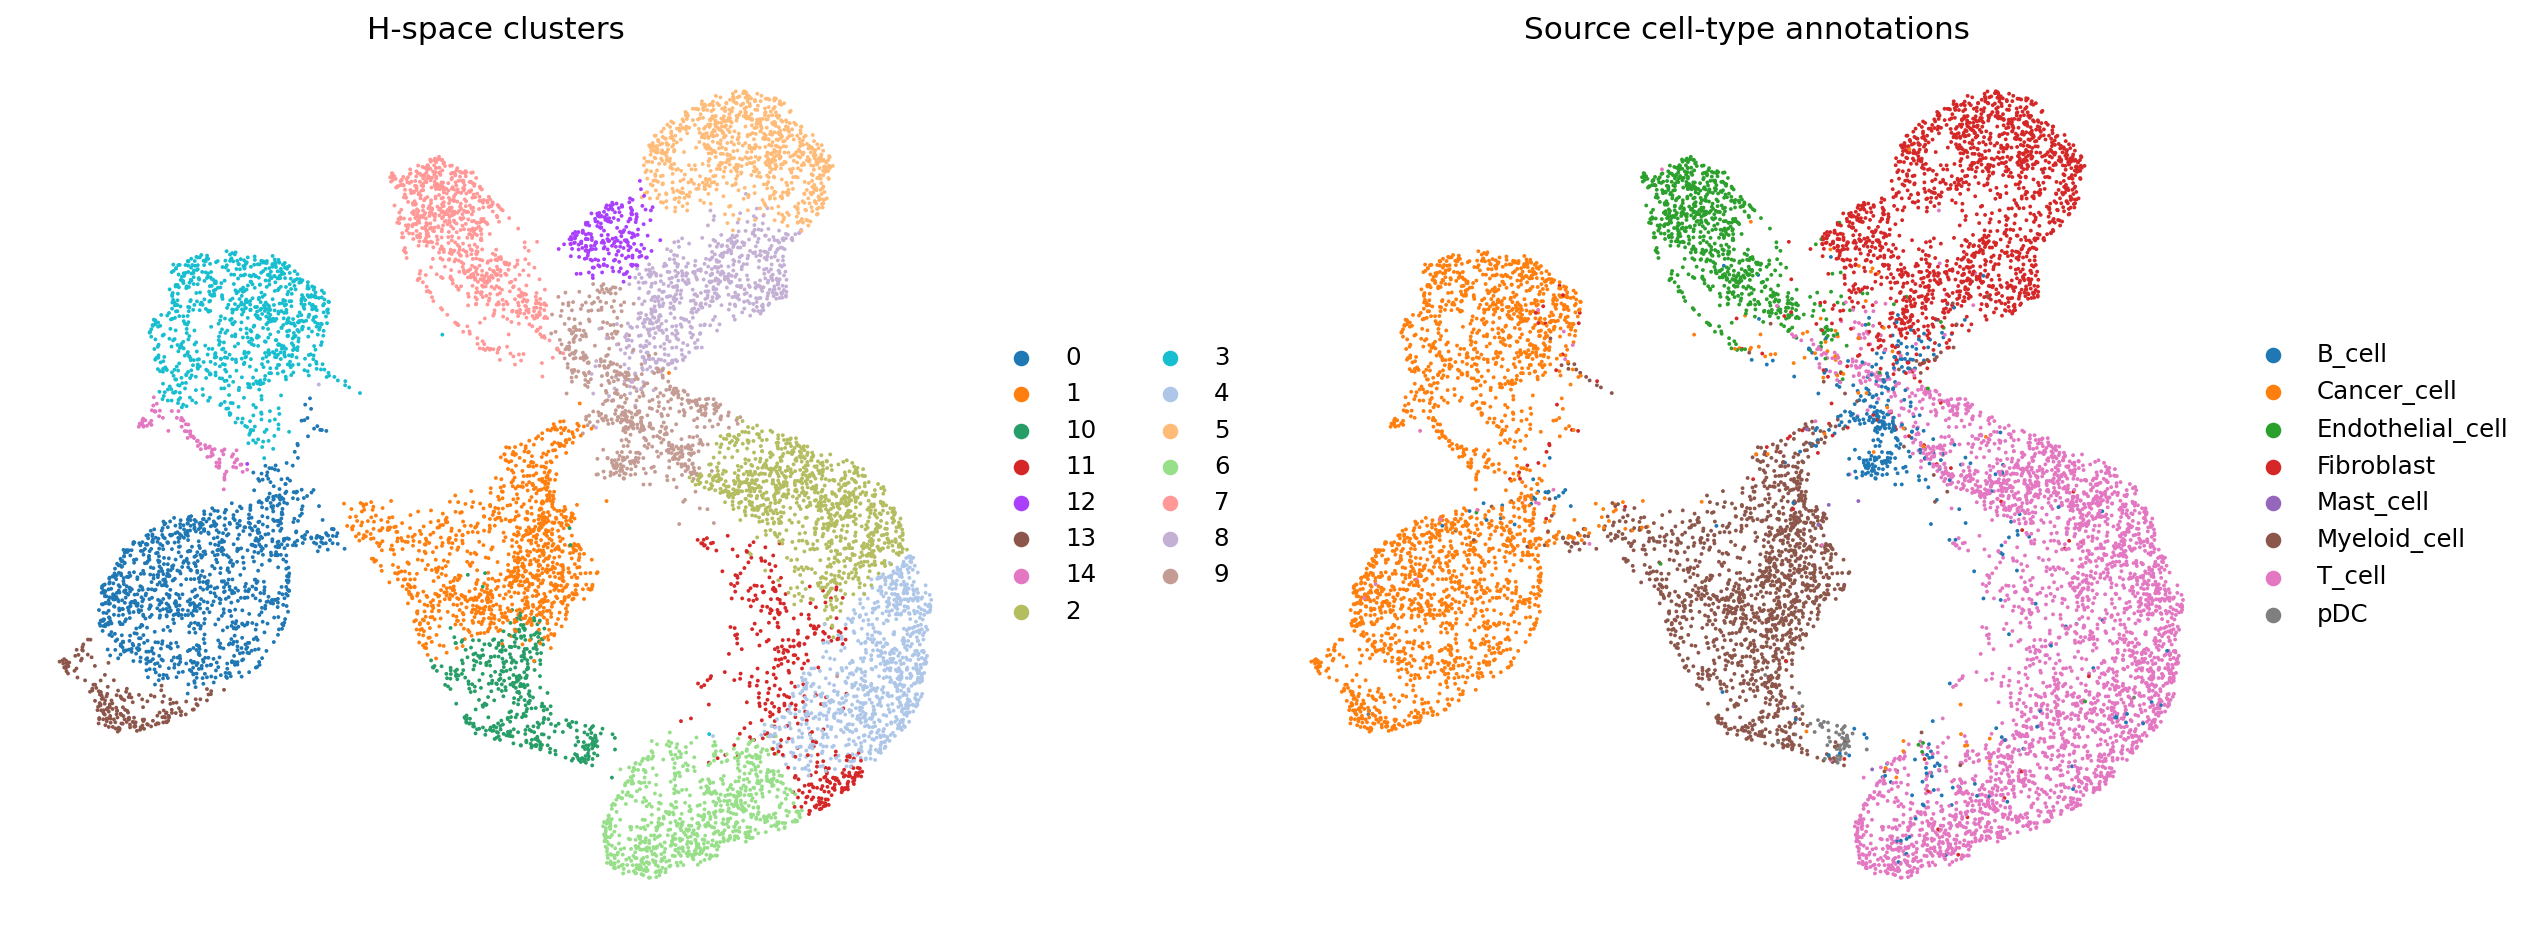

In [12]:
show_generated('cellular_organization/organization_umap.png')

Shared UMAP coordinates colored by H-space cluster and source cell type.

## Interpretation

The panels show the same 10,000 cells on identical UMAP coordinates. One panel colors H-space clusters and the other colors the source cell types, allowing visual inspection of cell-type organization in the learned representation.

## Outputs and next step

Outputs are written to `cellular_organization/`. Next, explore [metabolic activity](../docs/tutorials/10000-metabolic.md) using the same fitted model.

# Metabolic analysis



Explore metabolic-task activity in five steps: **overview → UMAP activity patterns → cell-level variation → linked reactions and genes → condition differences**. All analyses use the same 10,000-cell fit and source `cellType` metadata.

**Prerequisite:** complete [model fitting](../docs/tutorials/10000-setup.md) and [cell-type retention](../docs/tutorials/10000-annotation.md). [Download the complete runnable script](../docs/downloads/metabolic_walkthrough.py). Commented alternatives let you select other tasks or cell types.

Task activity is reconstructed from the fitted model; it is not a measurement of metabolic flux.

## Load aligned activities and metadata

Load the saved activity matrix, UMAP coordinates and cell metadata.

In [13]:
from pathlib import Path
import os, json, hashlib, textwrap
import numpy as np
import pandas as pd
import scanpy as sc
import networkx as nx
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
BASE=Path(os.environ.get('SCKNIFE_TUTORIAL_OUTPUT','tutorial/outputs_10000'))
OUT=BASE/'metabolic_walkthrough';OUT.mkdir(exist_ok=True)
fit=sc.read_h5ad(BASE/'fitted_subset.h5ad')
activity=pd.read_parquet(BASE/'activity_scores.parquet')
assert fit.n_obs==10000 and fit.obs_names.is_unique
assert activity.columns.equals(fit.obs_names) and activity.index.is_unique
assert 'X_umap' in fit.obsm and fit.obsm['X_umap'].shape==(10000,2)
meta=fit.obs[['cellType','patient_id','timepoint']].astype(str)
G=nx.read_graphml('graphs/version_1/unified_graph.graphml')
tasks=sorted(n for n,d in G.nodes(data=True) if d.get('kind')=='task' and n in activity.index)
assert len(tasks)>0
scores=activity.loc[tasks].T
assert np.isfinite(scores.to_numpy()).all() and scores.min().min()>=0
plt.rcParams.update({'font.size':12,'axes.titlesize':13,'axes.labelsize':12,'xtick.labelsize':10,'ytick.labelsize':10,'axes.spines.top':False,'axes.spines.right':False})
def save(name):
 plt.gcf().savefig(OUT/(name+'.png'),dpi=170,bbox_inches='tight');plt.close()
def heat(table,title,name,label,cmap='viridis',signed=False):
 fig,ax=plt.subplots(figsize=(10,max(5,.48*len(table)+1)))
 limit=max(float(np.abs(table.to_numpy()).max()),1e-12)
 im=ax.imshow(table,aspect='auto',cmap=cmap,vmin=-limit if signed else 0,vmax=limit)
 ax.set_xticks(range(table.shape[1]),table.columns,rotation=35,ha='right')
 ax.set_yticks(range(len(table)),[textwrap.fill(str(x),48) for x in table.index])
 ax.set_title(title);fig.colorbar(im,ax=ax,label=label);fig.tight_layout();save(name)

## 1. Overview of task activity across cell types

Begin with the eight task nodes with the highest pooled mean activity. The selection is deterministic and does not use treatment differences.

In [14]:
means=scores.groupby(meta.cellType,observed=True).mean().T
ranked=scores.mean().sort_values(ascending=False,kind='stable')
chosen=ranked.head(8).index
# chosen=ranked.head(12).index  # Show more tasks if needed.
means.to_csv(OUT/'task_means.csv')
heat(means.loc[chosen],'Selected metabolic-task activity','task_overview','Mean reconstructed task activity')

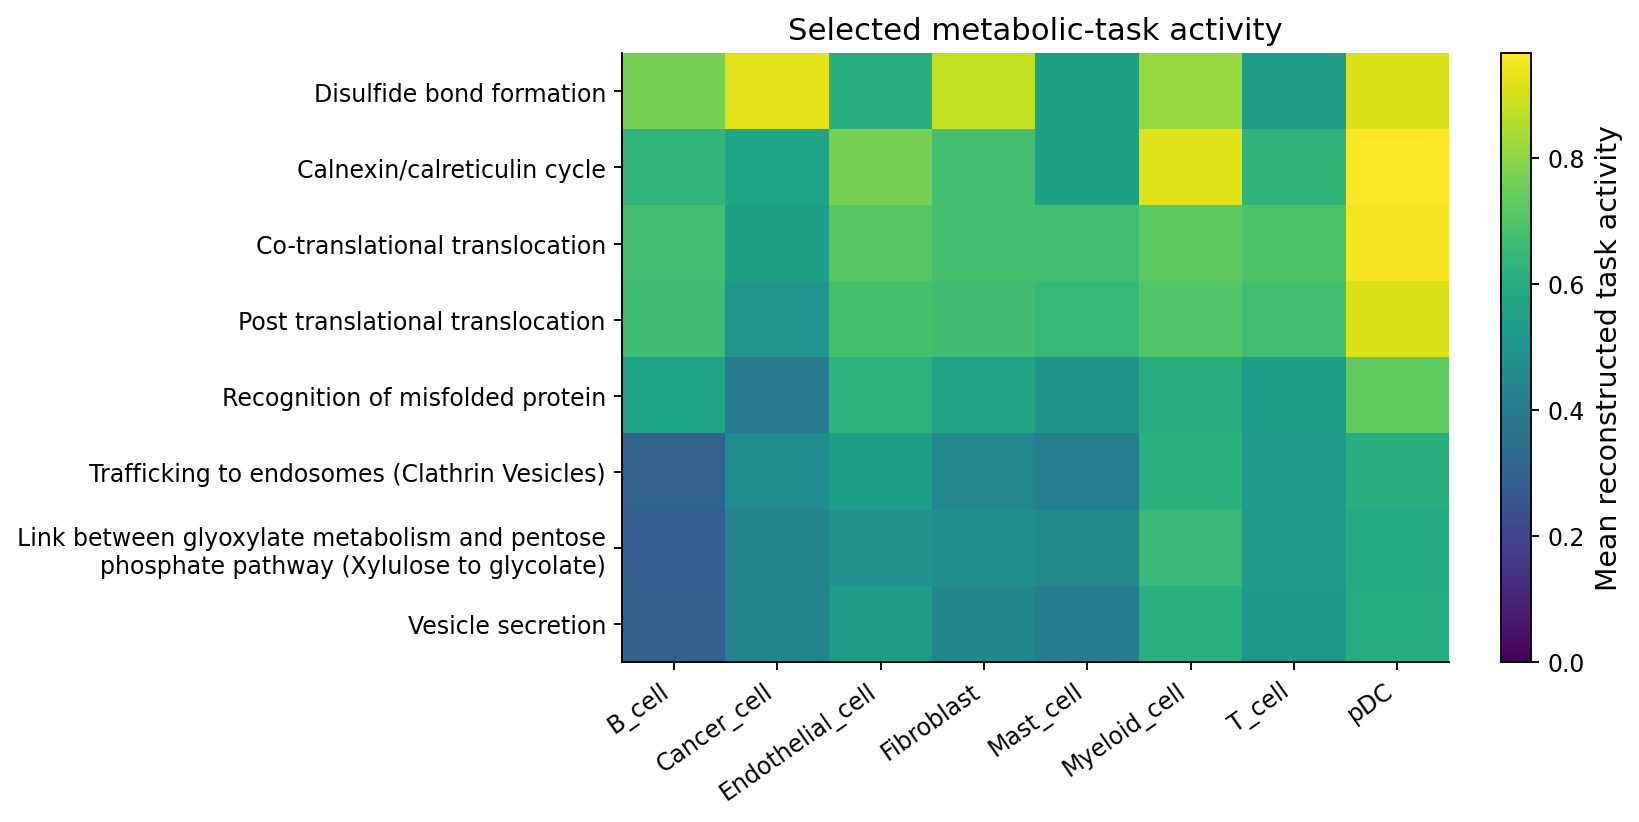

In [15]:
show_generated('metabolic_walkthrough/task_overview.png')

Each row is a task and each column a cell type. Colors show mean reconstructed activity. The task collection includes metabolic transformations, processing and trafficking functions.

## 2. Locate task activity on the shared UMAP

Compare three named task examples on the same saved embedding: glycolytic ATP generation, oxidative ATP regeneration and acetoacetate synthesis. The commented alternative selects the three highest-activity tasks.

In [16]:
example_tasks=[
 'ATP generation from glucose (hypoxic conditions) - glycolysis',
 'ATP regeneration from glucose (normoxic conditions) - glycolysis + krebs cycle',
 'Acetoacetate synthesis',
]
# example_tasks=ranked.head(3).index.tolist()  # Data-ranked alternative.
assert set(example_tasks).issubset(scores.columns)
xy=fit.obsm['X_umap']
fig,axes=plt.subplots(1,3,figsize=(14,4.5))
for ax,task in zip(axes,example_tasks):
 values=np.log1p(scores[task].to_numpy())
 lo,hi=np.quantile(values,[.02,.98])
 order=np.argsort(values,kind='stable')
 im=ax.scatter(xy[order,0],xy[order,1],c=values[order],s=3,cmap='viridis',vmin=lo,vmax=hi,rasterized=True)
 ax.set_title(textwrap.fill(task,30),fontsize=11);ax.set_xticks([]);ax.set_yticks([])
 ax.set_xlabel('UMAP 1');ax.set_ylabel('UMAP 2')
 fig.colorbar(im,ax=ax,label='log(1 + task activity)',shrink=.7)
fig.tight_layout();save('task_umaps')

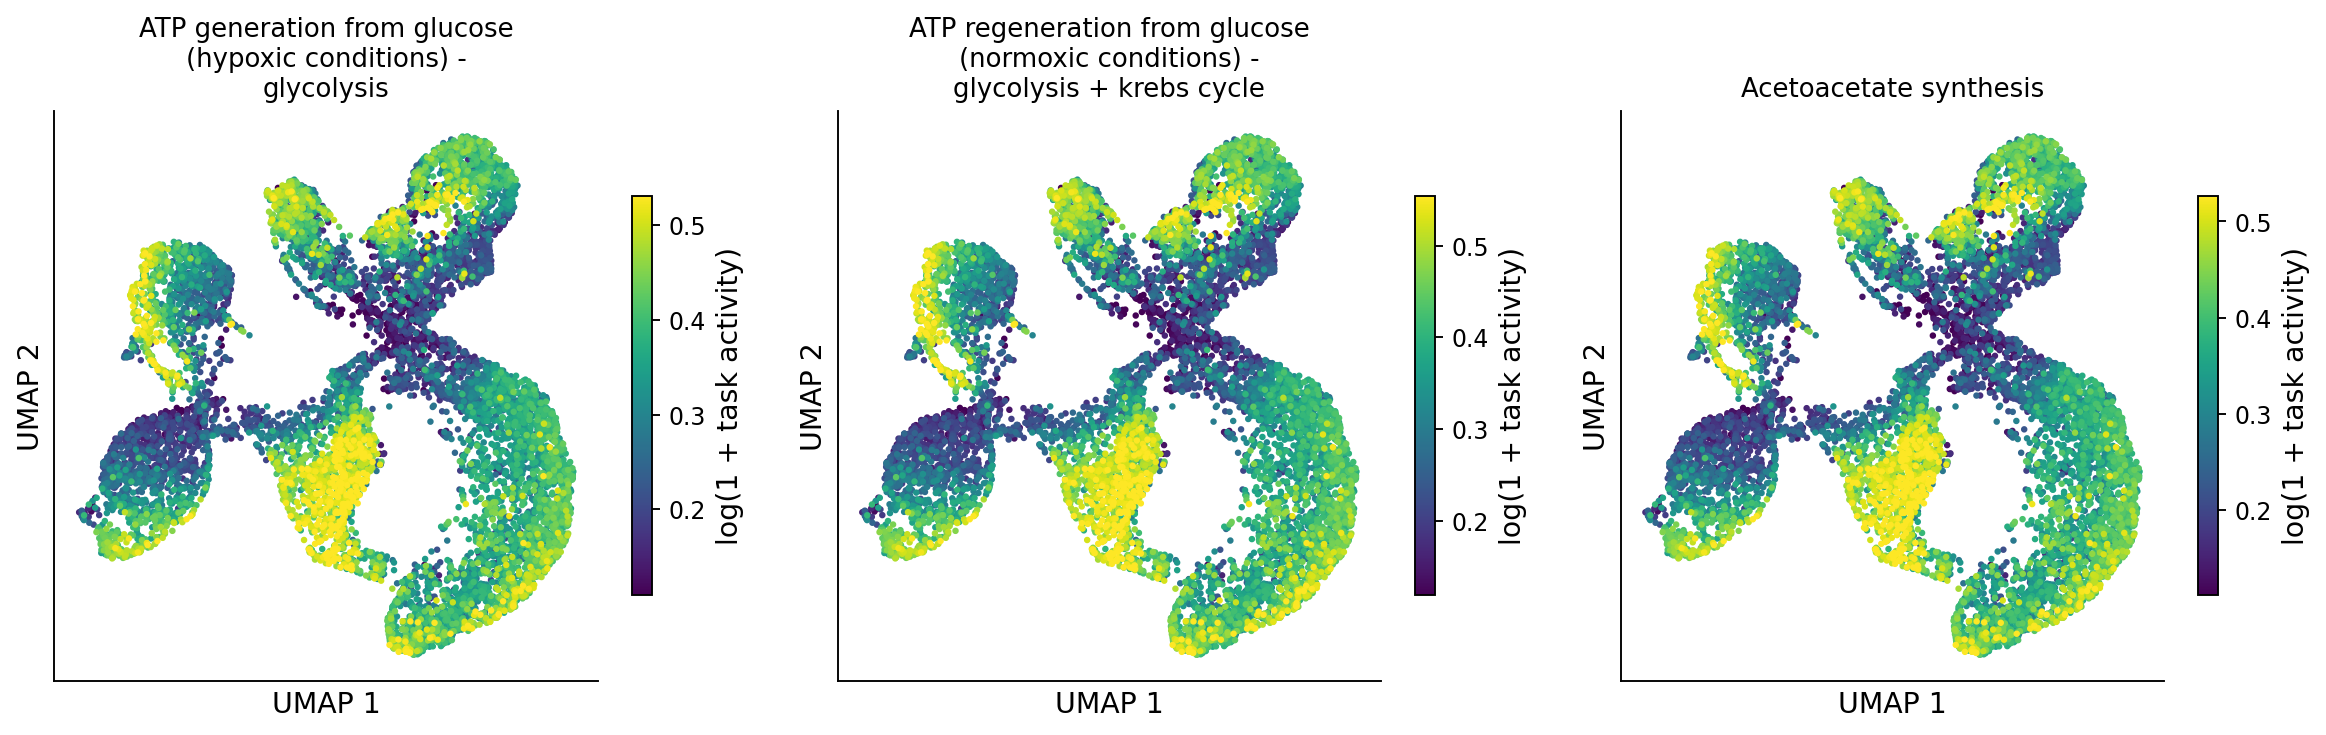

In [17]:
show_generated('metabolic_walkthrough/task_umaps.png')

Each panel shows the same 10,000 cells, colored by log(1 + task activity). Compare where higher activity occurs on the UMAP. Each panel uses its own 2nd–98th percentile color range, so equal colors across panels need not represent equal scores.

## 3. Examine variation within cell types

Plot glycolytic ATP-generation activity by cell type. Change `EXAMPLE_TASK` to inspect another task.

In [18]:
EXAMPLE_TASK=example_tasks[0]
# EXAMPLE_TASK=example_tasks[1]  # Oxidative ATP regeneration.
# EXAMPLE_TASK=example_tasks[2]  # Acetoacetate synthesis.
types=sorted(meta.cellType.unique())
values=np.log1p(scores[EXAMPLE_TASK])
fig,ax=plt.subplots(figsize=(10,5))
ax.violinplot([values.loc[meta.cellType.eq(t)].to_numpy() for t in types],showmedians=True)
ax.set_xticks(range(1,len(types)+1),[f'{t}\n(n={meta.cellType.eq(t).sum():,})' for t in types],rotation=35,ha='right')
ax.set_ylabel('log(1 + reconstructed task activity)')
ax.set_title(textwrap.fill(EXAMPLE_TASK,65));fig.tight_layout();save('task_distribution')

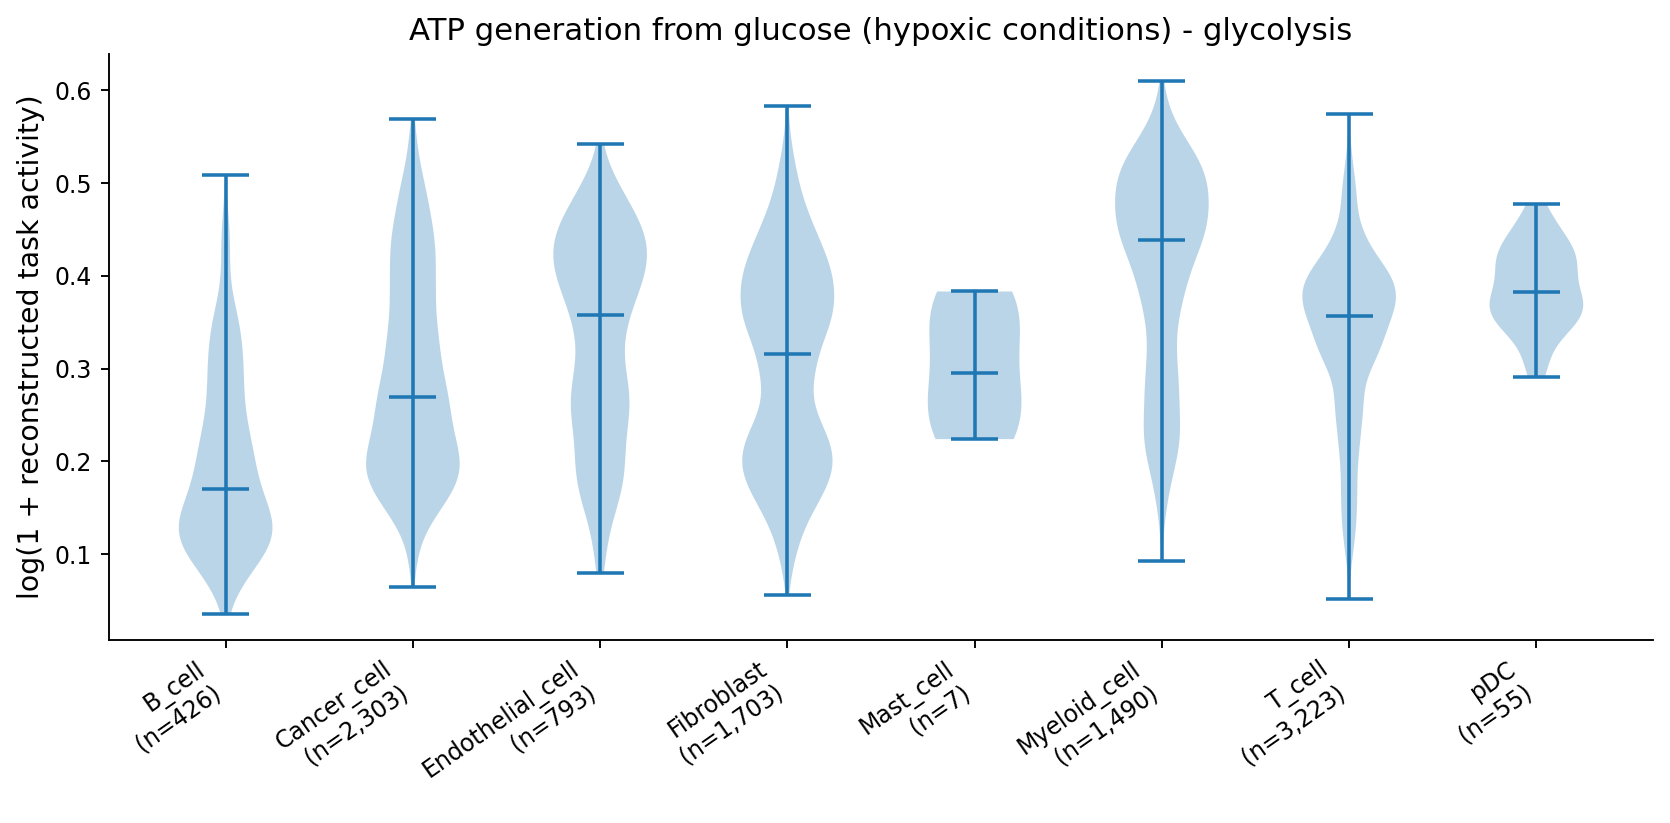

In [19]:
show_generated('metabolic_walkthrough/task_distribution.png')

Each violin shows the distribution of task activity within one cell type, with its median and cell count. Use it to inspect variation hidden by the mean heatmap; distributions from very small groups, such as the seven mast cells, are less well resolved.

## 4. Inspect connected reaction and gene activities

Follow existing task–reaction and reaction–gene edges for the selected task. Display the six highest-mean linked reactions and eight highest-mean linked genes. Gene candidates come from all reactions linked to the task, including reactions outside the displayed subset.

In [20]:
# Traverse only existing task–reaction and reaction–gene edges.
reactions=sorted(n for n in G.neighbors(EXAMPLE_TASK) if G.nodes[n].get('kind')=='reaction' and n in activity.index)
assert reactions, 'No linked reactions available for this task'
genes=sorted({n for r in reactions for n in G.neighbors(r) if G.nodes[n].get('kind')=='gene' and n in activity.index})
assert genes, 'No linked genes available for this task'
def top_nodes(names,n):
 return activity.loc[names].mean(axis=1).sort_values(ascending=False,kind='stable').head(n).index.tolist()
shown_reactions=top_nodes(reactions,6)
shown_genes=top_nodes(genes,8)
# shown_reactions=top_nodes(reactions,10)
# shown_genes=top_nodes(genes,12)
linked=[EXAMPLE_TASK]+shown_reactions+shown_genes
linked_means=activity.loc[linked].T.groupby(meta.cellType,observed=True).mean().T
logged=np.log1p(linked_means)
relative=logged.sub(logged.mean(axis=1),axis=0).div(logged.std(axis=1,ddof=0).clip(lower=1e-12),axis=0)
relative.index=[f'{G.nodes[n].get("kind")}: {n}' for n in linked]
heat(relative,'Task and connected reaction/gene activity','linked_support','Row z-score of log(1 + mean activity)','RdBu_r',True)
linked_means.to_csv(OUT/'linked_node_means.csv')
edges=[{'source':EXAMPLE_TASK,'target':r,'relation':'task–reaction'} for r in reactions]
edges += [{'source':r,'target':g,'relation':'reaction–gene'} for r in reactions for g in G.neighbors(r) if g in genes]
pd.DataFrame(edges).to_csv(OUT/'task_reaction_gene_links.csv',index=False)

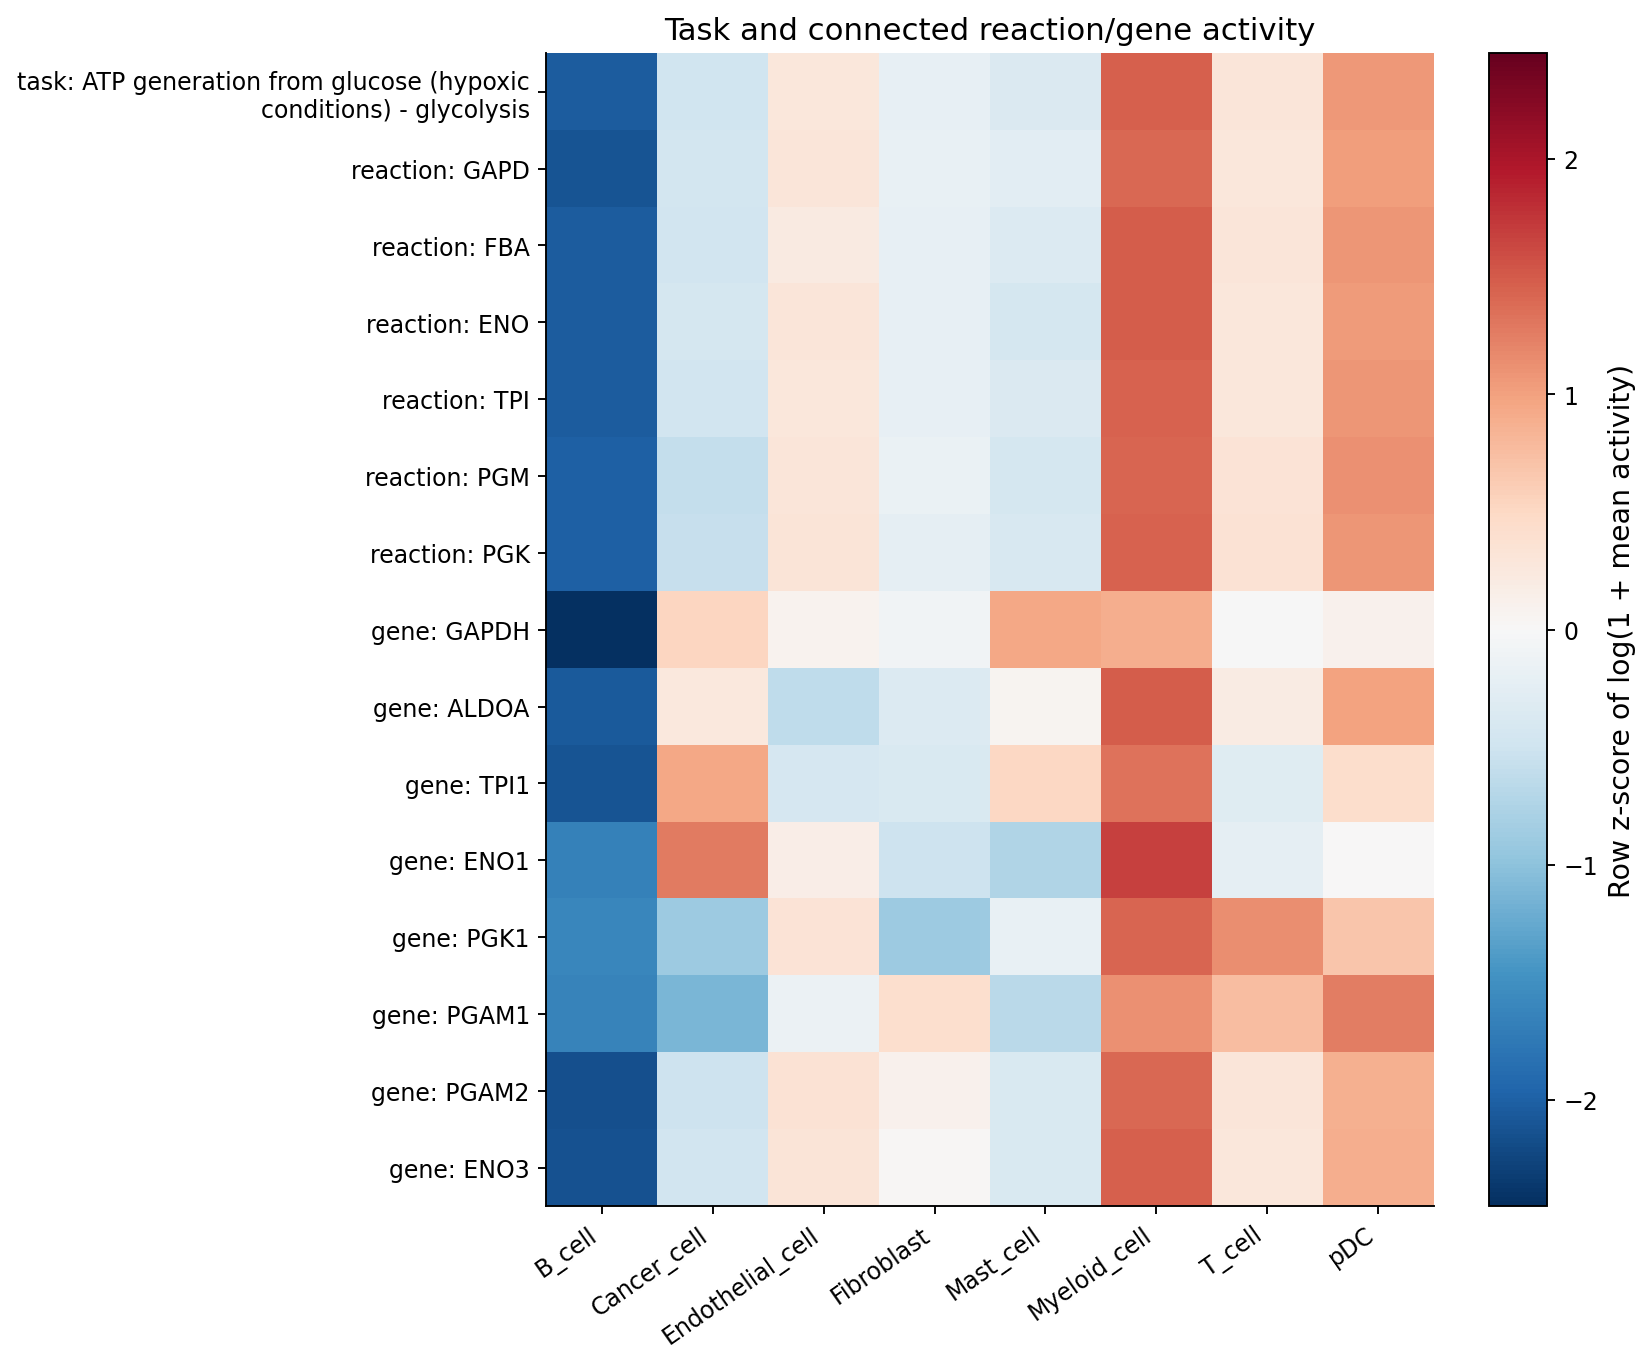

In [21]:
show_generated('metabolic_walkthrough/linked_support.png')

Rows show the selected task and linked reactions and genes. Colors are standardized across cell types within each row after log-transforming mean activity. Read across a row to compare its relative activity; the exported connections identify the graph links used.

## 5. Rank descriptive On-minus-Pre task differences

Compare cancer cells before and during treatment. Change `CELL_TYPE` to compare another population. Calculate pooled mean task activity within each timepoint, then display eight tasks with the largest absolute On-minus-Pre differences.

In [22]:
CELL_TYPE='Cancer_cell'
# CELL_TYPE='T_cell'
# CELL_TYPE='Myeloid_cell'
mask=meta.cellType.eq(CELL_TYPE) & meta.timepoint.isin(['Pre','On'])
counts=meta.loc[mask].groupby('timepoint').size()
assert all(counts.get(t,0)>=10 for t in ['Pre','On'])
condition_means=scores.loc[mask].groupby(meta.loc[mask,'timepoint']).mean()
delta=condition_means.loc['On']-condition_means.loc['Pre']
selected_delta=delta.loc[delta.abs().sort_values(ascending=False,kind='stable').head(8).index].sort_values()
fig,ax=plt.subplots(figsize=(10,6))
ax.barh(range(len(selected_delta)),selected_delta,color=np.where(selected_delta>=0,'#b85b63','#367fa5'))
ax.set_yticks(range(len(selected_delta)),[textwrap.fill(t,48) for t in selected_delta.index])
ax.axvline(0,color='#333333',lw=.8);ax.set_xlabel('Mean reconstructed activity: On − Pre')
ax.set_title(f'{CELL_TYPE} · descriptive task differences\nPre n={counts["Pre"]:,}; On n={counts["On"]:,}')
fig.tight_layout();save('ranked_differences')
condition_means.T.assign(On_minus_Pre=delta).to_csv(OUT/'condition_task_means.csv')
meta.loc[mask].groupby(['patient_id','timepoint']).size().unstack(fill_value=0).to_csv(OUT/'condition_patient_counts.csv')
summary={'cells':fit.n_obs,'tasks':len(tasks),'example_tasks':example_tasks,'example_task':EXAMPLE_TASK,'cell_type':CELL_TYPE,'linked_reactions':len(reactions),'linked_genes':len(genes),'condition_cells':counts.to_dict(),'cell_id_sha256':hashlib.sha256('\n'.join(fit.obs_names).encode()).hexdigest()}
(OUT/'summary.json').write_text(json.dumps(summary,indent=2));print(summary)

{'cells': 10000, 'tasks': 218, 'example_tasks': ['ATP generation from glucose (hypoxic conditions) - glycolysis', 'ATP regeneration from glucose (normoxic conditions) - glycolysis + krebs cycle', 'Acetoacetate synthesis'], 'example_task': 'ATP generation from glucose (hypoxic conditions) - glycolysis', 'cell_type': 'Cancer_cell', 'linked_reactions': 7, 'linked_genes': 15, 'condition_cells': {'On': 617, 'Pre': 1686}, 'cell_id_sha256': 'a47ad5d98b131c0e47129c7657dcc35515c675cddd510c60e89f986c21212d63'}


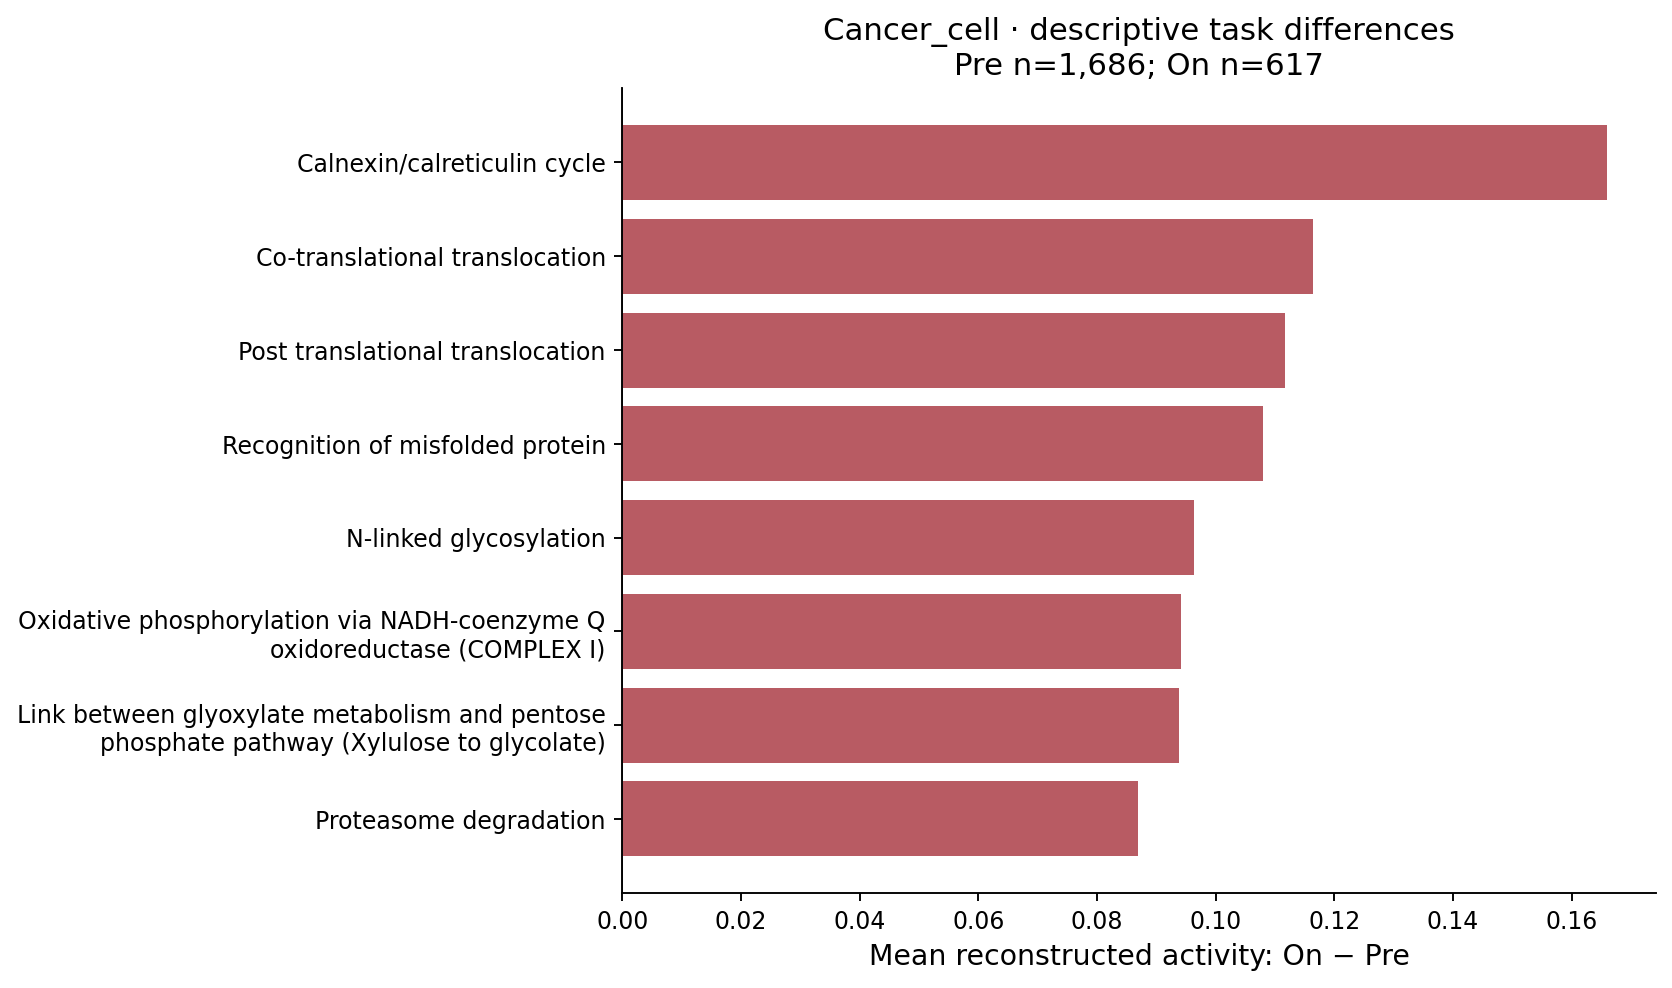

In [23]:
show_generated('metabolic_walkthrough/ranked_differences.png')

Positive bars indicate higher pooled mean activity On-treatment; negative bars indicate higher activity Pre-treatment. These descriptive differences have no p-values or patient adjustment. Use the exported patient-by-timepoint counts to check group representation.

## Outputs and next step

Results are saved under `metabolic_walkthrough/`: task means, linked-node means, graph connections, condition means, patient counts, the run summary and five figures. Change an example selection and rerun the relevant blocks to explore other tasks or cell types.

Continue to [factor interpretation](../docs/tutorials/10000-factors.md).

# Factor interpretation



Interpret the fitted model through **factor usage → consensus clusters → representative biological nodes → cell-level activities**. This page uses the same 10,000 cells, fitted factors and source `cellType` metadata.

**Prerequisite:** complete [model fitting](../docs/tutorials/10000-setup.md). [Download the complete runnable script](../docs/downloads/factor_interpretation.py).

## How to read the output

**CC** (consensus cluster) identifies a group of factors with related W profiles; **NG** identifies the biological nodes selected to interpret that group. NG activity reconstructs those nodes using all aligned factors. CC activity averages H over the factors assigned to that group. The interpretation resolution is **k=4**, while the fitted model rank is selected before the full fit. NG activity and CC activity summarize different aspects of the fitted model.

## Load the fitted model

Load W, its aligned H columns and cell metadata. For this interpretation, select W rows outside the cell-type and cell-state categories.

In [24]:
from pathlib import Path
import os, json, hashlib, textwrap, time
import numpy as np
import pandas as pd
import scanpy as sc
import networkx as nx
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, fcluster, leaves_list
from scipy.spatial.distance import squareform
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from matplotlib.patches import Patch
START=time.time()
BASE=Path(os.environ.get('SCKNIFE_TUTORIAL_OUTPUT','tutorial/outputs_10000'))
OUT=BASE/'factor_interpretation_k4';OUT.mkdir(exist_ok=True)
plt.rcParams.update({'font.size':12,'axes.titlesize':14,'axes.labelsize':12,'xtick.labelsize':10,'ytick.labelsize':10,'axes.spines.top':False,'axes.spines.right':False})
a=sc.read_h5ad(BASE/'fitted_subset.h5ad')
assert a.n_obs==10000 and a.obs_names.is_unique
nodes=np.asarray(a.uns['node_names']).astype(str)
W=np.asarray(a.uns['W_graph'],dtype=float)
hcols=sorted([c for c in a.obs if c.startswith('H_graph_')],key=lambda c:int(c.rsplit('_',1)[1]))
H=a.obs[hcols].to_numpy(float)
N_FACTORS = H.shape[1]
assert H.shape[0] == 10000 and W.shape == (len(nodes), N_FACTORS)
assert np.isfinite(W).all() and np.isfinite(H).all() and W.min()>=0 and H.min()>=0
meta=a.obs[['cellType','patient_id','timepoint']].astype(str)
types=sorted(meta.cellType.unique())
G=nx.read_graphml('graphs/version_1/unified_graph.graphml')
kinds=np.array([str(G.nodes[n].get('kind','')) for n in nodes])
keep=(~np.isin(kinds,['cell_type','cell_state'])) & (W.sum(axis=1)>0)
W_ELIGIBLE=pd.DataFrame(W[keep],index=nodes[keep],columns=[str(i) for i in range(N_FACTORS)])
NODE_METADATA_ELIGIBLE=pd.DataFrame({'node_name':nodes[keep],'node_kind':kinds[keep]})
def row_z(x):
 x=np.log1p(np.asarray(x,dtype=float))
 return (x-x.mean(axis=1,keepdims=True))/np.maximum(x.std(axis=1,keepdims=True),1e-12)
def save(name):
 plt.gcf().savefig(OUT/(name+'.png'),dpi=170,bbox_inches='tight');plt.close()
def heat(table,title,name,label='Row z-score of log(1 + mean activity)',signed=True):
 fig,ax=plt.subplots(figsize=(9,max(4,.33*len(table)+1.5)))
 lim=max(float(np.max(np.abs(table.to_numpy()))),1e-12)
 im=ax.imshow(table,aspect='auto',cmap='RdBu_r' if signed else 'viridis',vmin=-lim if signed else 0,vmax=lim)
 ax.set_xticks(range(table.shape[1]),table.columns,rotation=40,ha='right')
 ax.set_yticks(range(len(table)),table.index);ax.set_title(title)
 fig.colorbar(im,ax=ax,label=label);fig.tight_layout();save(name)

## Begin with H: factor usage across cell types

Start with the original factor activities before grouping factors.

In [25]:
factor_means=pd.DataFrame(H,index=a.obs_names,columns=hcols).groupby(meta.cellType).mean().reindex(types).T
heat(factor_means,'Mean H activity by source cell type','factor_usage','Mean H activity',False)
factor_means.to_csv(OUT/'factor_usage.csv')

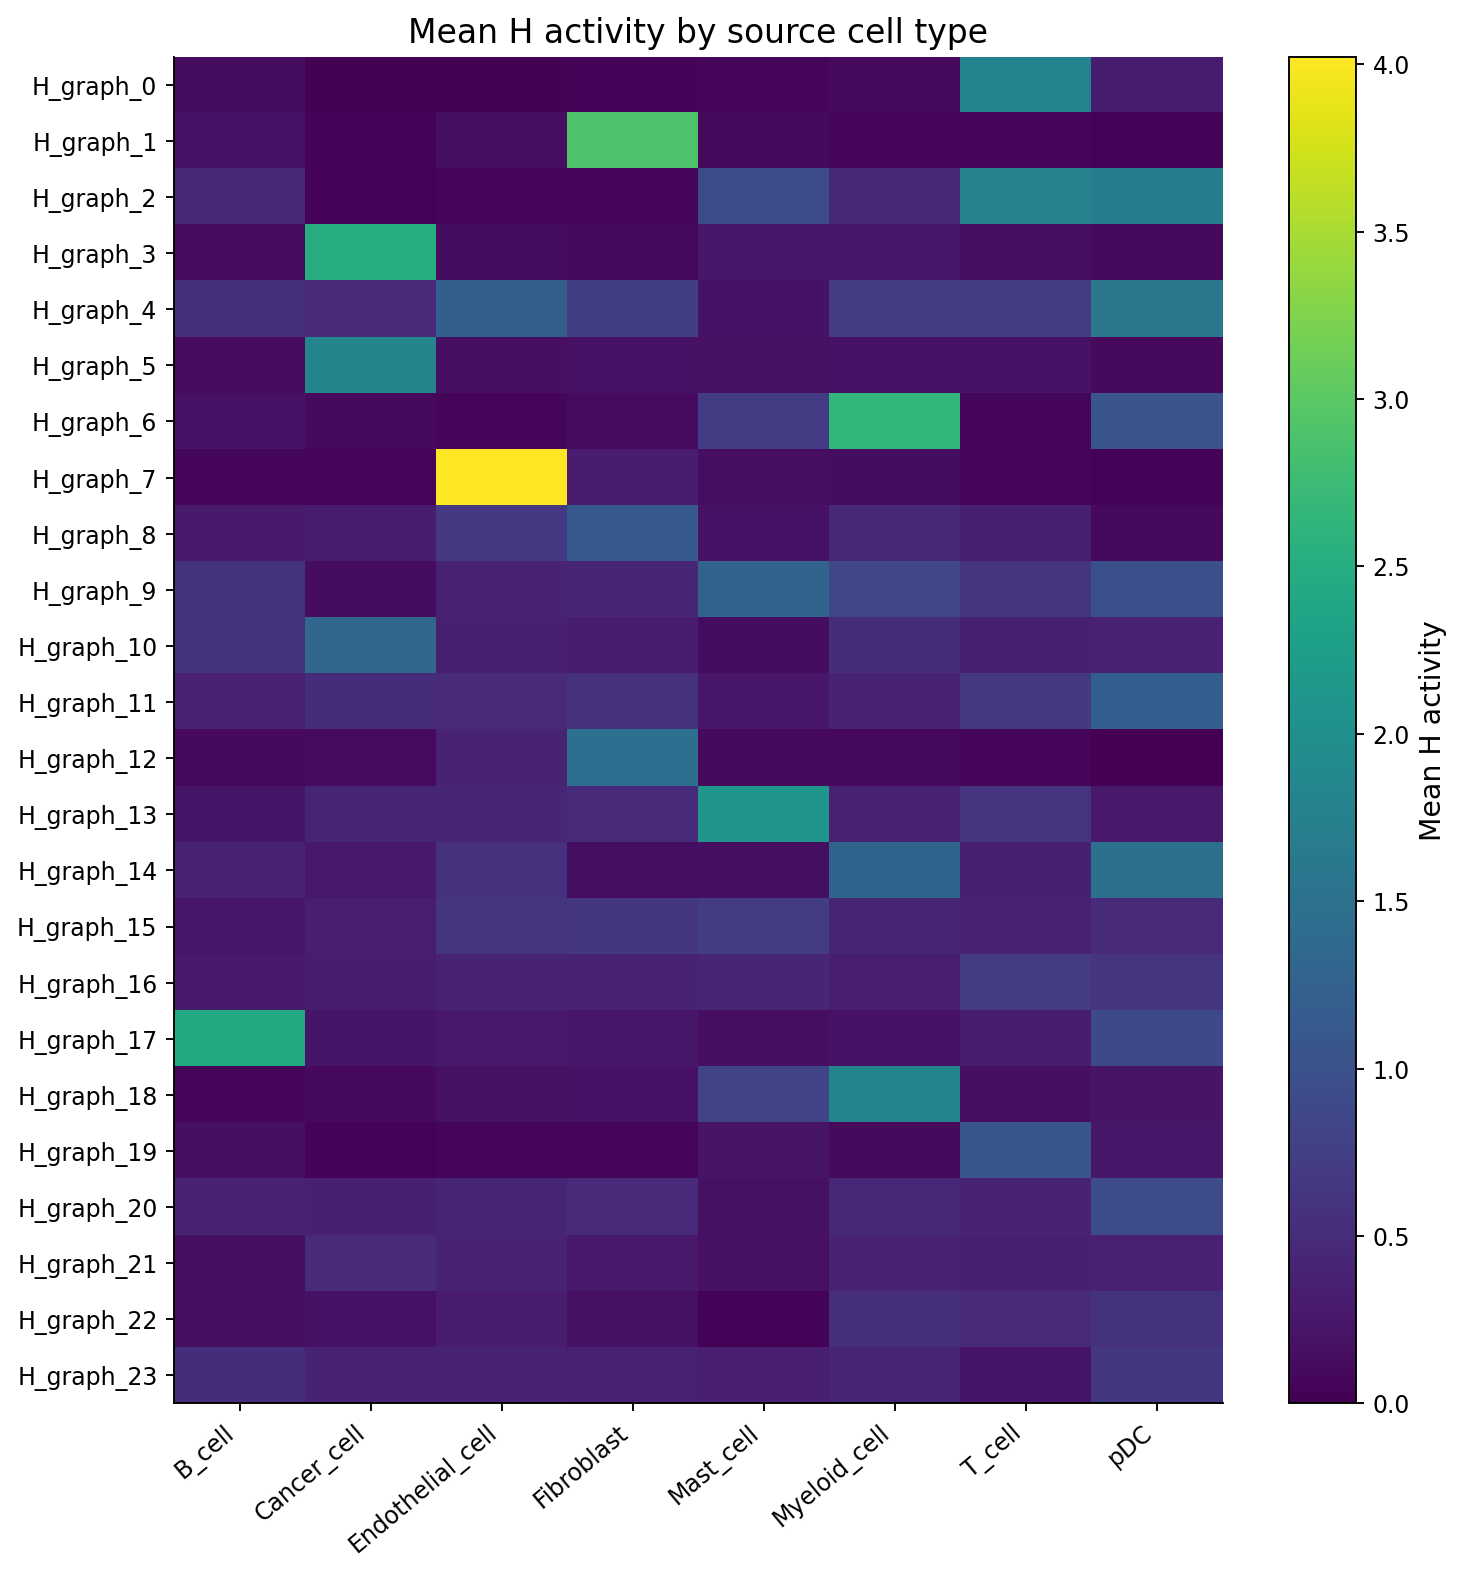

In [26]:
show_generated('factor_interpretation_k4/factor_usage.png')

Each row is an H factor and each column a cell type. Colors show mean factor activity; compare rows to see which factors are used by each population.

## Choose the number of factor groups using W consensus

The analysis standardizes log(1 + W) within each node, resamples 80% of eligible nodes with replacement 200 times, and clusters factors using correlation distance and average linkage. We test consensus resolutions from 2 to the smaller of 12 and one less than the fitted rank. PAC measures the fraction of factor pairs with ambiguous consensus (between 0.1 and 0.9). After reviewing these diagnostics, this tutorial uses the chosen resolution **k=4**. The fitted model rank is selected before the full fit.

In [27]:
SEED=42;BOOTSTRAPS=200;RESAMPLE_FRACTION=.8
K_VALUES=range(2,min(13,N_FACTORS))
W_Z=row_z(W_ELIGIBLE)
rng=np.random.default_rng(SEED)
sums={k:np.zeros((N_FACTORS,N_FACTORS)) for k in K_VALUES}
for b in range(BOOTSTRAPS):
 rows=rng.choice(len(W_Z),int(.8*len(W_Z)),replace=True)
 d=np.clip(1-np.corrcoef(W_Z[rows].T),0,2);np.fill_diagonal(d,0)
 for k in K_VALUES:
  lab=AgglomerativeClustering(n_clusters=k,metric='precomputed',linkage='average').fit_predict(d)
  sums[k]+=lab[:,None]==lab[None,:]
records=[];solutions={}
for k in K_VALUES:
 c=sums[k]/BOOTSTRAPS;d=1-c;np.fill_diagonal(d,0)
 tree=linkage(squareform(d,checks=False),method='average')
 lab=fcluster(tree,t=k,criterion='maxclust')-1
 sizes=np.bincount(lab);upper=c[np.triu_indices(N_FACTORS,1)]
 records.append({'k':k,'actual_groups':len(sizes),'PAC':np.mean((upper>.1)&(upper<.9)),
  'silhouette':silhouette_score(d,lab,metric='precomputed'),'min_size':sizes.min(),'max_size':sizes.max()})
 solutions[k]=(c,lab,tree)
metrics=pd.DataFrame(records)
# Review consensus diagnostics, then use the chosen four-group resolution.
eligible=metrics[(metrics.min_size>=2)&(metrics.actual_groups==metrics.k)]
assert not eligible.empty
SELECTED_K=4  # Chosen tutorial resolution; fitted model rank is selected before the full fit.
assert SELECTED_K in eligible.k.values
metrics.to_csv(OUT/'k_diagnostics.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,col,title in zip(axes,['PAC','silhouette'],['Ambiguous consensus fraction · lower is better','Consensus silhouette · higher is better']):
 ax.plot(metrics.k,metrics[col],'o-',color='#247b87')
 ax.scatter(eligible.k,eligible[col],s=110,facecolors='none',edgecolors='#d7832c',label='No singleton groups')
 ax.axvline(SELECTED_K,color='#9b456b',ls='--',label=f'Selected k={SELECTED_K}')
 ax.set_xlabel('Number of factor groups (k)');ax.set_title(title,fontsize=12);ax.set_xticks(list(K_VALUES))
axes[0].legend(fontsize=9);fig.tight_layout();save('choose_k')
print(metrics.to_string(index=False),flush=True);print('SELECTED_K',SELECTED_K,flush=True)

 k  actual_groups      PAC  silhouette  min_size  max_size
 2              2 0.000000    0.994752        10        14
 3              3 0.000000    0.998839         3        11
 4              4 0.173913    0.951571         3        10
 5              5 0.000000    0.996901         3         8
 6              6 0.000000    0.954812         1         8
 7              7 0.014493    0.895489         1         8
 8              8 0.000000    0.867316         1         8
 9              9 0.000000    0.816856         1         8
10             10 0.043478    0.816538         1         8
11             11 0.000000    0.832498         1         6
12             12 0.010870    0.752868         1         6


SELECTED_K 4


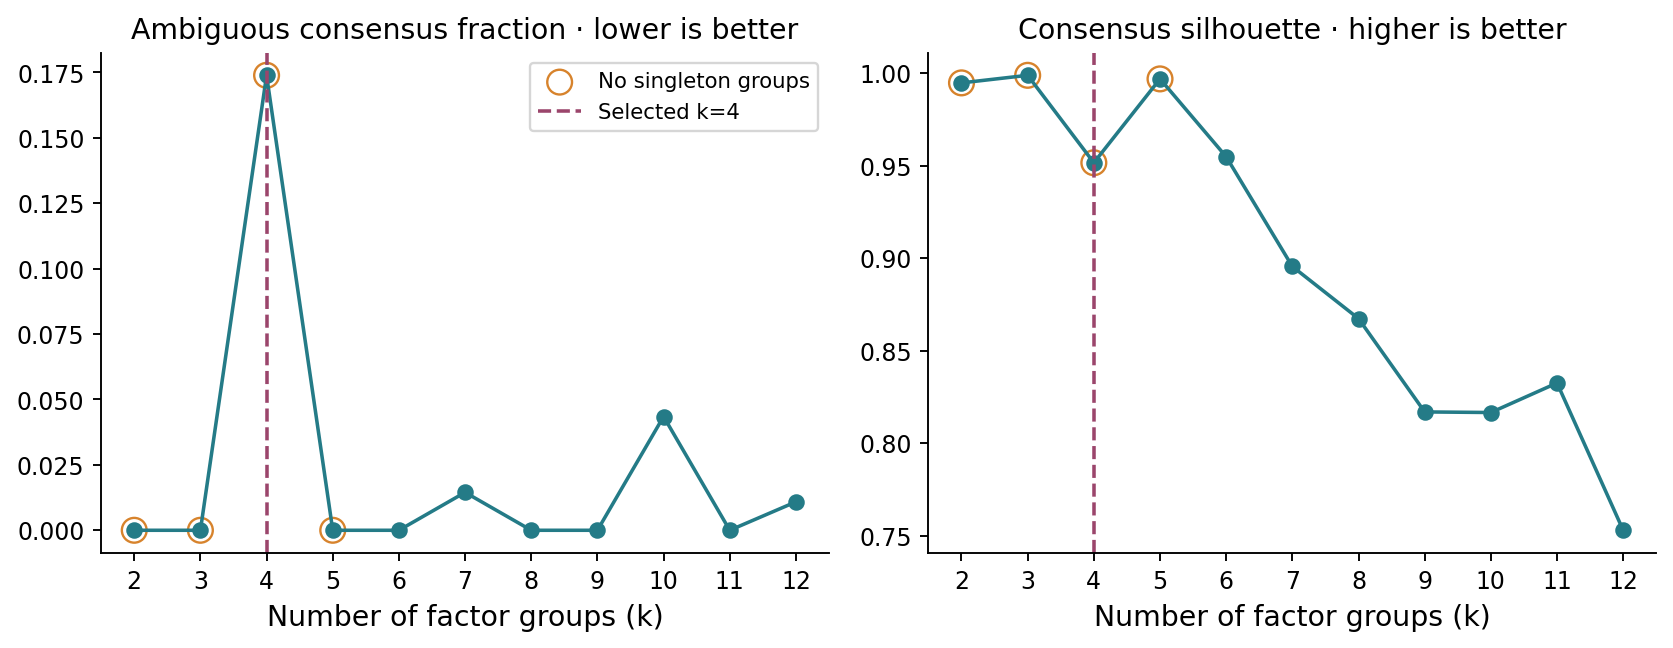

In [28]:
show_generated('factor_interpretation_k4/choose_k.png')

The example uses **four factor groups (k=4)**. PAC is 0, the consensus silhouette is approximately 0.998, and each group contains at least three factors. The nearby k=2 and k=3 results are shown below for comparison.

## Inspect consensus and factor membership

Relabel groups consistently by their smallest factor index, then inspect pairwise co-clustering.

In [29]:
consensus,raw,tree=solutions[SELECTED_K]
raw_order=sorted(set(raw),key=lambda l:np.flatnonzero(raw==l)[0])
labels=np.array([raw_order.index(l) for l in raw])
groups=[f'CC{i+1}' for i in range(SELECTED_K)]
ngroups=[f'NG{i+1}' for i in range(SELECTED_K)]
COMPONENT_ASSIGNMENTS=pd.DataFrame({'component':[str(i) for i in range(N_FACTORS)],'consensus_cluster':labels})
COMPONENT_ASSIGNMENTS.to_csv(OUT/'factor_groups.csv',index=False)
order=np.lexsort((np.arange(N_FACTORS),labels))
ticks=[f'H{i} · {groups[labels[i]]}' for i in order]
heat(pd.DataFrame(consensus[np.ix_(order,order)],index=ticks,columns=ticks),'Bootstrap factor co-clustering','consensus','Co-clustering fraction',False)

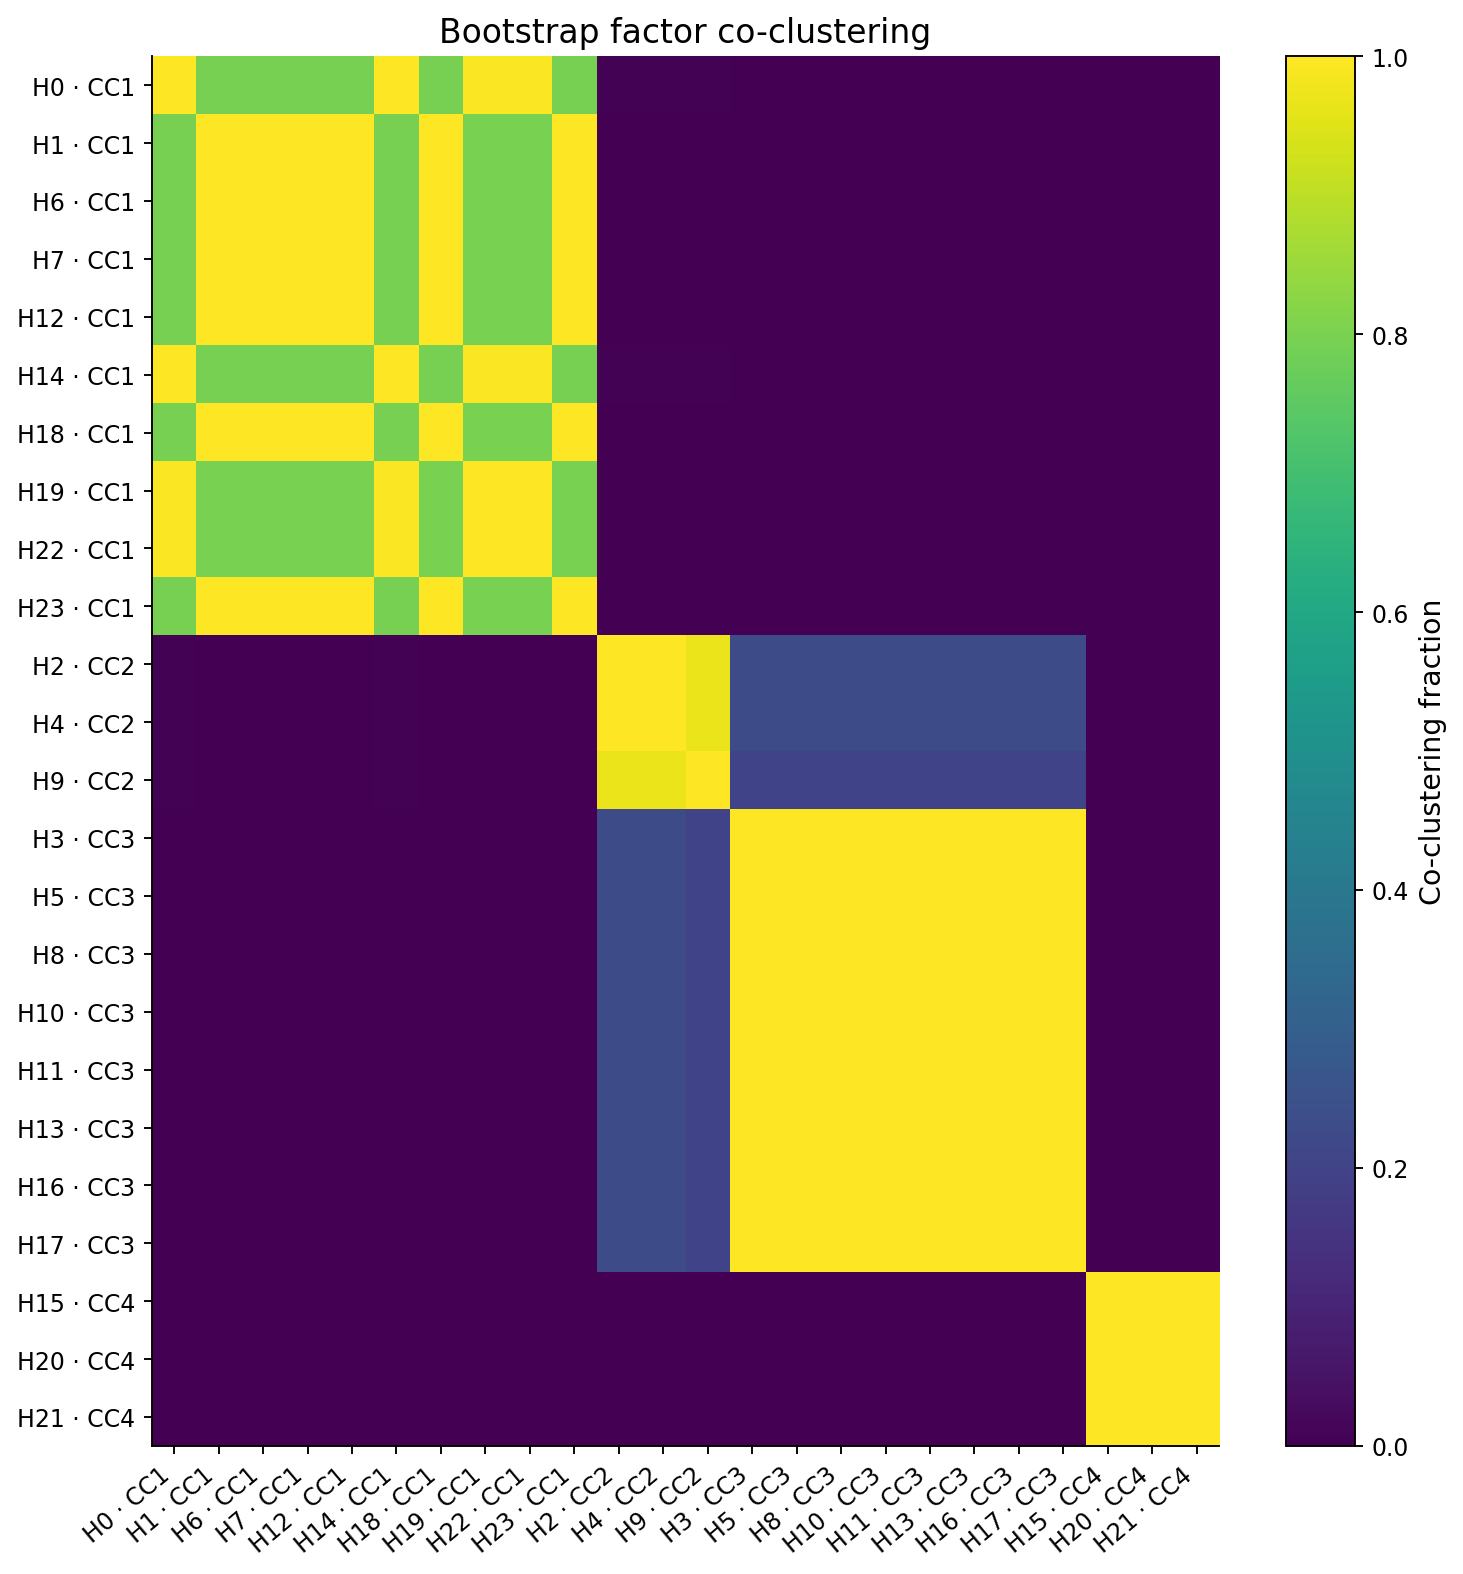

In [30]:
show_generated('factor_interpretation_k4/consensus.png')

Each tile is the fraction of bootstrap runs in which two factors were assigned together. Labels identify factor membership. Strong within-group blocks indicate stable grouping under the specified node resampling.

## Compare nearby grouping resolutions

Review k=2, 3 and 4 before proceeding. The selected resolution is used consistently in every subsequent calculation.

In [31]:
sensitivity=[]
for k in [2,3,4]:
 lab=solutions[k][1]
 ordered_labels=sorted(set(lab),key=lambda v:np.flatnonzero(lab==v)[0])
 sensitivity.append([ordered_labels.index(v)+1 for v in lab])
fig,ax=plt.subplots(figsize=(10,3))
ax.imshow(sensitivity,cmap='tab10',aspect='auto',vmin=1,vmax=10)
for i,row in enumerate(sensitivity):
 for j,v in enumerate(row):ax.text(j,i,str(v),ha='center',va='center',color='white')
ax.set_xticks(range(N_FACTORS),[f'H{i}' for i in range(N_FACTORS)],rotation=45)
ax.set_yticks(range(3),['k=2','k=3','k=4']);ax.set_title('Factor membership at nearby resolutions')
fig.tight_layout();save('resolution_sensitivity')

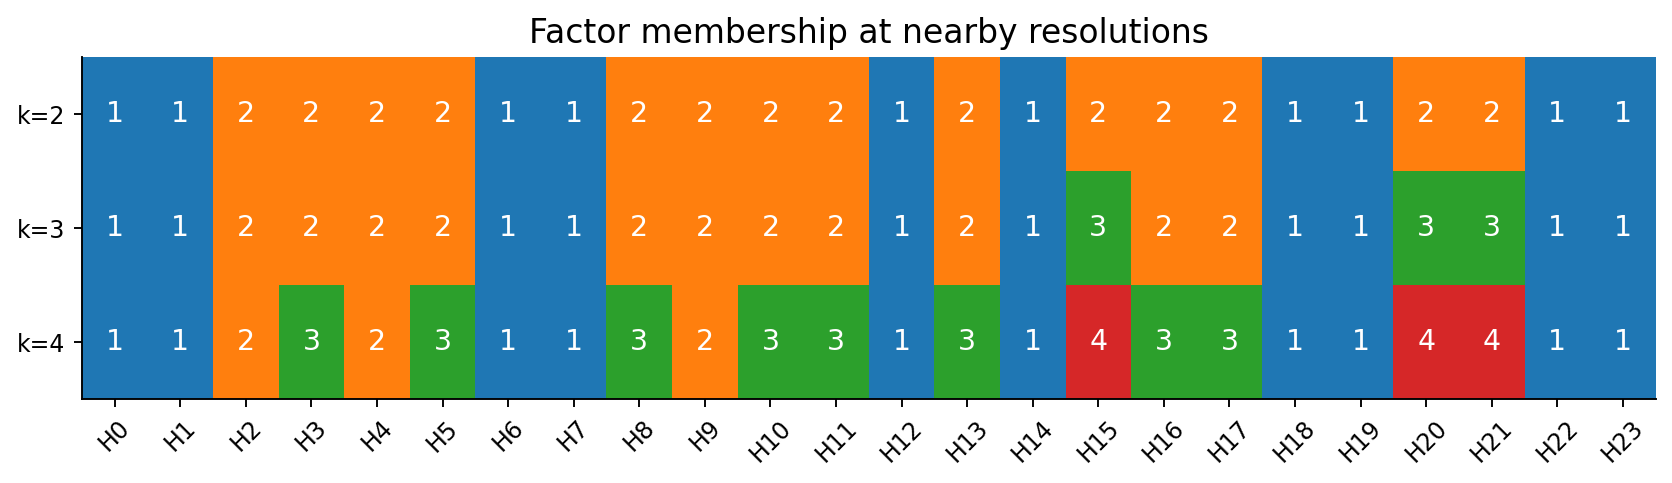

In [32]:
show_generated('factor_interpretation_k4/resolution_sensitivity.png')

Each row shows factor membership at one resolution. Group numbers are local to that row. Change `SELECTED_K` and regenerate the downstream summaries to explore another resolution.

## Select representative biological nodes

Select 20 representative biological nodes per factor group using their relative W loading profiles. The helper ranks candidates within node categories, applies a decay cutoff and fills a unique 20-node dictionary for each group. The settings below control this selection. The helper functions are included in scKNIFE; [download their source](../docs/downloads/factor_selection_helpers.py) to inspect the selection rules.

In [ ]:
DECAY_TAU=5.;DECAY_CUMULATIVE_MASS=.95;MAX_NODES_PER_CLUSTER_KIND=20;TOP_N=20
from scknife.tutorial_helpers import (
    score_nodes, assign_nodes_to_strongest_cluster,
    rank_nodes_with_exponential_decay, select_mixed_decay_budget,
)

ALL_NODE_SCORES=score_nodes(W_Z,NODE_METADATA_ELIGIBLE,COMPONENT_ASSIGNMENTS,SELECTED_K)
assigned=assign_nodes_to_strongest_cluster(ALL_NODE_SCORES)
ranked,decay_audit=rank_nodes_with_exponential_decay(assigned,DECAY_TAU,DECAY_CUMULATIVE_MASS,MAX_NODES_PER_CLUSTER_KIND)
local,local_audit=rank_nodes_with_exponential_decay(ALL_NODE_SCORES[ALL_NODE_SCORES.enrichment_delta_z>0],DECAY_TAU,DECAY_CUMULATIVE_MASS,MAX_NODES_PER_CLUSTER_KIND)
selected=select_mixed_decay_budget(ranked,local,TOP_N,SELECTED_K)
assert selected.node_name.is_unique and len(selected)==TOP_N*SELECTED_K
assert selected.enrichment_delta_z.gt(0).all()
selected.to_csv(OUT/'selected_nodes.csv',index=False);decay_audit.to_csv(OUT/'decay_audit.csv',index=False)

The dictionary contains 80 unique nodes. `selected_nodes.csv` records their categories, loading contrasts and selection reasons; `decay_audit.csv` records the category cutoffs. Here, enrichment means a relative loading contrast.

## Read the node dictionary and relative W profiles

Each heatmap combines all 80 selected nodes from NG1–NG4. Horizontal boundaries separate node groups. Read the individual-factor profiles first, then the CC-mean summary and node-kind composition.

In [34]:
wmean=np.column_stack([W_ELIGIBLE.to_numpy()[:,labels==g].mean(axis=1) for g in range(SELECTED_K)])
wz=pd.DataFrame(row_z(wmean),index=W_ELIGIBLE.index,columns=groups)
rows=selected.sort_values(['consensus_cluster','cluster_rank'])
row_groups=rows.consensus_cluster.to_numpy()
row_names=[textwrap.fill(f'{ngroups[g]}: {n} [{kind}]',52)
           for g,n,kind in zip(row_groups,rows.node_name,rows.node_kind)]
def combined_node_heatmap(values,columns,title,filename,color_label,factor_columns=False):
 fig,ax=plt.subplots(figsize=(12,max(6,.36*len(rows)+2)))
 limit=max(float(np.abs(values).max()),1e-12)
 im=ax.imshow(values,aspect='auto',cmap='RdBu_r',vmin=-limit,vmax=limit)
 ax.set_yticks(range(len(rows)),row_names,fontsize=10)
 ax.set_xticks(range(len(columns)),columns,rotation=45,ha='right')
 for boundary in np.flatnonzero(np.diff(row_groups)!=0)+.5:
  ax.axhline(boundary,color='#273e50',lw=1.2)
 if factor_columns:
  for boundary in np.flatnonzero(np.diff(labels[order])!=0)+.5:
   ax.axvline(boundary,color='#273e50',lw=1.2)
  top=ax.secondary_xaxis('top')
  top.set_xticks([np.flatnonzero(labels[order]==g).mean() for g in range(SELECTED_K)],groups)
  top.tick_params(length=0)
 ax.set_title(title,pad=30 if factor_columns else 12)
 fig.colorbar(im,ax=ax,label=color_label,fraction=.025,pad=.03)
 fig.tight_layout();save(filename)
combined_node_heatmap(wz.loc[rows.node_name].to_numpy(),groups,
 'Representative biological nodes · NG1–NG4','node_dictionary_all',
 'Node-wise z-score of log(1 + mean W)')
combined_node_heatmap(W_Z[W_ELIGIBLE.index.get_indexer(rows.node_name)][:,order],
 [f'H{i}' for i in order],'Biological nodes across factors · NG1–NG4',
 'node_factors_all','Node-wise z-score of log(1 + W)',factor_columns=True)
composition=pd.crosstab(selected.consensus_cluster,selected.node_kind);composition.index=ngroups
ax=composition.plot.bar(stacked=True,figsize=(9,5),colormap='tab20',rot=0)
ax.set_ylabel('Selected nodes');ax.set_xlabel('Node group');ax.set_title('Biological node-kind composition')
ax.legend(title='Node kind',bbox_to_anchor=(1.02,1),loc='upper left',fontsize=10);plt.tight_layout();save('composition')

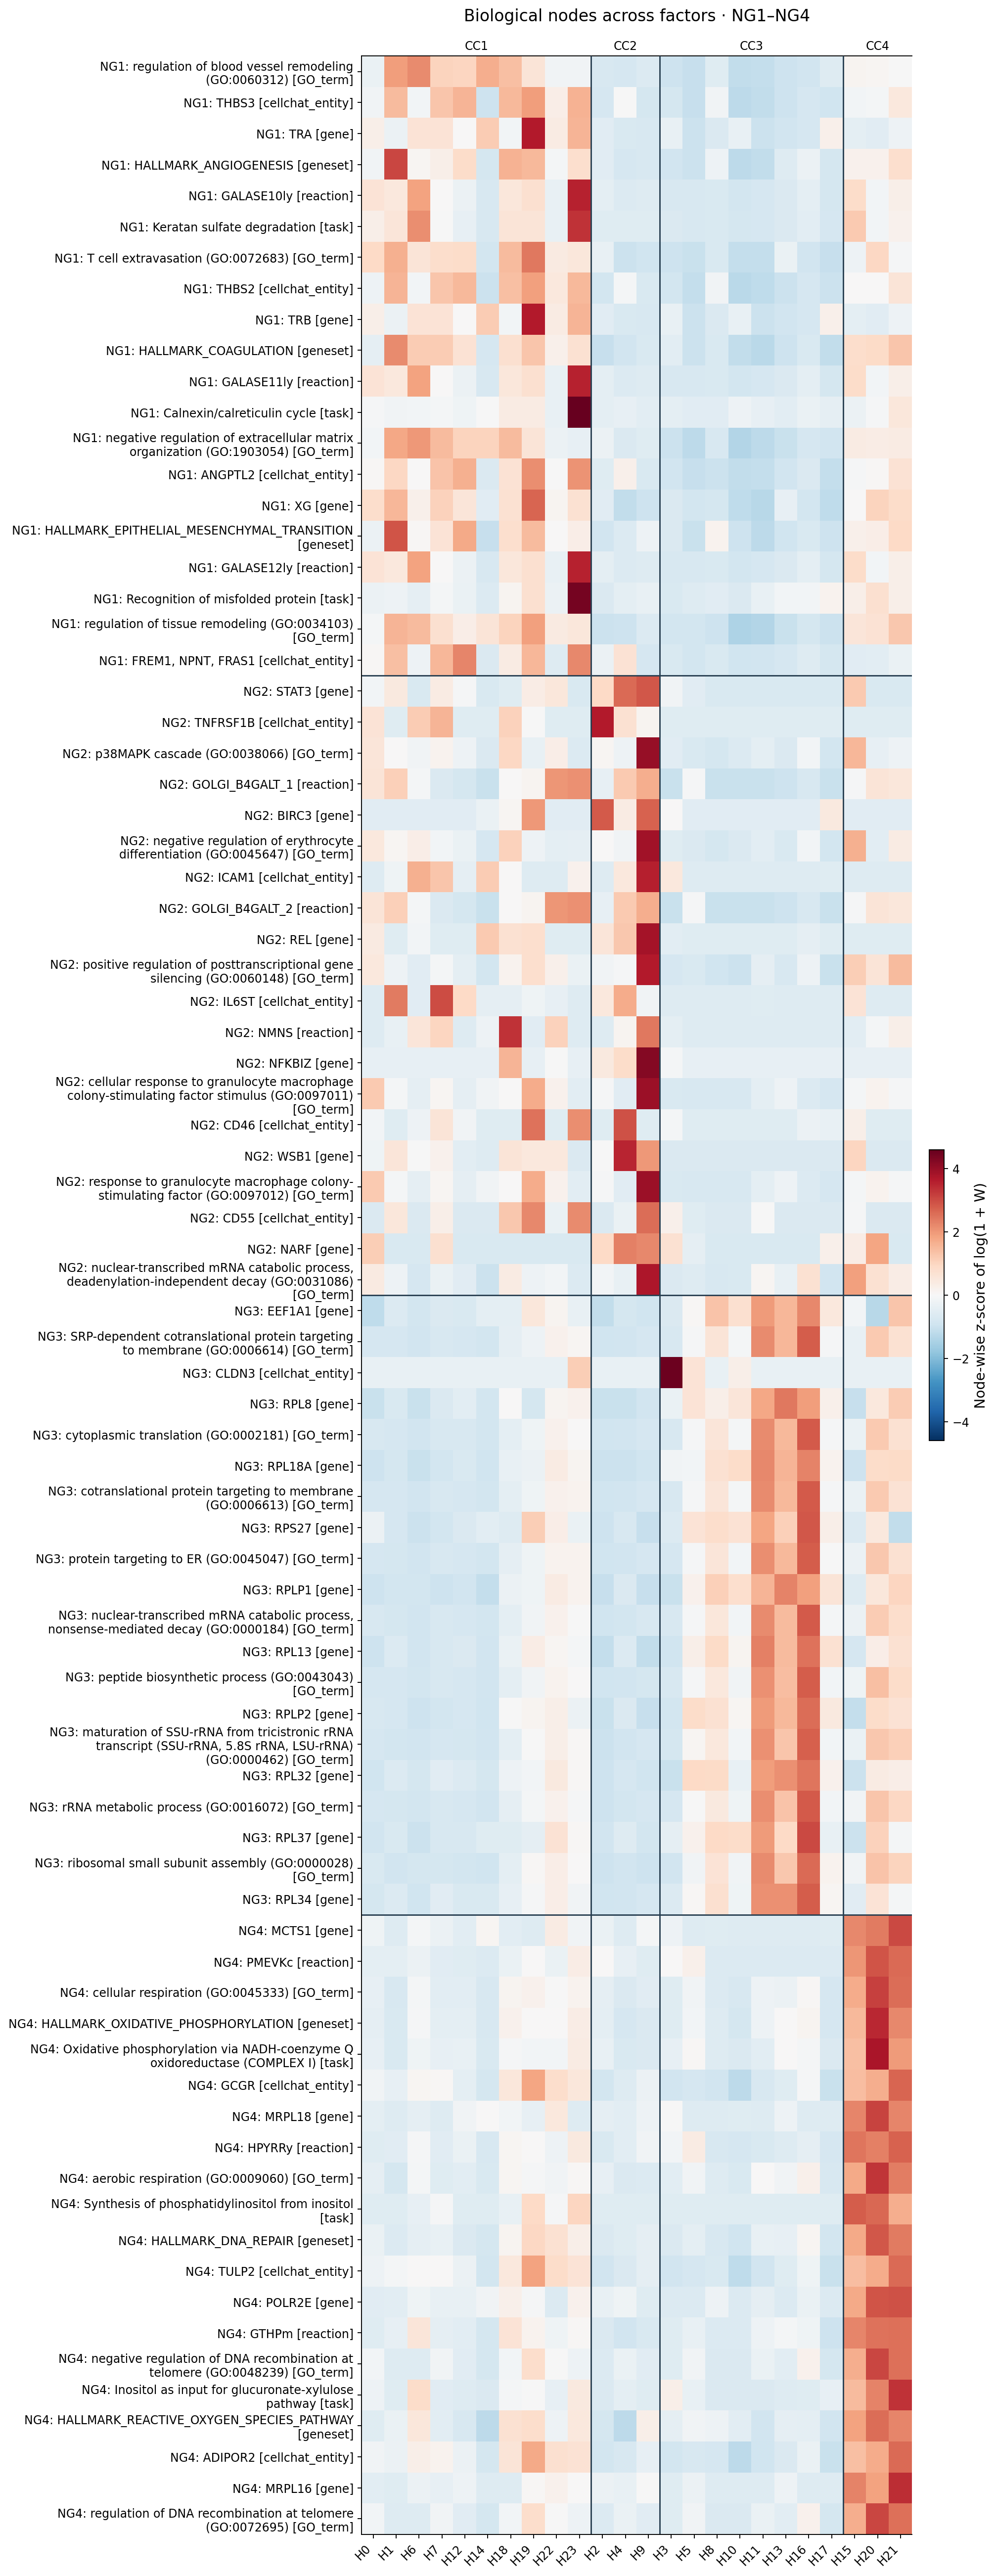

In [35]:
show_generated('factor_interpretation_k4/node_factors_all.png')

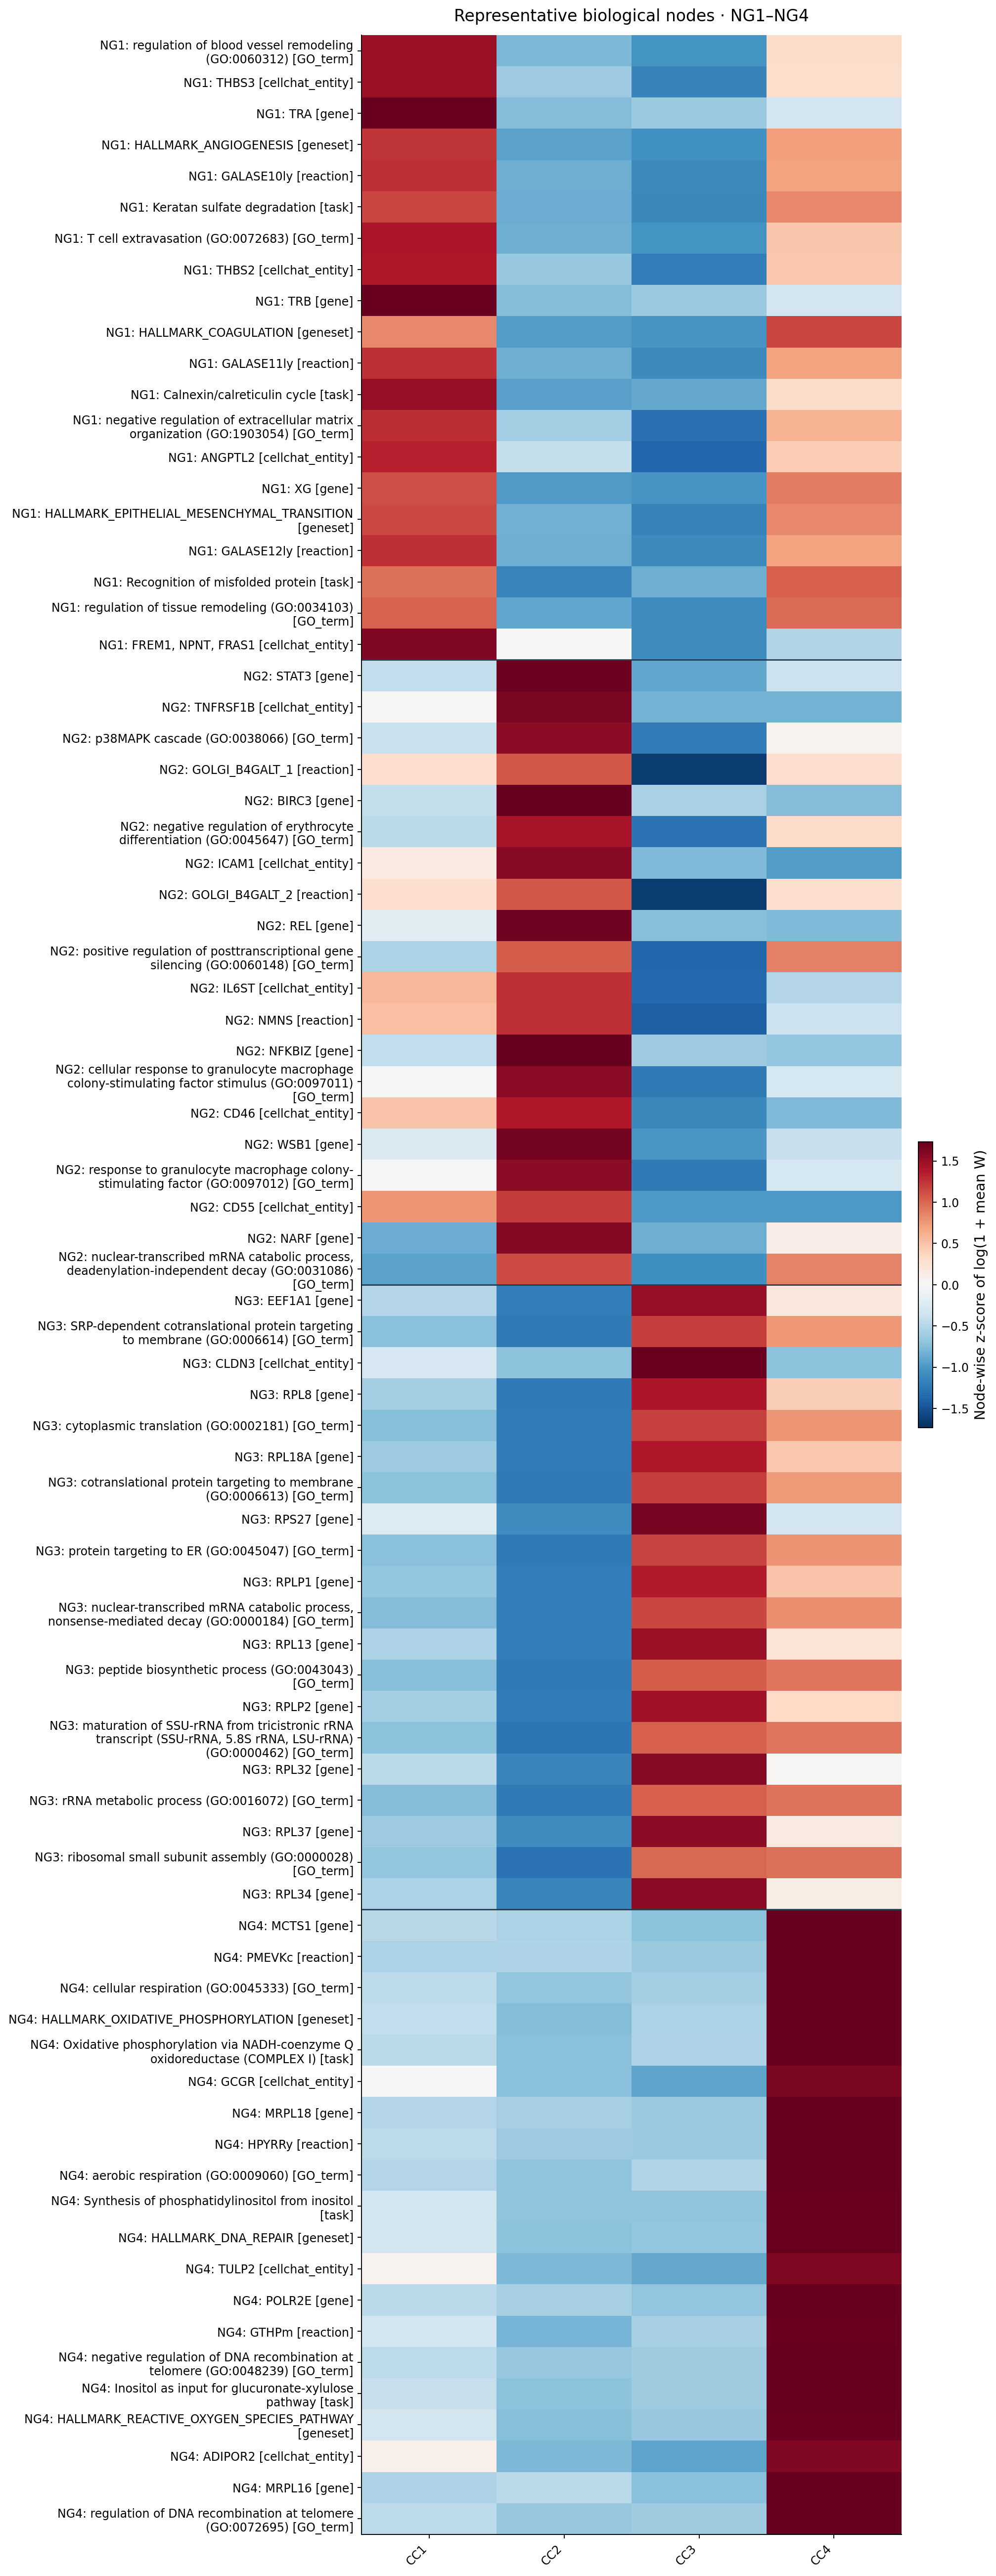

In [36]:
show_generated('factor_interpretation_k4/node_dictionary_all.png')

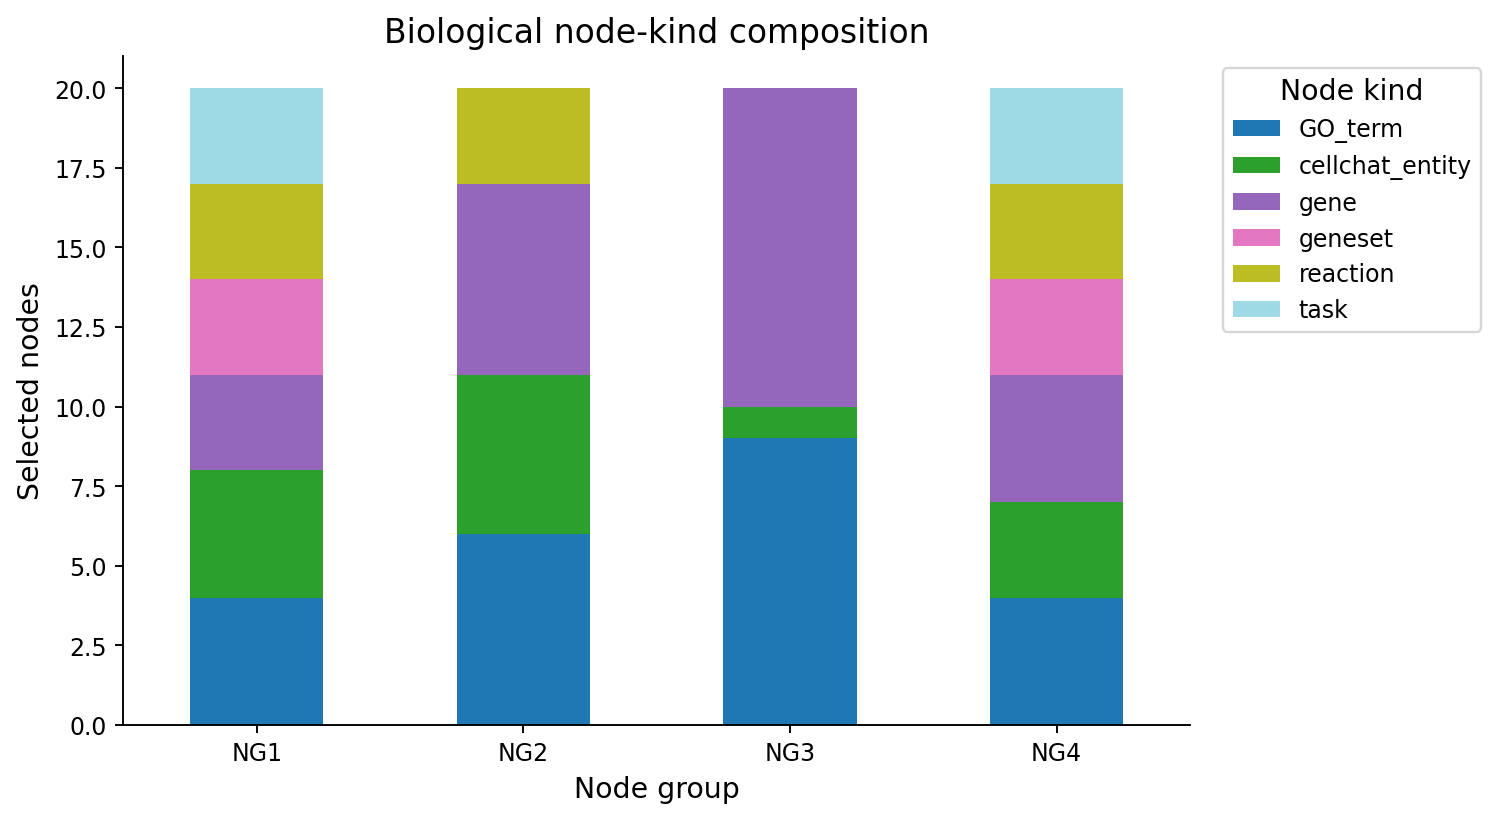

In [37]:
show_generated('factor_interpretation_k4/composition.png')

The heatmaps show standardized W loadings across individual factors and their CC means, using the same 80 nodes. Compare each row across columns. The stacked bars show how many selected nodes belong to each biological category.

## Examine category-specific loading profiles

Compare selected gene sets across the four programs. Uncomment the corresponding `entity_types.append(...)` line to generate the same view for genes, GO terms, reactions, metabolic tasks or CellChat entities. Rows are grouped by NG and columns by CC; divider lines mark the group boundaries. Node labels identify their NG membership. A group with no selected nodes of that type contributes no rows, while all factor groups remain visible.

In [38]:
# Select one entity type for the worked example.
entity_types = ['geneset']
# entity_types.append('gene')
# entity_types.append('GO_term')
# entity_types.append('reaction')
# entity_types.append('task')
# entity_types.append('cellchat_entity')
for kind in entity_types:
 rows=ranked[ranked.decay_selected & ranked.node_kind.eq(kind)]
 rows=rows.sort_values(['consensus_cluster','category_rank'])
 values=W_Z[W_ELIGIBLE.index.get_indexer(rows.node_name)][:,order]
 row_groups=rows.consensus_cluster.to_numpy()
 names=[textwrap.fill(f'{ngroups[g]}: {n}',52) for g,n in zip(row_groups,rows.node_name)]
 fig,ax=plt.subplots(figsize=(12,max(6,.36*len(rows)+2)))
 limit=max(float(np.abs(values).max()),1e-12)
 im=ax.imshow(values,aspect='auto',cmap='RdBu_r',vmin=-limit,vmax=limit)
 ax.set_yticks(range(len(rows)),names,fontsize=10)
 ax.set_xticks(range(N_FACTORS),[f'H{i}' for i in order],rotation=45,ha='right')
 for boundary in np.flatnonzero(np.diff(row_groups)!=0)+.5:
  ax.axhline(boundary,color='#273e50',lw=1.2)
 for boundary in np.flatnonzero(np.diff(labels[order])!=0)+.5:
  ax.axvline(boundary,color='#273e50',lw=1.2)
 top=ax.secondary_xaxis('top')
 centers=[np.flatnonzero(labels[order]==g).mean() for g in range(SELECTED_K)]
 top.set_xticks(centers,groups);top.tick_params(length=0)
 ax.set_title(f'{kind.replace("_"," ")} · all four programs',pad=30)
 ax.set_xlabel('Factors ordered by factor group')
 fig.colorbar(im,ax=ax,label='Node-wise z-score of log(1 + W)',fraction=.025,pad=.03)
 fig.tight_layout();save(f'category_all_{kind}')

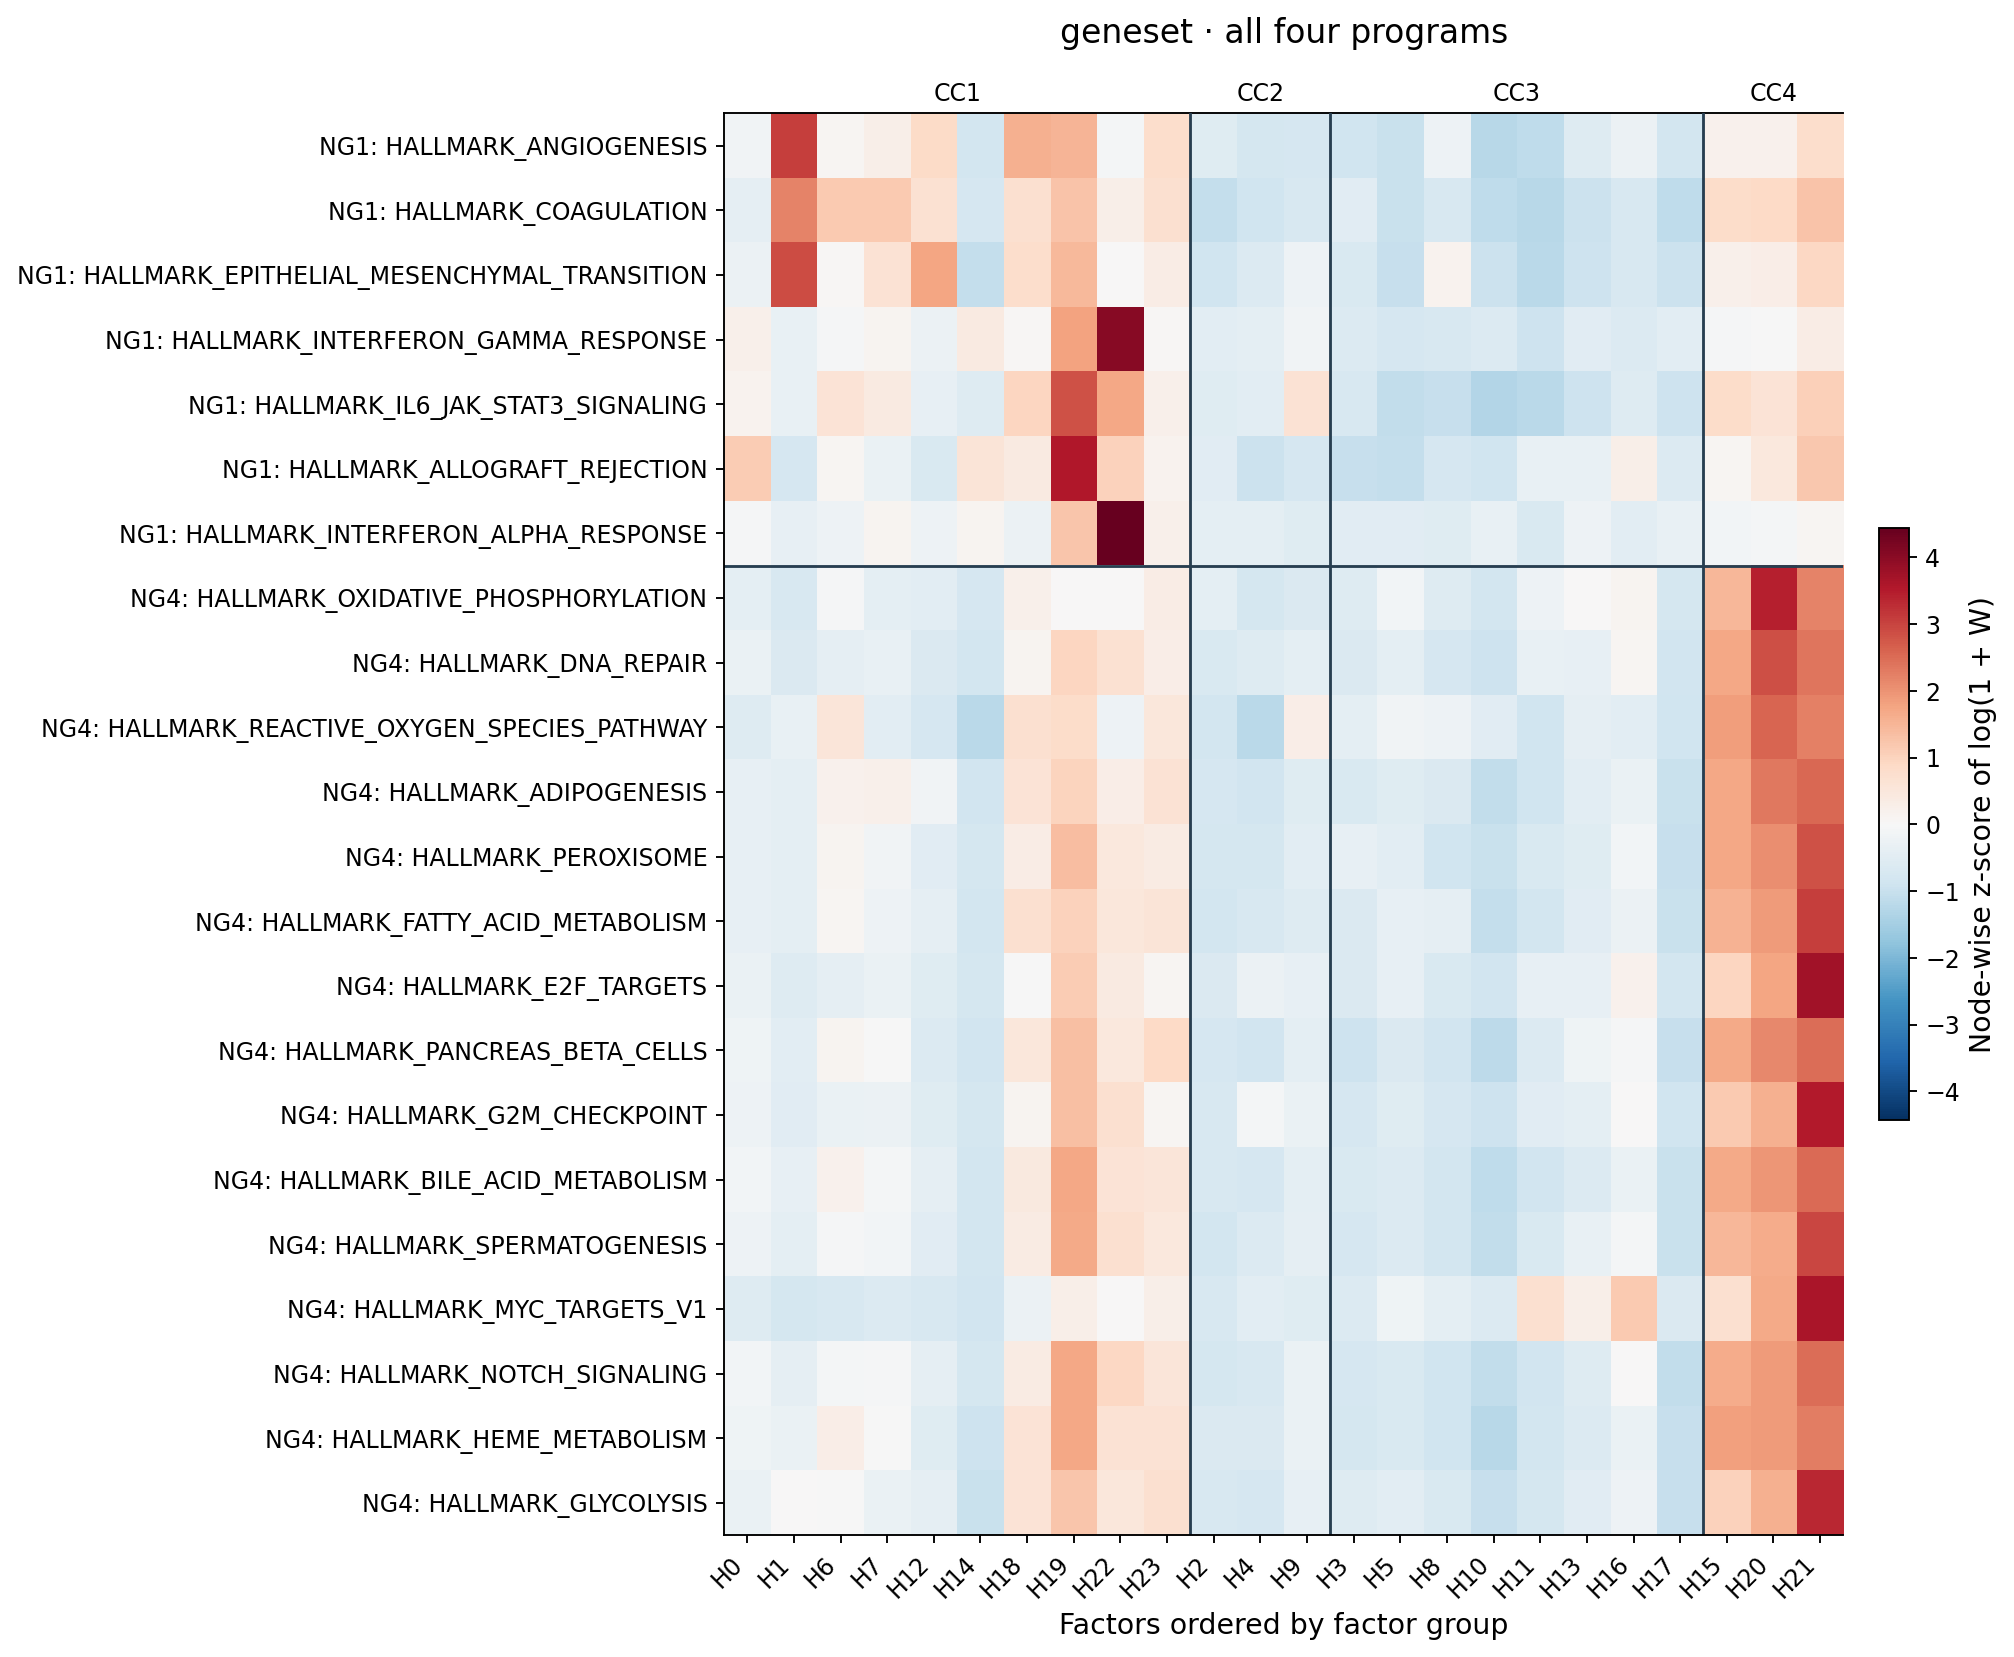

In [39]:
show_generated('factor_interpretation_k4/category_all_geneset.png')

Rows show selected gene sets grouped by NG; columns show the four CCs. Colors summarize node-wise z-scores of log(1 + W). These category-specific selections can differ from the mixed 20-node dictionary.

## Reconstruct NG activity and summarize CC activity

For each NG, average the raw W profiles of its selected nodes and multiply by H. For each CC, average the H columns assigned to that group. Then compute cell-type means and standardize log(1 + mean) across types within each row.

In [40]:
profiles=np.vstack([W[np.isin(nodes,selected.loc[selected.consensus_cluster==g,'node_name'])].mean(axis=0) for g in range(SELECTED_K)])
node_raw=H@profiles.T
factor_raw=np.column_stack([H[:,labels==g].mean(axis=1) for g in range(SELECTED_K)])
node_mean=pd.DataFrame(node_raw,index=a.obs_names,columns=ngroups).groupby(meta.cellType).mean().reindex(types).T
factor_mean=pd.DataFrame(factor_raw,index=a.obs_names,columns=groups).groupby(meta.cellType).mean().reindex(types).T
node_type=pd.DataFrame(row_z(node_mean),index=ngroups,columns=types)
factor_type=pd.DataFrame(row_z(factor_mean),index=groups,columns=types)
heat(node_type,'Reconstructed node-group activity','node_activity')
heat(factor_type,'Shared W–H factor-group activity','factor_activity')
node_mean.to_csv(OUT/'node_group_means.csv');factor_mean.to_csv(OUT/'factor_group_means.csv')

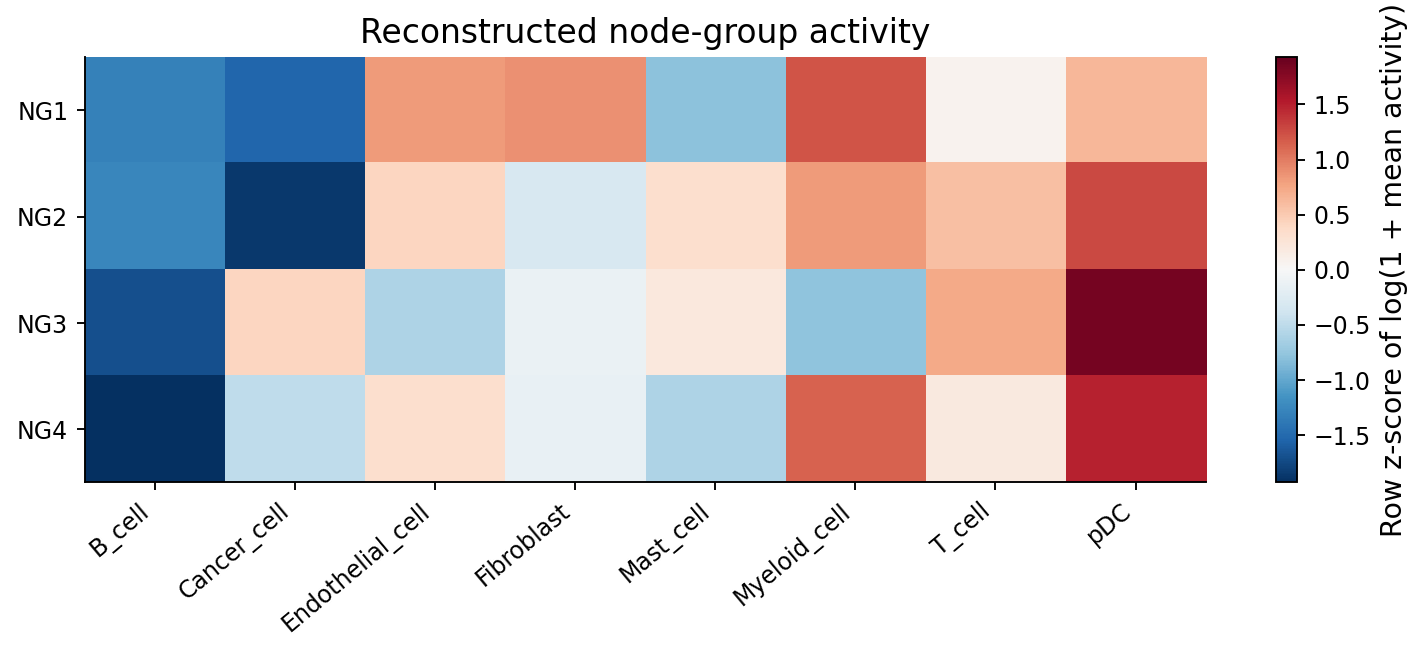

In [41]:
show_generated('factor_interpretation_k4/node_activity.png')

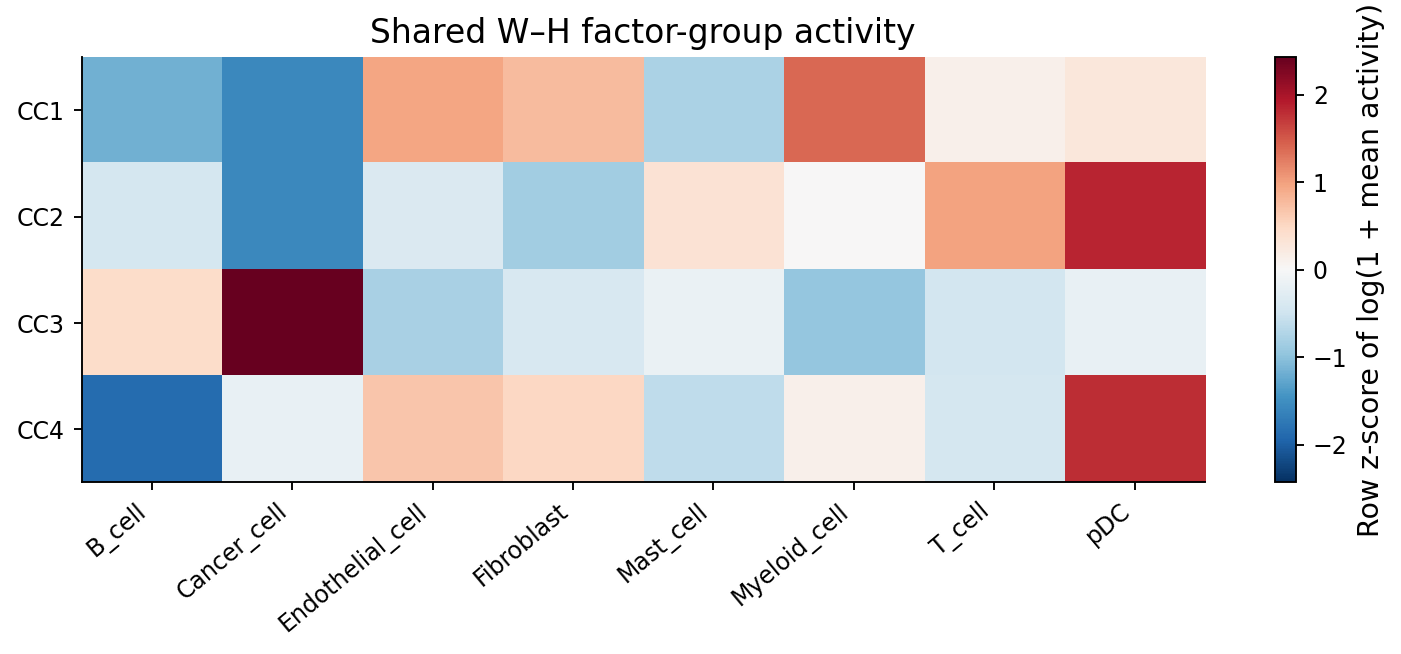

In [42]:
show_generated('factor_interpretation_k4/factor_activity.png')

The first plot shows reconstructed NG activity; the second shows CC usage. Warm colors indicate above-row-average activity across the displayed cell types. Reconstruction uses all factors, so an NG need not share the same activity pattern as its corresponding CC. 

## Connect node groups, factor groups and cell types

Connect NGs to CCs using mean standardized W summaries, and CCs to cell types using standardized mean H activity. Display all signed associations.

In [43]:
node_factor=pd.DataFrame(np.vstack([wz.loc[selected.loc[selected.consensus_cluster==g,'node_name']].mean(axis=0) for g in range(SELECTED_K)]),index=ngroups,columns=groups)
fig,ax=plt.subplots(figsize=(10,6))
ys=[np.linspace(0,1,len(x)) for x in [ngroups,groups,types]]
edges=[]
for layer,table in enumerate([node_factor,factor_type]):
 for i,src in enumerate(table.index):
  for j,dst in enumerate(table.columns):
   v=float(table.iloc[i,j]);edges.append({'source':src,'target':dst,'relative_score':v})
   ax.plot([layer,layer+1],[ys[layer][i],ys[layer+1][j]],color='#b24b55' if v>=0 else '#357eaa',lw=.3+2*abs(v),alpha=.38)
for x,names in enumerate([ngroups,groups,types]):
 ax.scatter([x]*len(names),ys[x],s=85,color='#273e50',zorder=3)
 for y,name in zip(ys[x],names):ax.text(x+.04,y,name,va='center',fontsize=11)
for x,title in enumerate(['W node groups','Shared factor groups','Source cell types']):ax.text(x,1.08,title,weight='bold')
ax.set_xlim(-.05,2.5);ax.set_ylim(-.06,1.15);ax.axis('off')
ax.legend(handles=[Patch(color='#b24b55',label='Positive relative score'),Patch(color='#357eaa',label='Negative relative score')],loc='lower center',bbox_to_anchor=(.5,-.12),ncol=2)
plt.tight_layout();save('associations');pd.DataFrame(edges).to_csv(OUT/'all_associations.csv',index=False)

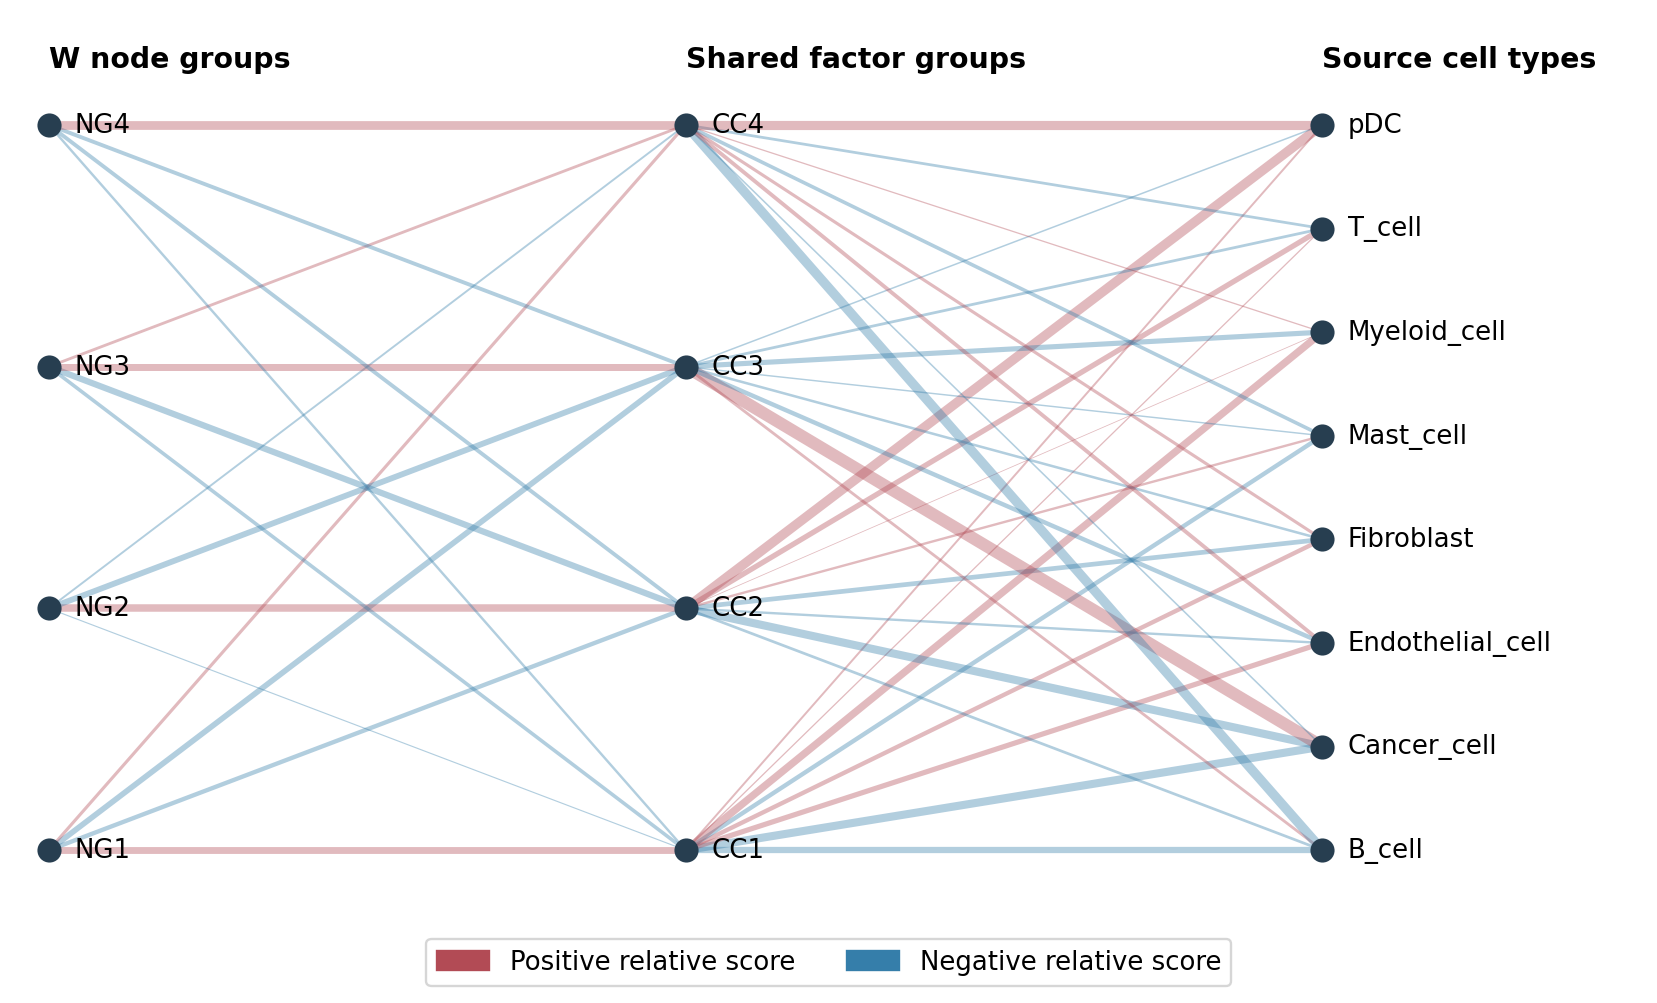

In [44]:
show_generated('factor_interpretation_k4/associations.png')

Red edges show positive relative scores and blue edges show negative scores; width scales with absolute score. The links summarize NG–CC and CC–cell-type associations. `all_associations.csv` contains every score.

## View all 10,000 cells with metadata tracks

Order cells deterministically by source cell type, patient and timepoint. Standardize log(1 + NG activity) across cells separately for each NG.

In [45]:
logged=np.log1p(node_raw);cell_z=(logged-logged.mean(axis=0))/np.maximum(logged.std(axis=0),1e-12)
ordered=meta.sort_values(['cellType','patient_id','timepoint'],kind='stable').index
positions=a.obs_names.get_indexer(ordered)
fig,axes=plt.subplots(4,1,figsize=(11,6),gridspec_kw={'height_ratios':[.25,.25,.25,3]},layout='constrained')
legend=[]
for ax,key in zip(axes[:3],['cellType','patient_id','timepoint']):
 cats=sorted(meta[key].unique());codes=pd.Categorical(meta.loc[ordered,key],categories=cats).codes
 ax.imshow(codes[None,:],aspect='auto',cmap='tab20',vmin=0,vmax=19);ax.set_yticks([0],[key]);ax.set_xticks([])
 for j,c in enumerate(cats):legend.append(Patch(color=plt.get_cmap('tab20')(j),label=f'{key}: {c}'))
im=axes[-1].imshow(cell_z[positions].T,aspect='auto',cmap='RdBu_r',vmin=-2.5,vmax=2.5)
axes[-1].set_yticks(range(SELECTED_K),ngroups);axes[-1].set_xlabel('All 10,000 cells · ordered by cell type, patient and timepoint')
fig.colorbar(im,ax=axes[-1],label='Per-group z-score of log(1 + activity)')
fig.legend(handles=legend,loc='outside lower center',ncol=4,fontsize=9);save('all_cells')

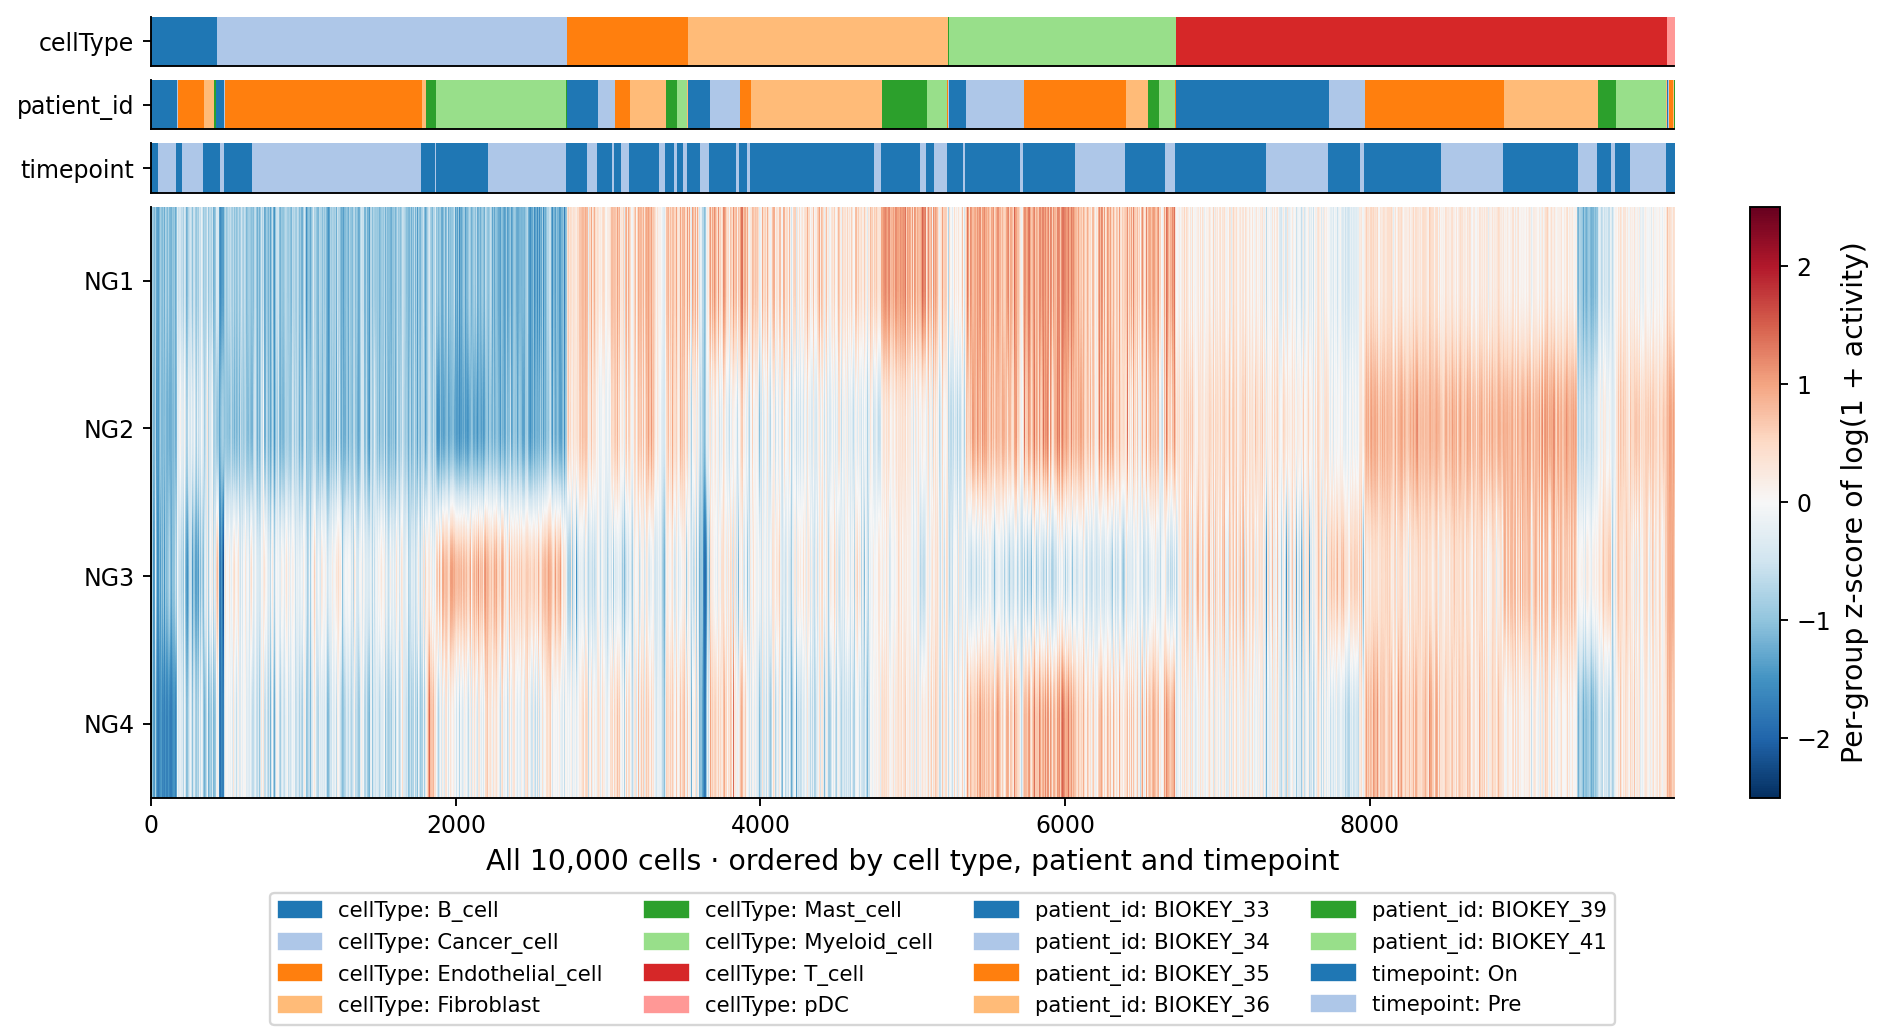

In [46]:
show_generated('factor_interpretation_k4/all_cells.png')

Every column represents one cell, ordered by cell type, patient and timepoint. Metadata strips show those groups. The activity scale is clipped at ±2.5 for display; the horizontal axis is cell order.

## Check patient representation and summarize selected constituents

Inspect sample coverage, then plot the first three ranked nodes in NG1. Change the selected group or node list to explore other constituents.

In [47]:
coverage=pd.crosstab(meta.cellType,meta.patient_id).reindex(types)
heat(coverage,'Cells available per patient and cell type','coverage','Number of cells',False)
# A declared descriptive display: first three nodes from NG1's ranked dictionary.
chosen=selected[selected.consensus_cluster==0].head(3).node_name.tolist()
fig,axes=plt.subplots(1,3,figsize=(12,5))
for ax,node in zip(axes,chosen):
 score=np.log1p(H@W[np.flatnonzero(nodes==node)[0]])
 ax.violinplot([score[meta.cellType.to_numpy()==t] for t in types],showmedians=True)
 ax.set_xticks(range(1,len(types)+1),types,rotation=60,ha='right');ax.set_title(textwrap.fill(node,28),fontsize=11)
 ax.set_ylabel('log(1 + reconstructed node activity)')
plt.tight_layout();save('constituents')
summary={'cells':a.n_obs,'factors':N_FACTORS,'selected_k':SELECTED_K,'group_sizes':np.bincount(labels).tolist(),'bootstraps':BOOTSTRAPS,'selected_nodes':len(selected),'seconds':time.time()-START,'cell_id_sha256':hashlib.sha256('\n'.join(a.obs_names).encode()).hexdigest()}
(OUT/'summary.json').write_text(json.dumps(summary,indent=2));print(summary,flush=True)

{'cells': 10000, 'factors': 24, 'selected_k': 4, 'group_sizes': [10, 3, 8, 3], 'bootstraps': 200, 'selected_nodes': 80, 'seconds': 12.570167064666748, 'cell_id_sha256': 'a47ad5d98b131c0e47129c7657dcc35515c675cddd510c60e89f986c21212d63'}


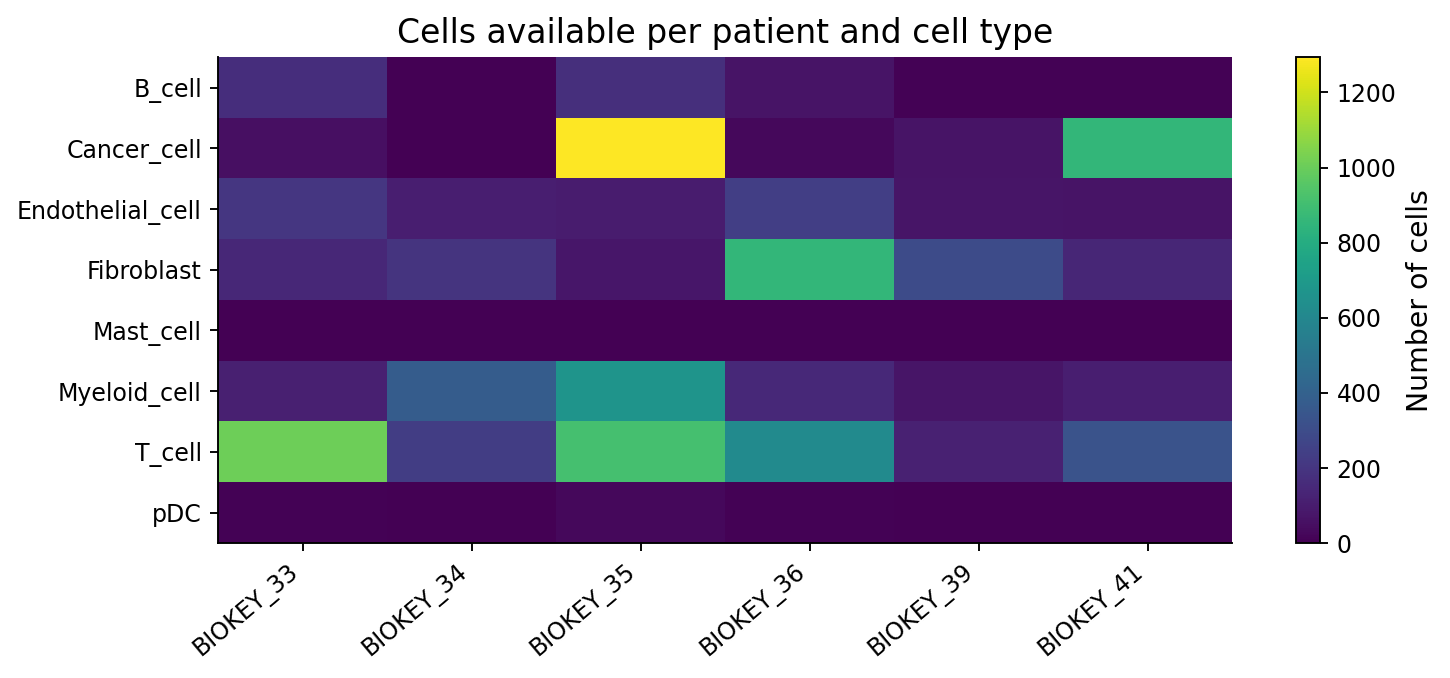

In [48]:
show_generated('factor_interpretation_k4/coverage.png')

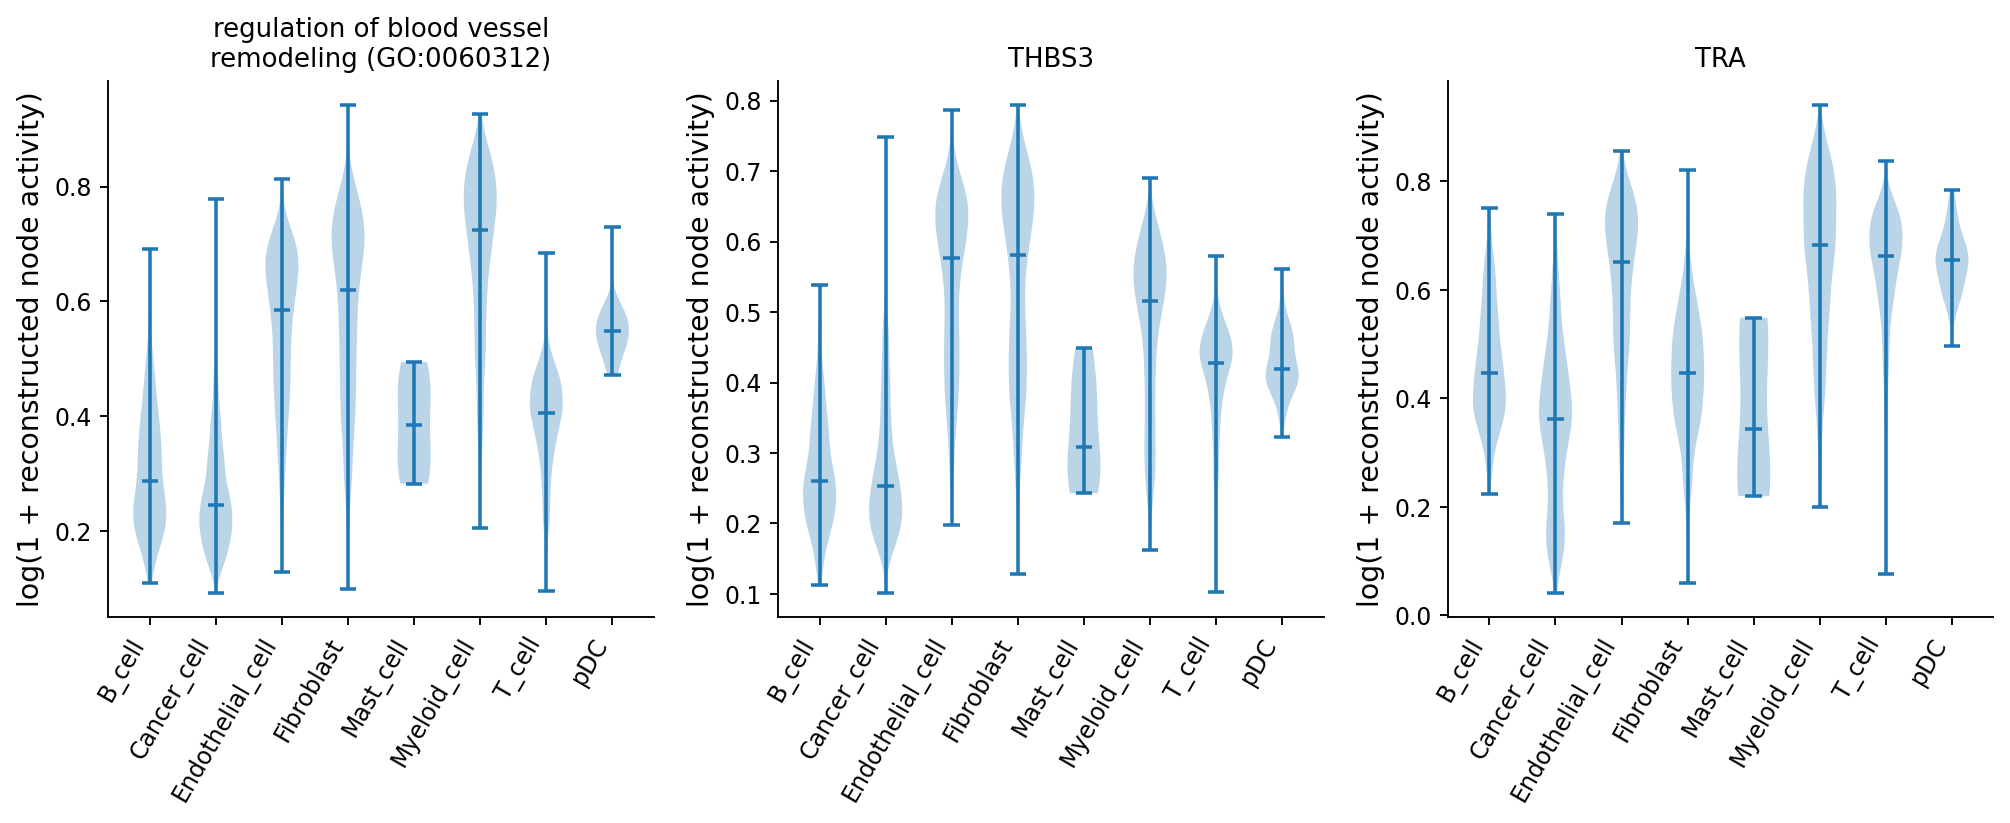

In [49]:
show_generated('factor_interpretation_k4/constituents.png')

The coverage heatmap shows cells per patient and cell type. Violins show log-transformed constituent activity with medians, pooled within each cell type. Use the group counts when interpreting sparsely represented populations.

## Outputs and next step

The `factor_interpretation_k4/` output folder contains the consensus diagnostics, factor assignments, selected-node dictionary, node-selection audit, group means, signed associations, run summary and figures. The groups and activity profiles summarize this 10,000-cell fit.

Continue to [cell–cell signaling](../docs/tutorials/10000-signaling.md).

# Cell–cell signaling



Explore activity-based signaling in seven steps: **communication overview → sender/receiver roles → ligand–receptor contributions → permutation FDR → network organization → VEGF → On-minus-Pre differences**.

Use the saved activities and source `cellType` labels from the [10,000-cell fit](../docs/tutorials/10000-setup.md). Signaling scores summarize reconstructed activities using directional ligand–receptor definitions; they are not CellChat probabilities. [Download the complete runnable script](../docs/downloads/signaling_walkthrough.py).

Set `SCKNIFE_INTERACTION_DB` to the directional interaction export described in [Input files](../docs/tutorial-inputs.md). The interaction export supplies directional ligand–receptor definitions alongside the fitted activities.

## Load and validate signaling inputs

In [50]:
"""Descriptive signaling for the fitted 10,000 cells; no patient or condition tests."""
import os,time,json,hashlib,resource,textwrap
from pathlib import Path
os.environ['MPLBACKEND']='Agg'
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt

# Consistent, readable figure typography.
plt.rcParams.update({"font.size": 12, "axes.titlesize": 14,
                     "axes.labelsize": 12, "xtick.labelsize": 11,
                     "ytick.labelsize": 11, "legend.fontsize": 11,
                     "figure.titlesize": 15, "axes.spines.top": False,
                     "axes.spines.right": False})
from scknife.signaling import activity_lr as lr
from scknife.signaling import common
start=time.perf_counter()
root=Path.cwd();base=Path(os.environ.get('SCKNIFE_TUTORIAL_OUTPUT', root/'tutorial/outputs_10000'));out=base/'signaling';out.mkdir(exist_ok=True)
db_path=Path(os.environ['SCKNIFE_INTERACTION_DB'])
for mod in (lr,common):
 mod.ACTIVITY_PATH=base/'activity_scores.parquet';mod.CELLCHAT_DB_PATH=db_path
adata=sc.read_h5ad(base/'fitted_subset.h5ad')
assert adata.n_obs==10000
metadata=adata.obs.copy();key='cellType'
assert key in metadata and not metadata[key].isna().any()
db,wanted=lr.load_interactions()
_,nodes,cells=lr.activity_schema()
assert cells==list(adata.obs_names)
values,genes,coverage=lr.stream_activity_subset(wanted,nodes,cells,256)
groups=sorted(metadata[key].astype(str).unique());assert len(groups)>1
labels=metadata[key].astype(str).map({g:i for i,g in enumerate(groups)}).to_numpy(dtype=np.int16)
means,counts=lr.group_means(values,labels,len(groups));specificity=means/(means.mean(axis=1)[:,None]+1e-10)
pairs=lr.build_pairs(db,genes,means);error=lr.validate_vectorization(means,specificity,pairs)
comm=lr.communication_matrix(means,specificity,pairs);assert np.isfinite(comm).all() and (comm>=0).all()
details=lr.interaction_details(means,specificity,pairs,groups)
reconstructed=details.pivot_table(index='source',columns='target',values='weighted_score',aggfunc='sum',fill_value=0).reindex(index=groups,columns=groups,fill_value=0)
assert np.allclose(comm,reconstructed.to_numpy(),rtol=1e-10,atol=1e-10)
pd.DataFrame(comm,index=groups,columns=groups).to_csv(out/'communication_matrix.csv')
details.to_csv(out/'interaction_details.csv.gz',index=False,compression='gzip')
pd.DataFrame({'reference_cell_type':groups,'cells':counts}).to_csv(out/'group_counts.csv',index=False)
pairs.to_csv(out/'matched_interaction_components.csv',index=False)

  activity columns 256/10,000


  activity columns 512/10,000


  activity columns 768/10,000


  activity columns 1,024/10,000


  activity columns 1,280/10,000


...

  activity columns 9,216/10,000


  activity columns 9,472/10,000


  activity columns 9,728/10,000


  activity columns 9,984/10,000


  activity columns 10,000/10,000


The code aligns cells with the saved fit and checks that interaction scores sum to the group matrix. Scores combine group means with group-normalized specificity. Check the group counts when interpreting small populations.

## 1. Sender–receiver activity heatmap

In [51]:
fig,ax=plt.subplots(figsize=(7,6));im=ax.imshow(comm,cmap='viridis',aspect='auto')
ax.set_xticks(range(len(groups)));ax.set_xticklabels([textwrap.fill(g,16) for g in groups],rotation=35,ha='right')
ax.set_yticks(range(len(groups)));ax.set_yticklabels([textwrap.fill(g,20) for g in groups])
ax.set_xlabel('Receiver source cell type');ax.set_ylabel('Sender source cell type')
ax.set_title('Descriptive communication scores · 10,000 cells');fig.colorbar(im,ax=ax,label='Weighted activity score')
fig.tight_layout();fig.savefig(out/'signaling_heatmap.png',dpi=160,bbox_inches='tight');plt.close(fig)

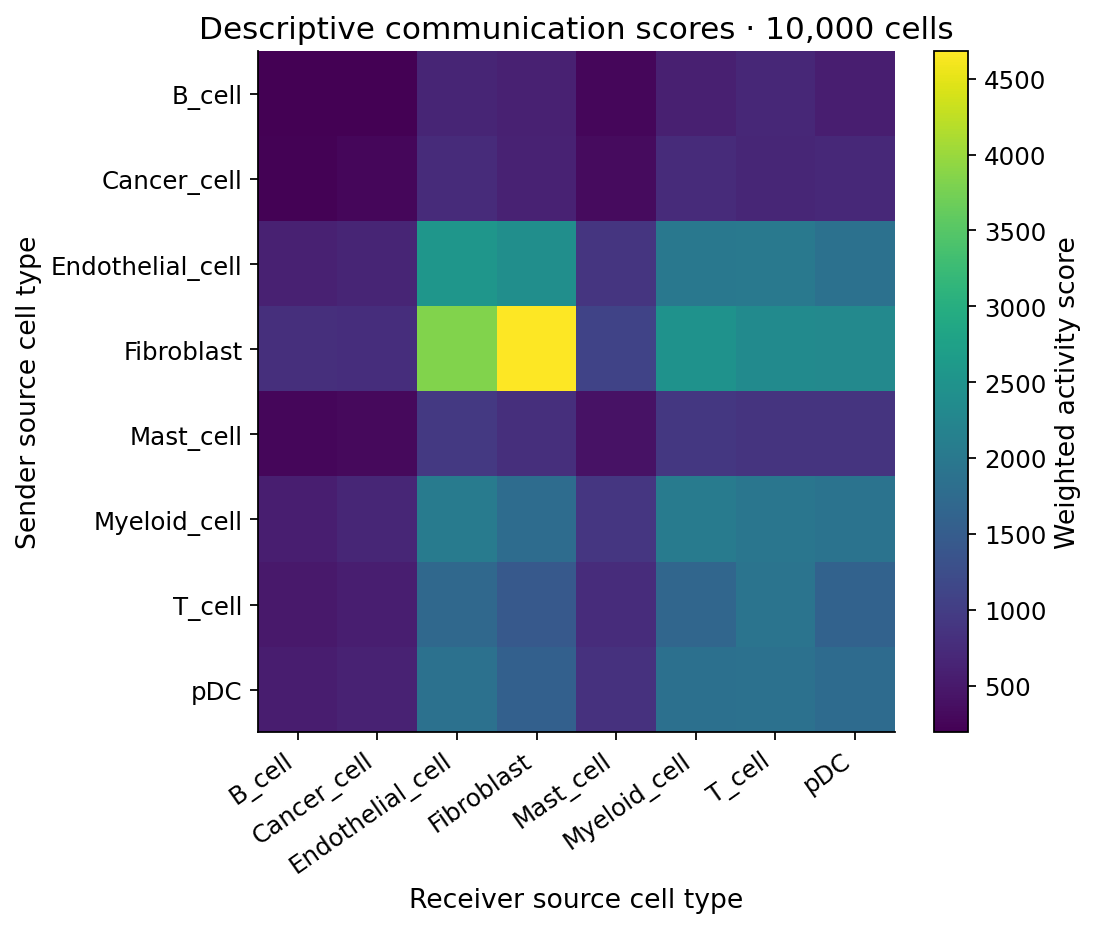

In [52]:
show_generated('signaling/signaling_heatmap.png')

Rows are sender cell types and columns are receivers. Color shows summed interaction scores, including self-links. Use the FDR plot in step 4 to inspect statistical support.

## 2. Outgoing and incoming signaling strength

In [53]:
from scknife.signaling import plotting as plots

# Consistent, readable figure typography.
plt.rcParams.update({"font.size": 12, "axes.titlesize": 14,
                     "axes.labelsize": 12, "xtick.labelsize": 11,
                     "ytick.labelsize": 11, "legend.fontsize": 11,
                     "figure.titlesize": 15, "axes.spines.top": False,
                     "axes.spines.right": False})
plots.NODE_LABEL_SIZE_PT = 11
plots.TOP_LR_PAIRS = 15
plots.OUTPUT_DPI = 180
comm = pd.DataFrame(comm, index=groups, columns=groups)
general = out / 'general'

plots.plot_sender_receiver(comm, general)
# plots.plot_flow(comm, general)  # Optional dominant-flow view.

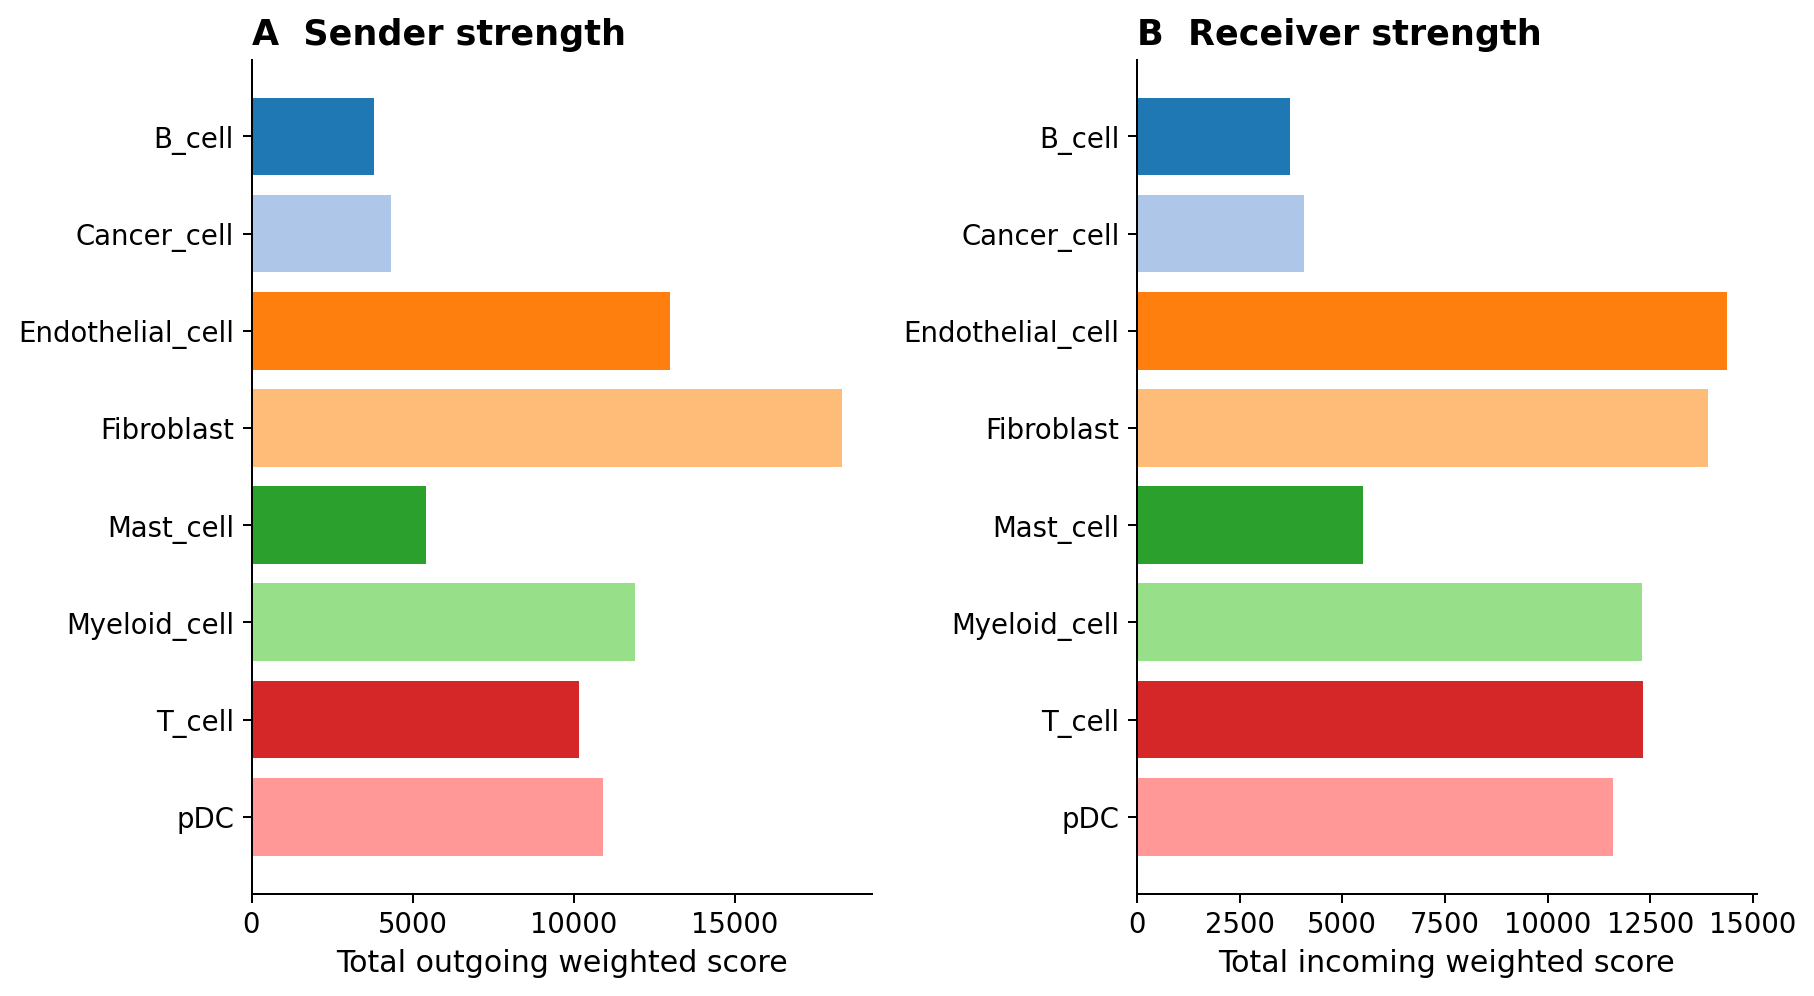

In [54]:
show_generated('signaling/general/01_sender_receiver.png')

Outgoing strength sums each row of the communication matrix; incoming strength sums each column. Both include self-links. These summarize scores rather than cell counts and identify prominent senders and receivers under the scoring model.

## 3. Ligand–receptor contributions

In [55]:
# Aggregate database components with identical ligand/receptor labels for display.
totals=details.groupby(['ligand','receptor'],sort=True).weighted_score.sum().sort_values(ascending=False,kind='stable').head(10)
contexts=details.groupby(['source','target'],sort=True).weighted_score.sum().sort_values(ascending=False,kind='stable').head(6)
agg=details.groupby(['ligand','receptor','source','target'],sort=True).weighted_score.sum()
rows=[]
for y,(lig,rec) in enumerate(totals.index):
 for x,(sender,receiver) in enumerate(contexts.index):
  score=float(agg.get((lig,rec,sender,receiver),0))
  rows.append(dict(ligand=lig,receptor=rec,source=sender,target=receiver,score=score,x=x,y=y))
bubbles=pd.DataFrame(rows);bubbles.to_csv(out/'selected_lr_bubbles.csv',index=False)
fig,ax=plt.subplots(figsize=(10,8));positive=bubbles[bubbles.score>0];sizes=280*positive.score/positive.score.max()
scat=ax.scatter(positive.x,positive.y,s=sizes,c=np.log1p(positive.score),cmap='viridis',edgecolors='gray',linewidths=.3)
ax.set_xticks(range(len(contexts)));ax.set_xticklabels([textwrap.fill(a,17)+'\n→\n'+textwrap.fill(b,17) for a,b in contexts.index],fontsize=11)
ax.set_yticks(range(len(totals)));ax.set_yticklabels([a+' → '+b for a,b in totals.index],fontsize=11);ax.invert_yaxis()
ax.set_xlabel('Sender → receiver source cell types');ax.set_ylabel('Ligand → receptor component')
ax.set_title('Top 10 ligand–receptor components in 6 strongest group pairs')
fig.colorbar(scat,ax=ax,label='log(1 + weighted score)')
fig.text(.5,.01,'Bubble area is proportional to weighted score; no significance test is shown.',ha='center',fontsize=11)
fig.tight_layout(rect=(0,.04,1,1));fig.savefig(out/'signaling_lr_bubbles.png',dpi=160,bbox_inches='tight');plt.close(fig)
# plots.plot_bubble(details, groups, general)  # Alternative group-pair overview.
# plots.plot_top_lr(details, general)  # Alternative pooled ligand–receptor ranking.

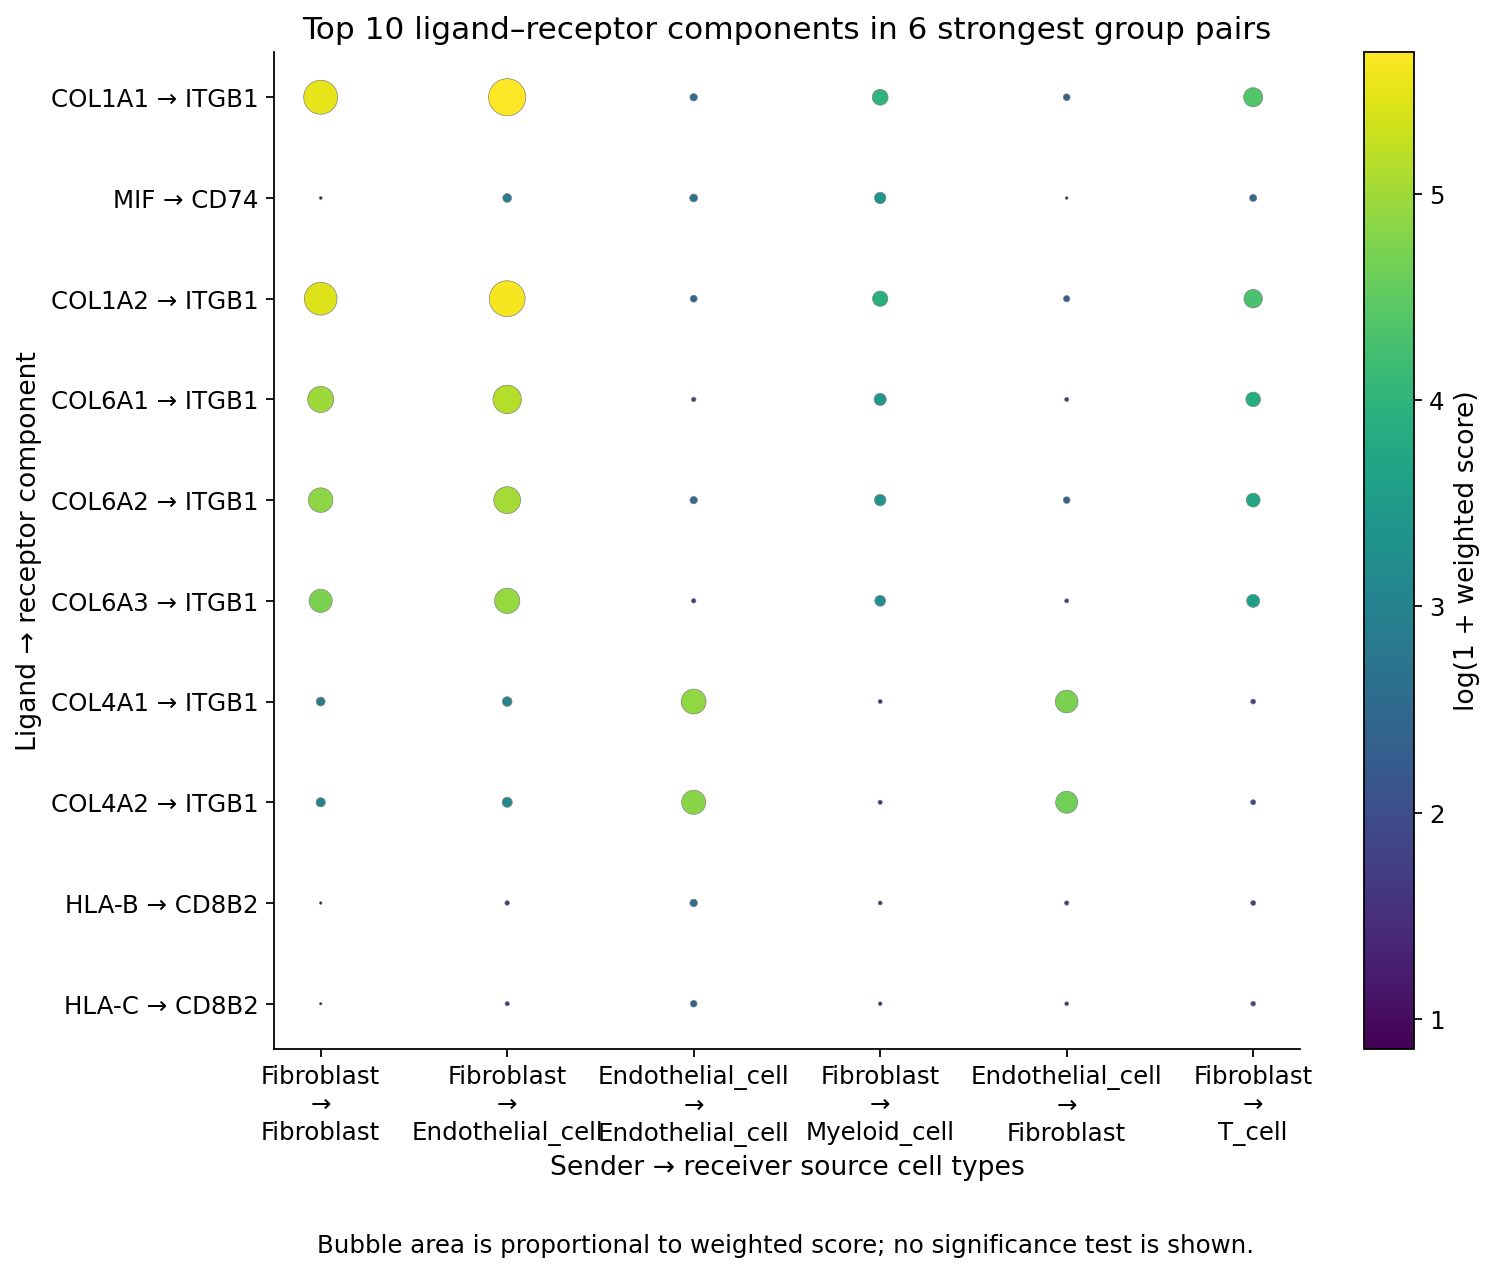

In [56]:
show_generated('signaling/signaling_lr_bubbles.png')

The ten highest-scoring ligand–receptor components and six strongest sender–receiver contexts are selected by pooled score. Bubble area represents score and color represents log(1 + score); neither represents FDR. The plot identifies interactions contributing to the group-level summaries.

## 4. Cell-label permutation FDR

Run or resume 1,000 global cell-label permutations with observed specificity held fixed. The null preserves group sizes. Apply Benjamini–Hochberg correction across all 64 sender–receiver pairs.

In [57]:
from pathlib import Path
import os,json,hashlib
import numpy as np
import pandas as pd
import scanpy as sc
import networkx as nx
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from statsmodels.stats.multitest import multipletests
from scknife.signaling import activity_lr as lr, common
base=Path(os.environ.get('SCKNIFE_TUTORIAL_OUTPUT','tutorial/outputs_10000'))
out=base/'signaling'/'inference';out.mkdir(parents=True,exist_ok=True)
for mod in (lr,common):
 mod.ACTIVITY_PATH=base/'activity_scores.parquet'
 mod.CELLCHAT_DB_PATH=Path(os.environ['SCKNIFE_INTERACTION_DB'])
 mod.DATA_DIR=out
adata=sc.read_h5ad(base/'fitted_subset.h5ad');meta=adata.obs.copy()
assert len(meta)==10000 and meta.index.is_unique
print(meta[['timepoint','expansion']].value_counts(dropna=False),flush=True)
db,wanted=lr.load_interactions();_,nodes,cells=lr.activity_schema()
assert cells==list(meta.index)
values,genes,coverage=lr.stream_activity_subset(wanted,nodes,cells,256)
groups=sorted(meta.cellType.astype(str).unique());labels=meta.cellType.astype(str).map({g:i for i,g in enumerate(groups)}).to_numpy(dtype=np.int16)
means,counts=lr.group_means(values,labels,len(groups));specificity=means/(means.mean(axis=1)[:,None]+1e-10)
pairs=lr.build_pairs(db,genes,means);observed=lr.communication_matrix(means,specificity,pairs)
saved=pd.read_csv(base/'signaling/communication_matrix.csv',index_col=0).loc[groups,groups]
assert np.allclose(observed,saved.to_numpy())
# Cell-label null; keep observed specificity fixed, matching the package method.
sig=hashlib.sha256(labels.tobytes()+json.dumps(groups).encode()).hexdigest()
pvalues,completed=lr.run_permutations(values,labels,observed,specificity,pairs,len(groups),1000,50,False,sig)
fdr=multipletests(pvalues.ravel(),method='fdr_bh')[1].reshape(pvalues.shape)
for name,v in [('communication_pvalues',pvalues),('communication_fdr',fdr)]:pd.DataFrame(v,index=groups,columns=groups).to_csv(out/(name+'.csv'))
def heatmap(v,title,filename,label,diverging=False):
 fig,ax=plt.subplots(figsize=(9,7));cmap=plt.get_cmap('RdBu_r' if diverging else 'viridis').copy();cmap.set_bad('#dddddd')
 bound=max(float(np.nanmax(np.abs(v))),1e-12)
 im=ax.imshow(v,cmap=cmap,aspect='auto',vmin=-bound if diverging else 0,vmax=bound)
 ax.set_xticks(range(len(groups)),groups,rotation=40,ha='right');ax.set_yticks(range(len(groups)),groups)
 ax.set_xlabel('Receiver cell type');ax.set_ylabel('Sender cell type');ax.set_title(title)
 fig.colorbar(im,ax=ax,label=label);fig.tight_layout();fig.savefig(out/filename,dpi=170);plt.close(fig)


heatmap(-np.log10(fdr),'Cell-label permutation FDR · 1,000 permutations','permutation_fdr.png','−log10(BH-adjusted p-value)')

timepoint  expansion
On         E            3818
Pre        E            3106
On         NE           1885
Pre        NE           1191
Name: count, dtype: int64


  activity columns 256/10,000


  activity columns 512/10,000


  activity columns 768/10,000


  activity columns 1,024/10,000


...

  permutations 800/1000 (91.76/s since process start)


  permutations 850/1000 (91.79/s since process start)


  permutations 900/1000 (91.82/s since process start)


  permutations 950/1000 (91.82/s since process start)


  permutations 1000/1000 (91.83/s since process start)


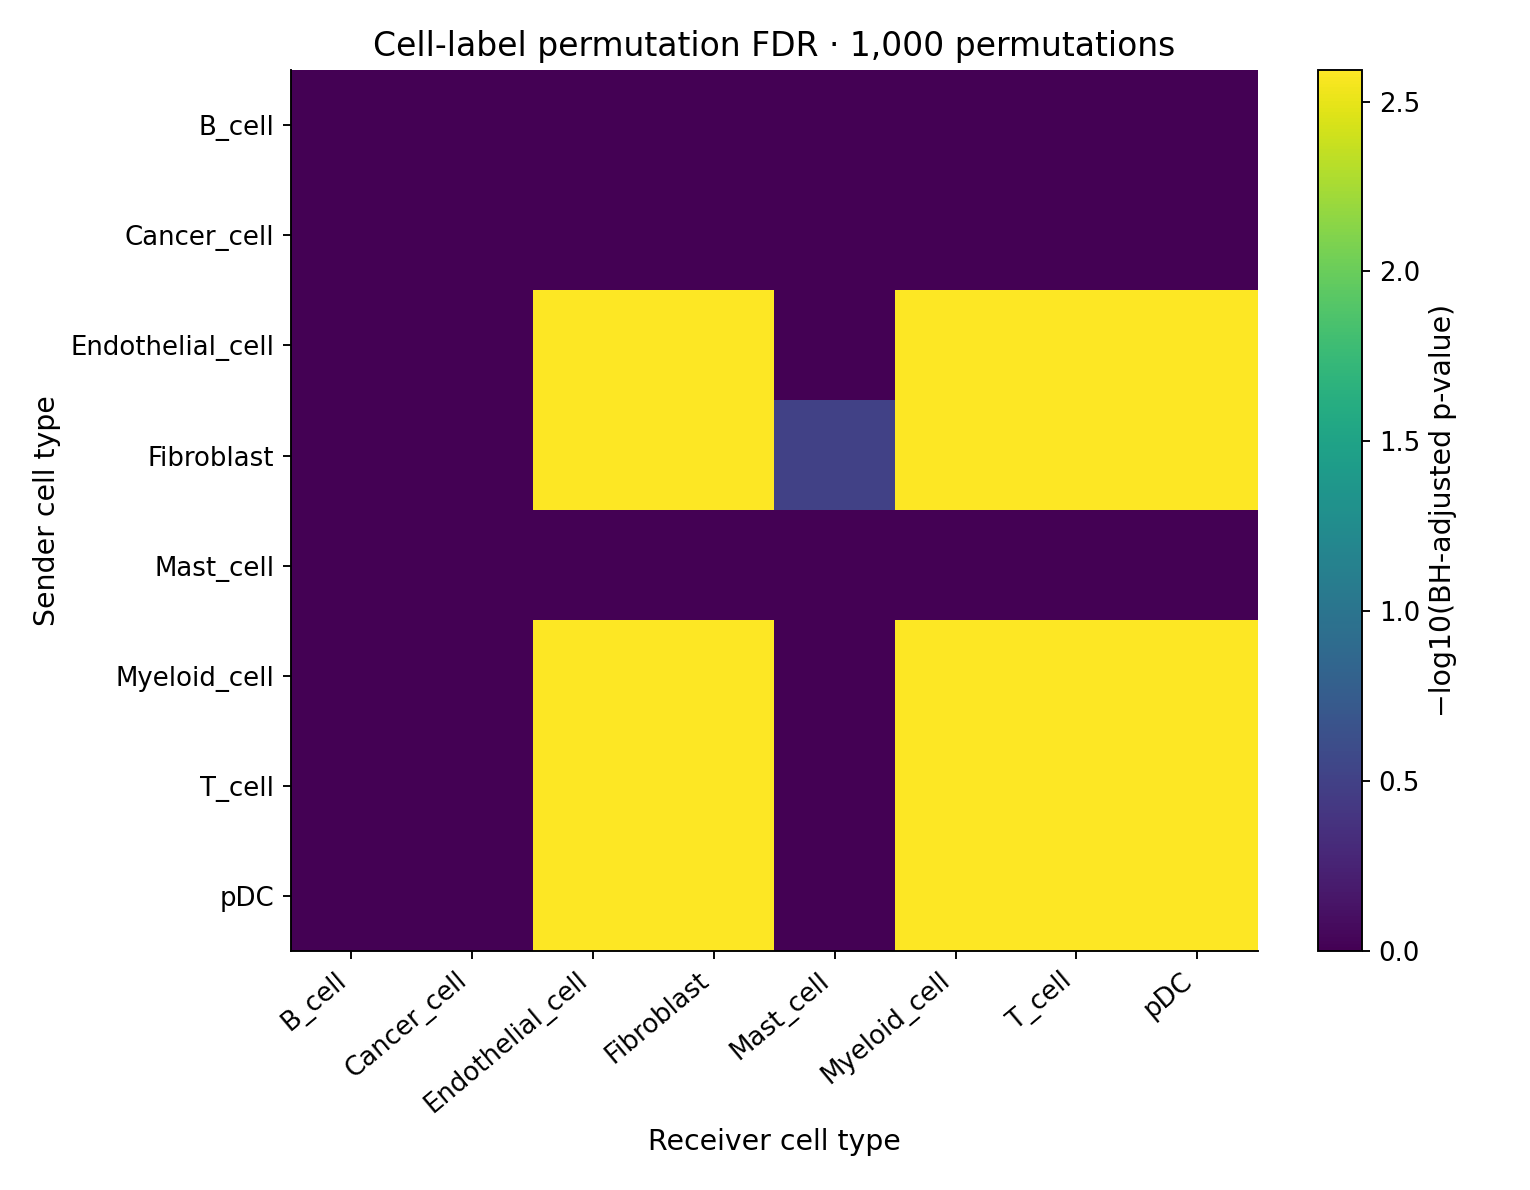

In [58]:
show_generated('signaling/inference/permutation_fdr.png')

Color shows −log10 of the BH-adjusted p-value for the 64 sender–receiver totals. These global cell-label permutations preserve group sizes but do not block by patient. The FDR applies to these totals, not individual interactions or treatment contrasts; 1,000 permutations give a minimum unadjusted p-value of 1/1,001.

## 5. Network organization and centrality

In [59]:
plots.plot_network(comm, general, title='Cell-type communication network')

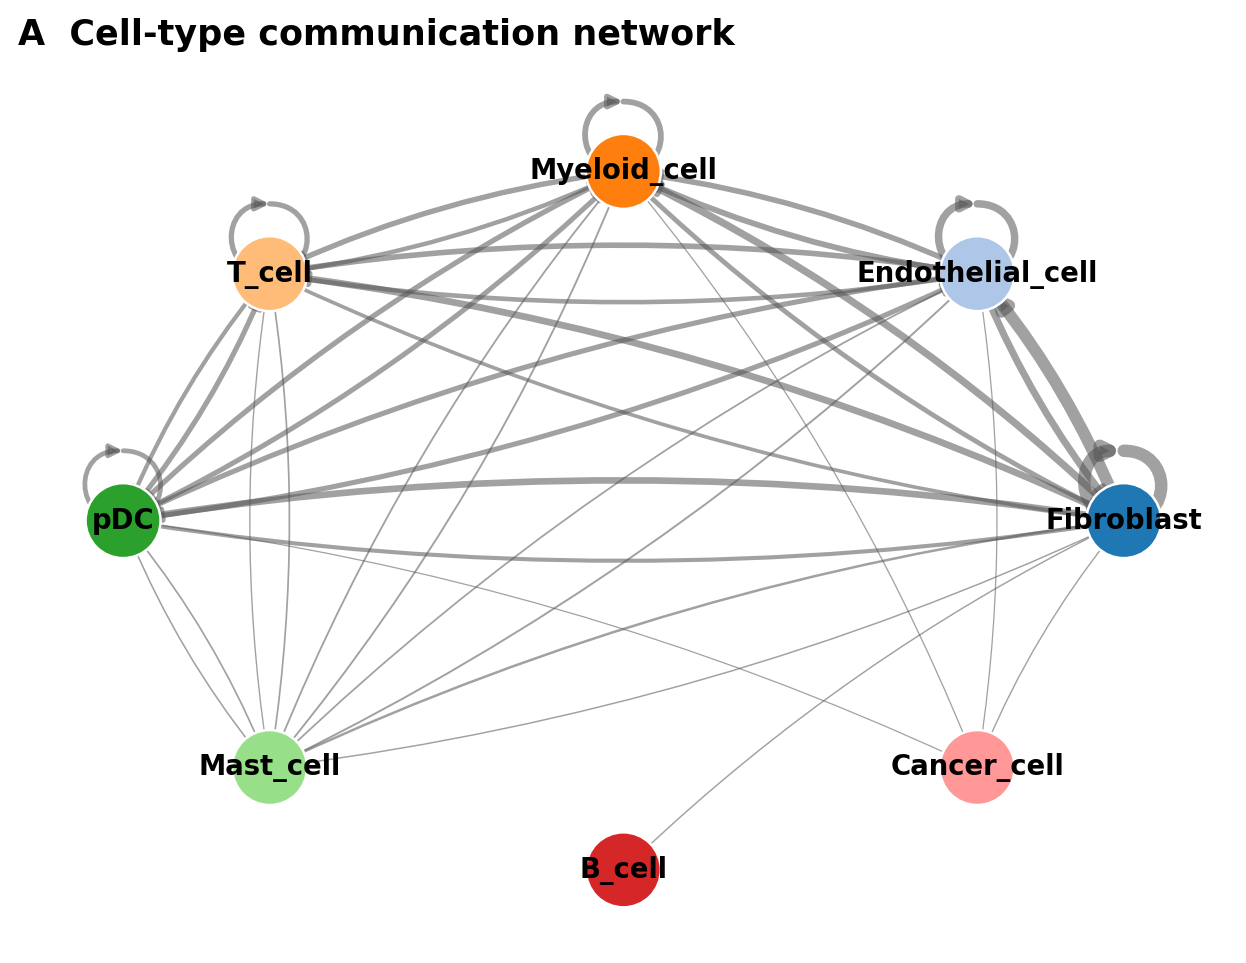

In [60]:
show_generated('signaling/general/06_hierarchical_network.png')

Arrows show direction for up to 40 positive links; widths use the 2nd–98th score percentiles. Circular positions arrange the network for display. Other positive links remain in the exported matrix.

In [61]:
# Network centrality: omit self-links; stronger edges have shorter inverse-score distances.
g=nx.DiGraph();g.add_nodes_from(groups)
for i,a in enumerate(groups):
 for j,b in enumerate(groups):
  if i!=j and observed[i,j]>0:g.add_edge(a,b,weight=float(observed[i,j]),distance=1/float(observed[i,j]))
between=nx.betweenness_centrality(g,weight='distance',normalized=True)
rank=nx.pagerank(g,weight='weight')
central=pd.DataFrame({'cell_type':groups,'outgoing_strength':[g.out_degree(a,weight='weight') for a in groups],'incoming_strength':[g.in_degree(a,weight='weight') for a in groups],'betweenness':[between[a] for a in groups],'pagerank':[rank[a] for a in groups]}).set_index('cell_type')
central.to_csv(out/'network_centrality.csv')
fig,axes=plt.subplots(2,2,figsize=(14,10))
for ax,col in zip(axes.flat,central):
 ax.barh(groups,central[col]);ax.invert_yaxis();ax.set_title(col.replace('_',' ').title());ax.set_xlabel('Score')
fig.suptitle('Descriptive centrality · self-links excluded');fig.tight_layout();fig.savefig(out/'network_centrality.png',dpi=170);plt.close(fig)

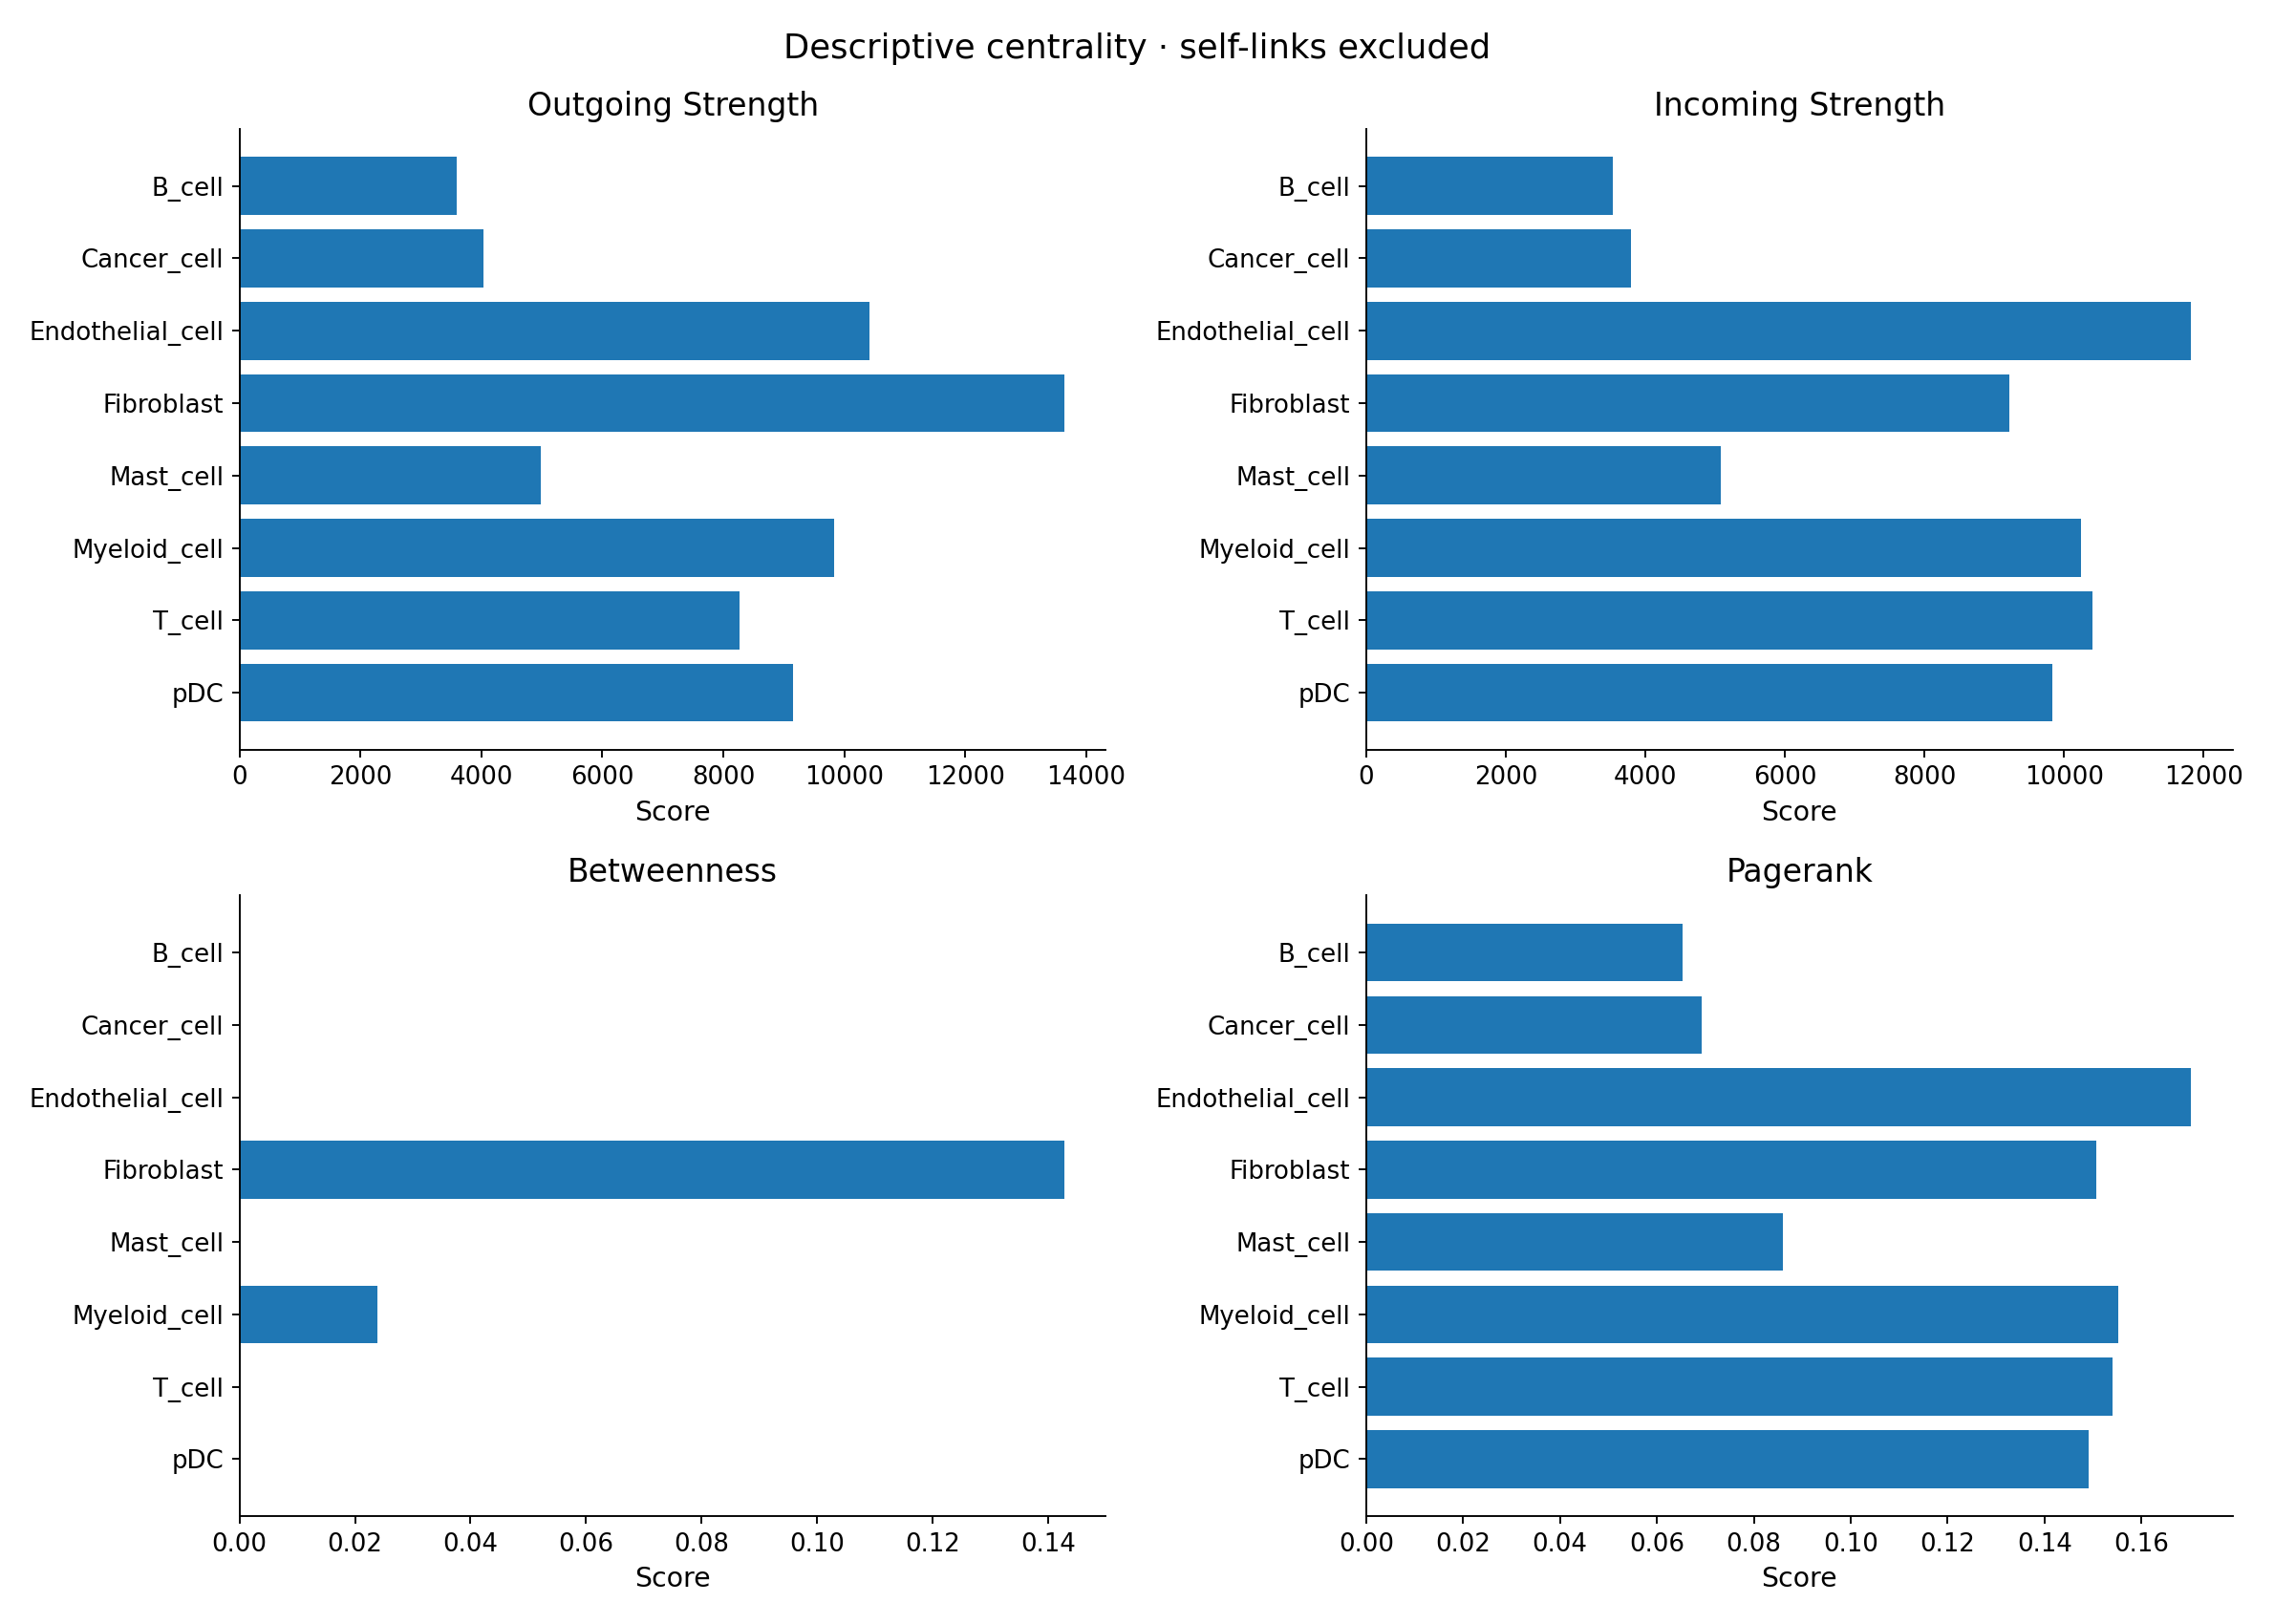

In [62]:
show_generated('signaling/inference/network_centrality.png')

Centrality uses the full positive-score network, excluding self-links. Strength sums edge scores, betweenness uses inverse score as distance, and PageRank uses score as weight. Step 2 includes self-links, so its totals differ.

## 6. Pathway example: VEGF

In [63]:
SELECTED_PATHWAY = 'VEGF'
# SELECTED_PATHWAY = 'CXCL'
# SELECTED_PATHWAY = 'TGFb'
# SELECTED_PATHWAY = 'WNT'
# SELECTED_PATHWAY = 'NOTCH'
# SELECTED_PATHWAY = 'IFN'
# SELECTED_PATHWAY = 'TNF'
frame = details.loc[details.pathway_name.astype(str) == SELECTED_PATHWAY].copy()
if frame.empty:
    raise ValueError('No interactions for ' + SELECTED_PATHWAY)
path_comm = frame.pivot_table(index='source', columns='target', values='weighted_score', aggfunc='sum', fill_value=0).reindex(index=groups, columns=groups, fill_value=0)
path_dir = base / 'signaling' / 'pathways' / SELECTED_PATHWAY

plots.plot_heatmaps(path_comm, None, path_dir, title=f'{SELECTED_PATHWAY} communication')

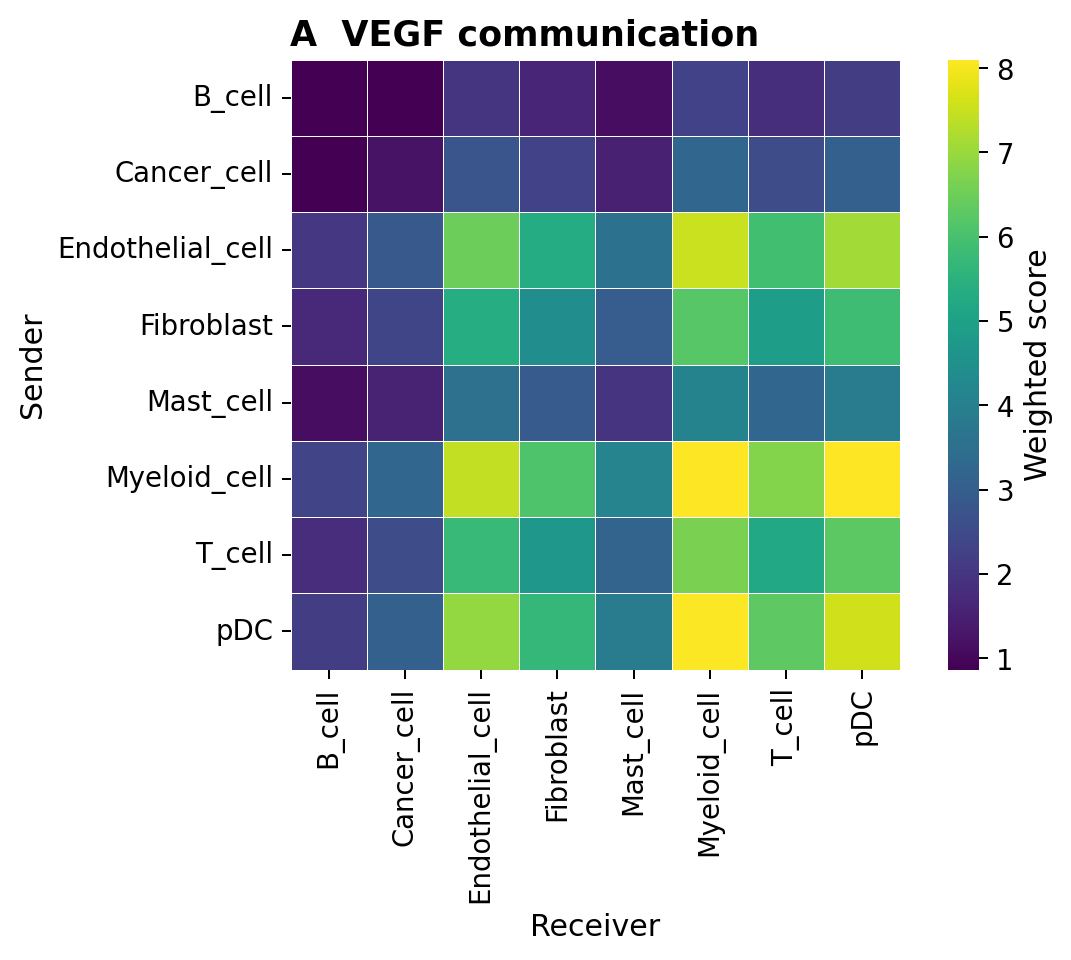

In [64]:
show_generated('signaling/pathways/VEGF/03_communication_heatmap.png')

This heatmap summarizes VEGF records from the interaction table using a pathway-specific color range. Compare pairs within this plot. Step 4’s FDR covers global totals, not this pathway; choose another available pathway using the commented alternatives.

In [65]:
plots.plot_top_lr(frame, path_dir)
# plots.plot_sender_receiver(path_comm, path_dir)
# plots.plot_flow(path_comm, path_dir)
# plots.plot_bubble(frame, groups, path_dir)
# plots.plot_network(path_comm, path_dir, title=f"{SELECTED_PATHWAY} cell-type network")

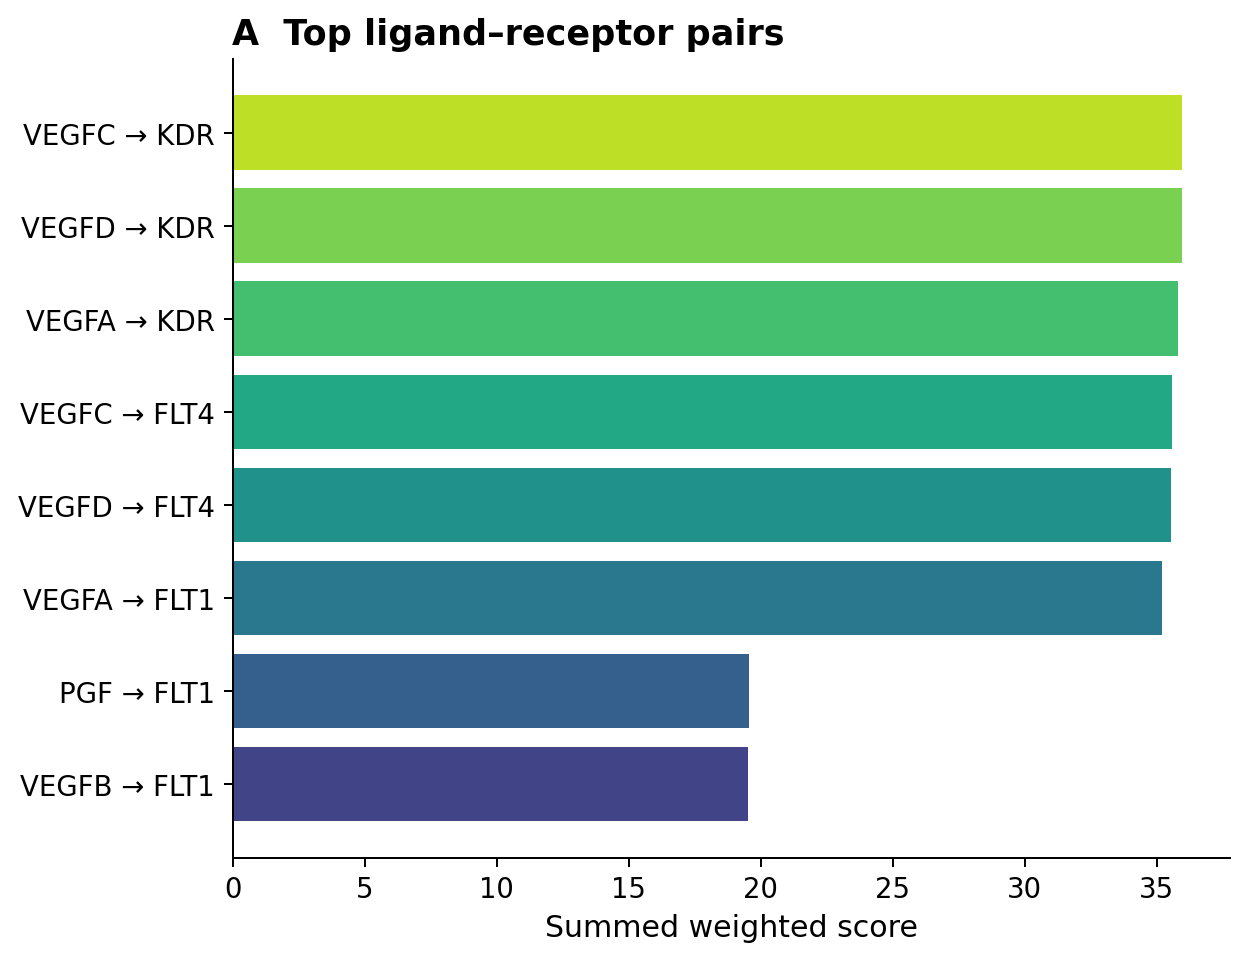

In [66]:
show_generated('signaling/pathways/VEGF/05_top_lr_pairs.png')

The ranking shows up to 15 VEGF ligand–receptor pairs by weighted score summed across cell-type pairs. It explains which interactions contribute to this pathway summary. Uncomment an alternative pathway or plotting call to explore another view.

## 7. On-minus-Pre signaling differences

Use exact timepoint labels and require at least ten cells per cell type in each condition. Pooled specificity and interaction definitions remain fixed across conditions.

In [67]:
contrast_report = {}
def draw_contrast(column, left, right, stem, title):
 matrices=[];group_counts=[]
 for condition in [left,right]:
  mask=meta[column].astype(str).eq(condition).to_numpy()
  m,c=lr.group_means(values[mask],labels[mask],len(groups));matrices.append(lr.communication_matrix(m,specificity,pairs));group_counts.append(c)
 # Require at least ten cells in each group/condition; unsupported pairs remain missing.
 eligible=(group_counts[0]>=10)&(group_counts[1]>=10)
 diff=matrices[0]-matrices[1];diff[~(eligible[:,None]&eligible[None,:])]=np.nan
 pd.DataFrame(diff,index=groups,columns=groups).to_csv(out/(stem+'.csv'))
 pd.DataFrame({left:group_counts[0],right:group_counts[1]},index=groups).to_csv(out/(stem+'_counts.csv'))
 heatmap(diff,title,stem+'.png',left+' − '+right+' weighted score',True)
 contrast_report[stem]={'excluded_cells':int((~meta[column].astype(str).isin([left,right])).sum()),'eligible_groups':list(np.array(groups)[eligible]),'counts':{left:list(map(int,group_counts[0])),right:list(map(int,group_counts[1]))}}

draw_contrast('timepoint', 'On', 'Pre', 'on_minus_pre', 'On minus Pre · pooled activity difference')
# draw_contrast('expansion', 'E', 'NE', 'expanded_minus_nonexpanded',
#               'E minus NE · clonotype expansion groups')

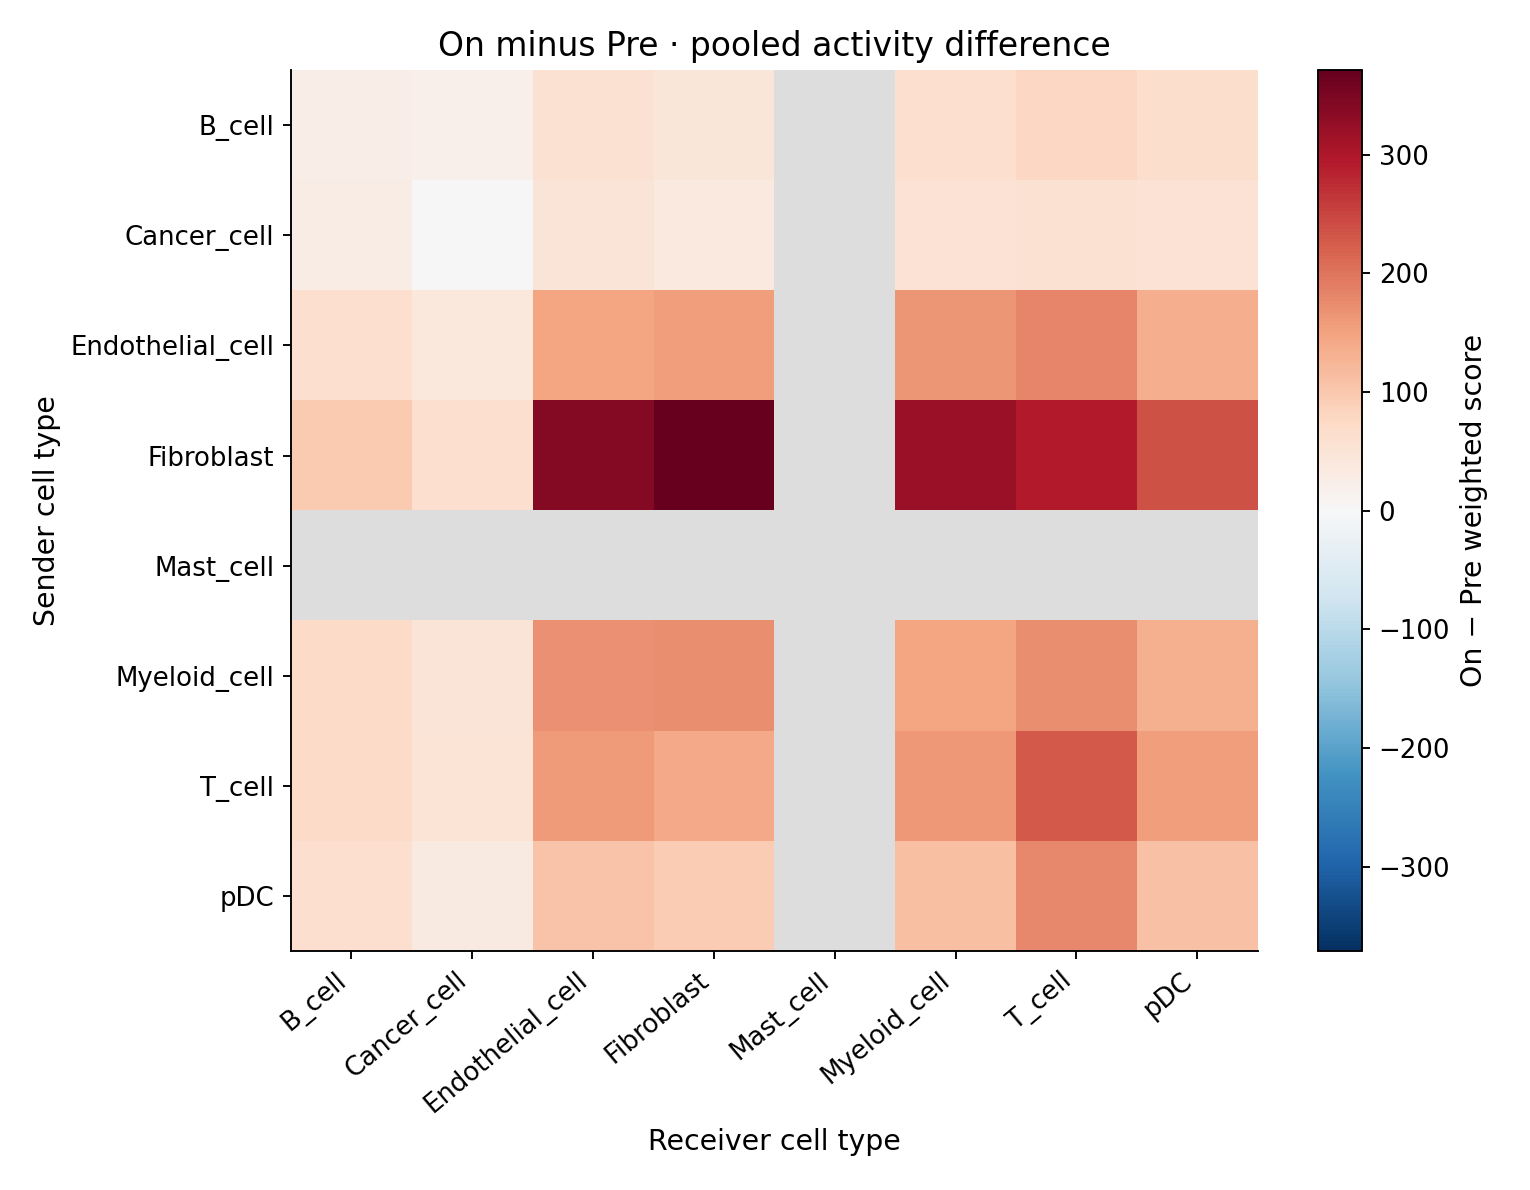

In [68]:
show_generated('signaling/inference/on_minus_pre.png')

Positive values indicate higher pooled scores On-treatment; negative values indicate higher scores Pre-treatment. Grey pairs have fewer than ten cells in one or both conditions. This descriptive contrast has no patient adjustment or contrast p-values. The E/NE alternative groups clonotype expansion, not clinical response.

## Outputs and next step

Scores and interaction tables are saved in `signaling/`; network plots in `signaling/general/`; permutation results, centrality and contrasts in `signaling/inference/`; pathway plots in `signaling/pathways/VEGF/`. For an optional extension, see [rank sensitivity and projection](../docs/tutorials/10000-validation.md).

# Optional: rank sensitivity and projection



**Input:** the saved object from [model fitting](../docs/tutorials/10000-setup.md). Use the command below to generate the projection results, or use the Python example to adjust the settings.

Split the selected sample into **8,000 training and 2,000 held-out cells**, seed 42. Fit ranks 8, 16 and 24 on training cells and project held-out expression onto each fixed `Rg @ W` basis using nonnegative least squares. The primary biological analysis remains the separate tuned fit on all 10,000 cells.

The pre-fit tuning settings supply the W/H and graph penalties. This optional split illustrates projection within the same cohort; it is not a second independent evaluation of the tuning choices. Projected H values are exported for the selected model rank.

## Rank sensitivity and projection code

In [69]:
"""Exploratory rank sensitivity and held-out projection within the tutorial sample."""
import os,time,json,resource
from pathlib import Path
os.environ['MPLBACKEND']='Agg'
import numpy as np
import pandas as pd
import scanpy as sc
import networkx as nx
import matplotlib.pyplot as plt

plt.rcParams.update({"font.size": 12, "axes.titlesize": 14,
                     "axes.labelsize": 12, "xtick.labelsize": 11,
                     "ytick.labelsize": 11, "legend.fontsize": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
from scipy.optimize import nnls
from scknife import run_full_pipeline
start=time.perf_counter()
ROOT=Path.cwd(); OUT=Path(os.environ.get('SCKNIFE_TUTORIAL_OUTPUT', ROOT/'tutorial/outputs_10000'))
adata=sc.read_h5ad(OUT/'fitted_subset.h5ad')
G=nx.read_graphml(ROOT/'graphs/version_1/unified_graph.graphml')
rng=np.random.default_rng(42); order=rng.permutation(adata.n_obs)
train=adata[order[:8000]].copy(); test=adata[order[8000:]].copy()
# Remove fitted results before fitting each training-only model.
train.uns.clear()
for col in [c for c in train.obs if c.startswith('H_graph_')]: del train.obs[col]
selected_params=json.loads((OUT/'tuning/selected_params.json').read_text())
penalties={key:selected_params[key] for key in ['lambda_reg','beta_W','beta_H']}
rows=[]; projections=[]
for rank in (8,16,24):
    model=run_full_pipeline(train.copy(),G,k=rank,**penalties,n_iter=60,tol=0,random_state=42,verbose=False)
    basis=np.asarray(model.uns['Rg'] @ model.uns['W_graph'])
    genes=model.var_names
    expression=test[:,genes].X
    expression=expression.toarray() if hasattr(expression,'toarray') else np.asarray(expression)
    predicted=np.column_stack([nnls(basis,x)[0] for x in expression])
    reconstructed=(basis@predicted).T
    error=np.linalg.norm(expression-reconstructed)/np.linalg.norm(expression)
    rows.append({'rank':rank,'training_cells':8000,'heldout_cells':2000,'relative_reconstruction_error':float(error)})
    if rank==selected_params["k"]:
        projections=pd.DataFrame(predicted.T,index=test.obs_names,columns=[f'H_projected_{i}' for i in range(rank)])
    plt.close('all')
pd.DataFrame(rows).to_csv(OUT/'rank_sensitivity.csv',index=False)
projections.to_csv(OUT/'heldout_projected_factors.csv')
fig,ax=plt.subplots(figsize=(6,4));ax.plot([r['rank'] for r in rows],[r['relative_reconstruction_error'] for r in rows],marker='o')
ax.set_xticks([8,16,24]);ax.set_xlabel('Number of factors');ax.set_ylabel('Held-out relative reconstruction error')
ax.set_title('Exploratory rank sensitivity · 2,000 held-out cells')
fig.tight_layout();fig.savefig(OUT/'rank_sensitivity.png',dpi=160);plt.close(fig)
report={'elapsed_seconds':time.perf_counter()-start,'peak_rss_kib':resource.getrusage(resource.RUSAGE_SELF).ru_maxrss,'training_cells':8000,'heldout_cells':2000,'gene_selection':'tuning fitting subset; overlaps this exploratory split', 'selected_params':selected_params,'purpose':'exploratory reconstruction diagnostic, not unbiased generalization or biological rank selection'}
(OUT/'validation_report.json').write_text(json.dumps(report,indent=2))
print(rows,report)

Starting Full scKNIFE (Graph-Regularized NMF) Pipeline...
Params - k=8, lambda=0.1, beta_W=0.001, beta_H=0.1, Iterations=60



Building gene-to-KG node mapping (Rg)...
Mapped 2000 genes to KG nodes.


Running scKNIFE Graph-Regularized NMF on CPU...


Epoch 0: Normalized Loss = 0.229343


Epoch 59: Normalized Loss = 0.188164
Storing H_graph components in adata.obs...
Stored W_graph in `adata.uns['W_graph']` (0.188164 final normalized loss)
Stored H_graph components in `adata.obs`
Running Standard NMF...


...

Epoch 0: Normalized Loss = 0.226338


Epoch 59: Normalized Loss = 0.176185
Storing H_graph components in adata.obs...
Stored W_graph in `adata.uns['W_graph']` (0.176185 final normalized loss)
Stored H_graph components in `adata.obs`
Running Standard NMF...


Storing H_std components in adata.obs...
Stored W_std in `adata.uns['W_std']`
Stored H_std components in `adata.obs`
Std NMF -> Corr: 0.7287, Frobenius: 2755.38, Relative: 0.5918



Standard NMF:
   Pearson Correlation     : 0.7287
   Frobenius Error         : 2755.3816
   Relative Frobenius Error: 0.5918

scKNIFE (Graph-Regularized NMF):
   Pearson Correlation     : 0.7276
   Frobenius Error         : 2760.1578
   Relative Frobenius Error: 0.5928

Pipeline complete!
Results stored in `adata.obs` and `adata.uns`:
   - `W_std`, `W_graph`
   - `H_std_{i}`, `H_graph_{i}`
   - `loss_history`
   - `Rg`, `node_names`



[{'rank': 8, 'training_cells': 8000, 'heldout_cells': 2000, 'relative_reconstruction_error': 0.612731160900052}, {'rank': 16, 'training_cells': 8000, 'heldout_cells': 2000, 'relative_reconstruction_error': 0.5994893558418207}, {'rank': 24, 'training_cells': 8000, 'heldout_cells': 2000, 'relative_reconstruction_error': 0.5923178744504863}] {'elapsed_seconds': 254.115433315048, 'peak_rss_kib': 7763264, 'training_cells': 8000, 'heldout_cells': 2000, 'gene_selection': 'tuning fitting subset; overlaps this exploratory split', 'selected_params': {'k': 24, 'lambda_reg': 0.1, 'beta_W': 0.001, 'beta_H': 0.1}, 'purpose': 'exploratory reconstruction diagnostic, not unbiased generalization or biological rank selection'}


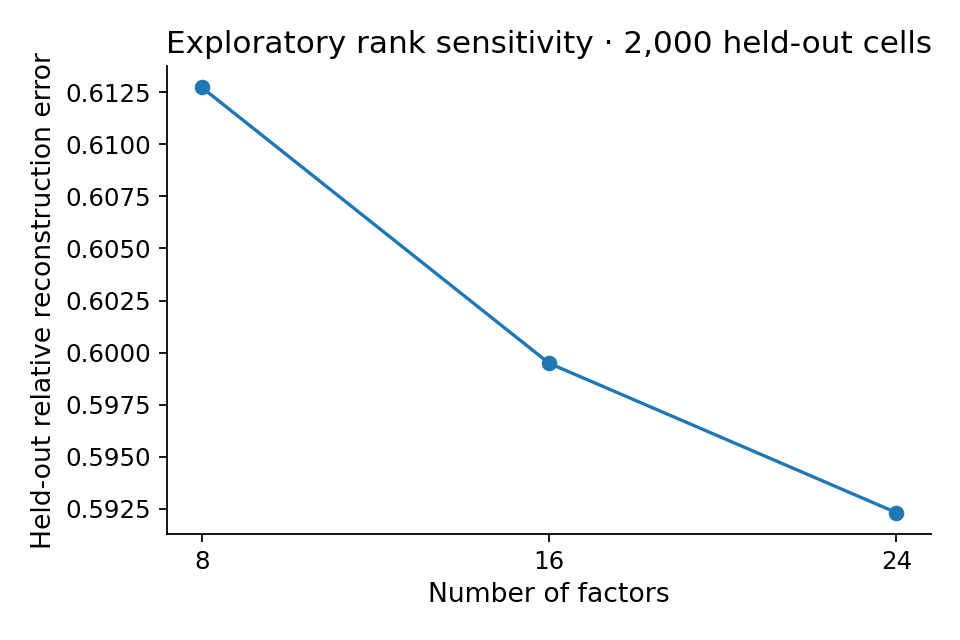

In [70]:
show_generated('rank_sensitivity.png')

Relative held-out reconstruction error across the three tested ranks.

Relative reconstruction errors are **0.61273** at rank 8, **0.59949** at rank 16 and **0.59232** at rank 24. The plot shows how reconstruction changes with factor count on this split. Because tuning and gene selection overlap the split, use it as a projection example rather than an independent performance estimate.

The x-axis is factor count and the y-axis is relative held-out reconstruction error. Lower values indicate closer reconstruction of the held-out expression.

## Save and review the primary outputs

Primary results use `fitted_subset.h5ad` and `activity_scores.parquet`, with source `cellType` metadata retained. Review `sampling_audit.csv`, `sample_metadata.csv`, and results in `metabolic_walkthrough/`, `factor_interpretation_k4/` and `signaling/`. Preserve cell identifiers and ordering when reusing these outputs.

## View the generated plots

The code saves PNGs using a non-interactive plotting backend. Open the files in your output directory, or display one in Jupyter after the analysis completes:

In [ ]:
import os
from pathlib import Path
from IPython.display import Image, display
result_dir = Path(os.environ.get("SCKNIFE_TUTORIAL_OUTPUT", "tutorial/outputs_10000"))
display(Image(filename=str(result_dir / "rank_sensitivity.png")))

## Completion

All main analyses use the same 10,000-cell fit and preserve source labels. The optional rank sensitivity and projection section uses an 8,000/2,000 split within that sample. Reuse the exported activities with biological relationships appropriate to your next question. Change the commented settings to explore pathways beyond VEGF or other condition comparisons.

See [biological resources and citations](../docs/graph-resources.md) for upstream resource details.